# Rolling Brier: 100-FIGHT windows

The main curves average the latest 100 individual fight Brier scores. Forecasts
and return correlations sample this fight-based rolling series at event end.
There is one event-end target per event; that does not change the window to events.
The correlation sections use 25, 50, 75, and 100 FIGHTS, plus an unsmoothed event
mean. Same-event and prior-event comparisons are separate. Earlier training fights
seed the windows; returns remain validation-only for the train-only opening model.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Allow Run All from the repository root or this notebook's directory.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "ufc_betting").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the SportsBetting repository")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from ufc_betting.config import settings

FIT_MODE = "trainval"    # Combined train + validation fitting cohort
MODEL_TYPE = "open"      # "open", "close1", or "close2"
ODDS_TYPE = "open"       # Vegas market to compare
PROBABILITY_MODEL = "inference"
WINDOW = 100

prediction_path = (settings.data_dir / "model_comparisons" / "lr_open_close"
                   / "report_predictions" / FIT_MODE / MODEL_TYPE / PROBABILITY_MODEL
                   / f"train_with_{ODDS_TYPE}.csv")
train = pd.read_csv(prediction_path)
if not train.probability_model.eq(PROBABILITY_MODEL).all():
    raise ValueError("Prediction probability source does not match configuration")
train["date"] = pd.to_datetime(train.date, errors="raise")
order = ["date"] + (["bout_position"] if "bout_position" in train else [])
order += ["fighter_red", "fighter_blue"]
train = train.sort_values(order, kind="stable").reset_index(drop=True)
red_price = pd.to_numeric(train[f"dec_{ODDS_TYPE}_red"], errors="coerce")
blue_price = pd.to_numeric(train[f"dec_{ODDS_TYPE}_blue"], errors="coerce")
model = pd.to_numeric(train.proba_red, errors="coerce")
valid = (train.winner.isin([0, 1]) & model.between(0, 1) & train.date.notna()
         & np.isfinite(red_price) & np.isfinite(blue_price)
         & red_price.gt(1) & blue_price.gt(1))
vegas = (1 / red_price) / (1 / red_price + 1 / blue_price)
scores = train.loc[valid, ["date", "fighter_red", "fighter_blue", "winner"]].copy()
scores["model_brier"] = (model.loc[valid] - scores.winner) ** 2
scores["vegas_brier"] = (vegas.loc[valid] - scores.winner) ** 2
if len(scores) < WINDOW:
    raise ValueError(f"Need at least {WINDOW} eligible train + validation fights")
scores["rolling_model"] = scores.model_brier.rolling(WINDOW, min_periods=WINDOW).mean()
scores["rolling_vegas"] = scores.vegas_brier.rolling(WINDOW, min_periods=WINDOW).mean()
print(f"Source: {prediction_path}")
print(f"{len(scores):,} eligible fights; {len(train) - len(scores):,} excluded; "
      f"{scores.date.min():%Y-%m-%d} to {scores.date.max():%Y-%m-%d}")
print(f"Full-period Brier â€” model: {scores.model_brier.mean():.4f}; "
      f"Vegas: {scores.vegas_brier.mean():.4f}")


Source: C:\Users\jcmar\my_files\SportsBetting\Data\model_comparisons\lr_open_close\report_predictions\trainval\open\inference\train_with_open.csv
4,658 eligible fights; 0 excluded; 2010-03-21 to 2026-02-07
Full-period Brier â€” model: 0.2137; Vegas: 0.2210


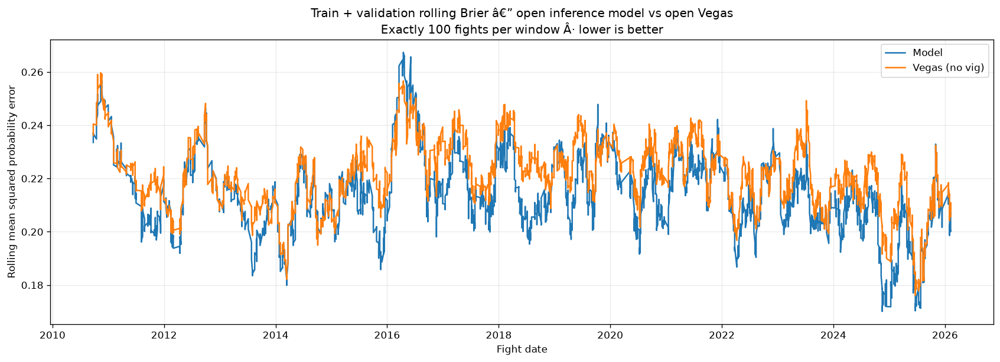

In [2]:
fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
ax.plot(scores.date, scores.rolling_model, label="Model", color="tab:blue")
ax.plot(scores.date, scores.rolling_vegas, label="Vegas (no vig)", color="tab:orange")
ax.set(title=f"Train + validation rolling Brier â€” {MODEL_TYPE} {PROBABILITY_MODEL} model vs {ODDS_TYPE} Vegas"
             f"\nExactly {WINDOW} fights per window Â· lower is better",
       xlabel="Fight date", ylabel="Rolling mean squared probability error")
locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.grid(alpha=.25)
ax.legend()
plt.show()


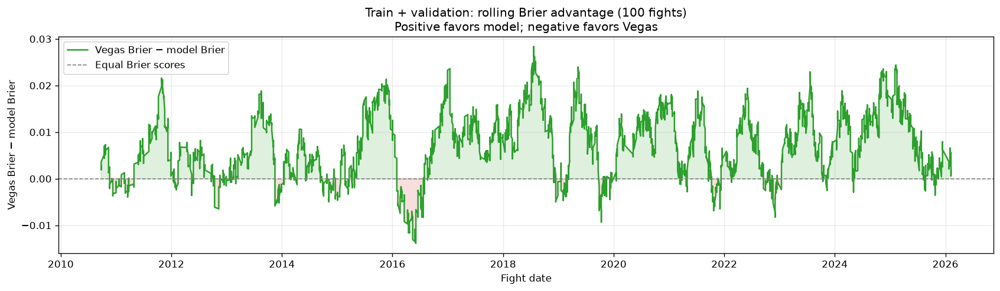

In [3]:
# Positive values mean the model has a lower (better) rolling Brier score.
scores["rolling_brier_advantage"] = scores.rolling_vegas - scores.rolling_model
fig, ax = plt.subplots(figsize=(14, 4), constrained_layout=True)
ax.plot(scores.date, scores.rolling_brier_advantage, color="tab:green",
        label="Vegas Brier − model Brier")
ax.axhline(0, color="gray", linestyle="--", linewidth=1, label="Equal Brier scores")
ax.fill_between(scores.date, 0, scores.rolling_brier_advantage,
                where=scores.rolling_brier_advantage.ge(0), color="tab:green", alpha=.15)
ax.fill_between(scores.date, 0, scores.rolling_brier_advantage,
                where=scores.rolling_brier_advantage.lt(0), color="tab:red", alpha=.15)
ax.set(title=f"Train + validation: rolling Brier advantage ({WINDOW} fights)"
             "\nPositive favors model; negative favors Vegas",
       xlabel="Fight date", ylabel="Vegas Brier − model Brier")
locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.grid(alpha=.25)
ax.legend()
plt.show()


## Rolling Brier advantage: distributions and returns above/below a five-year mean

Retain the histogram of the exact train + validation rolling advantage curve above and the split timeline. Replace this section's accuracy/return correlation plots with combined validation + test return distributions and volatility comparisons.

For each validation or test event, average event-end **100-fight rolling Brier advantage** points dated within `[event date minus 5 calendar years, event date)`. Each historical event receives equal weight. Compare the immediately previous event's advantage with that trailing mean; classify as **above** or **at/below**. Both inputs exclude current outcomes. Five years is the reference horizon, not the Brier averaging window. The reference updates before every event and includes the previous event point.

Use the matching saved strategy model: train-only opening inference for validation, trainval-refitted inference for test, including its matching historical warmup. The five-year reference therefore uses each model's own history and can change at refit. Pool 72 validation and 33 test events; show split counts within each group. Saved predictions and bankroll accounting are checked. Historical reference probabilities include in-sample fitted values; this is descriptive strategy analysis, not a clean prospective test of an allocation rule.

Return histograms use common bins and normalize each group separately; empirical cumulative distributions show the entire spread. Volatility is the sample standard deviation of event return percentages, in percentage points, without annualizing. Report mean, median, 10th/90th percentiles, losing-event fraction, and geometric mean return per event (`100 * expm1(mean(log1p(return/100)))`). Geometric mean reflects compounding and permits comparison despite unequal group sizes.

The final figure aligns pre-event advantage and its five-year reference with a standardized wealth path formed by compounding validation then test event returns from one unit, with a log y-axis and points colored by group. This links two saved strategies; it is not their raw bankroll balance or a simulation of changing stakes by group.

**Above/below the historical mean measures level, not whether the curve is rising or falling.** These plots address the requested level comparison and help inspect its relationship with growth. They do not isolate downtrend effects or establish that advantage cycles cause slower growth. Overlapping windows, shared regimes, different model fits, and repeated analysis limit inference.


Reference: equal-event mean of prior 5 calendar years of event-end 100-fight rolling advantage.
               events  validation_events  test_events  mean_return_pct  median_return_pct  std_return_pp  p10_return_pct  p90_return_pct  negative_events_pct  geometric_return_per_event_pct
regime                                                                                                                                                                                       
Above mean         53                 39           14          16.6379            23.7770        35.6613        -38.0017         53.4877              26.4151                         10.1369
At/below mean      52                 33           19          12.1051            12.5457        33.8612        -31.3659         50.1368              32.6923                          6.0914
Volatility = sample standard deviation of event returns in percentage points, not annualized.


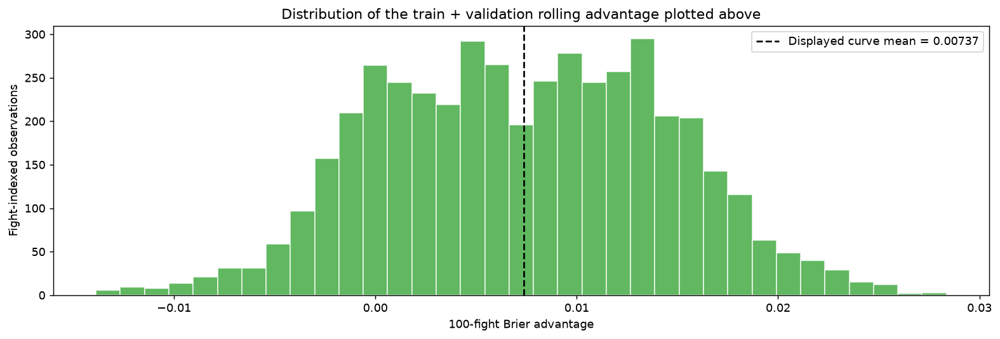

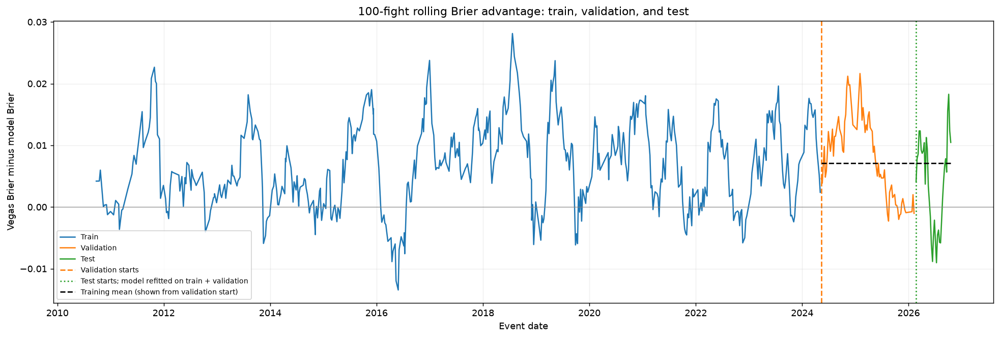

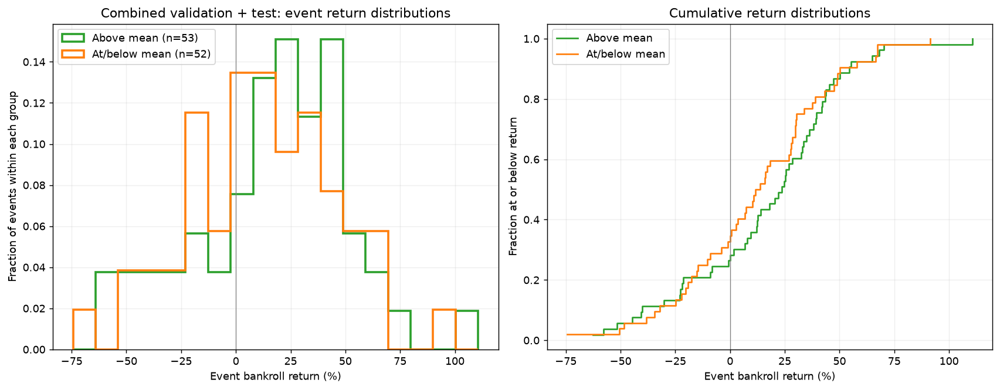

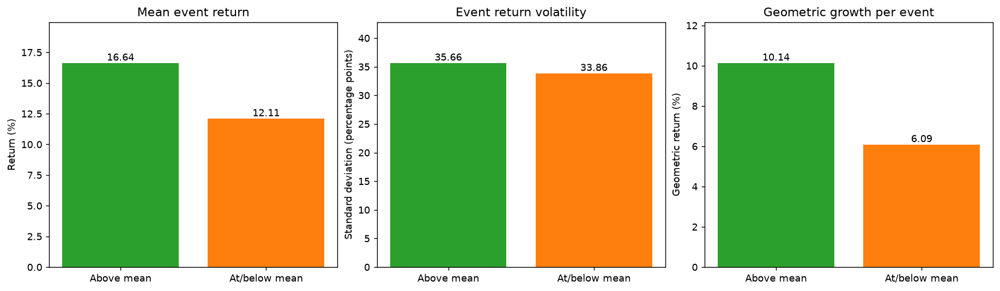

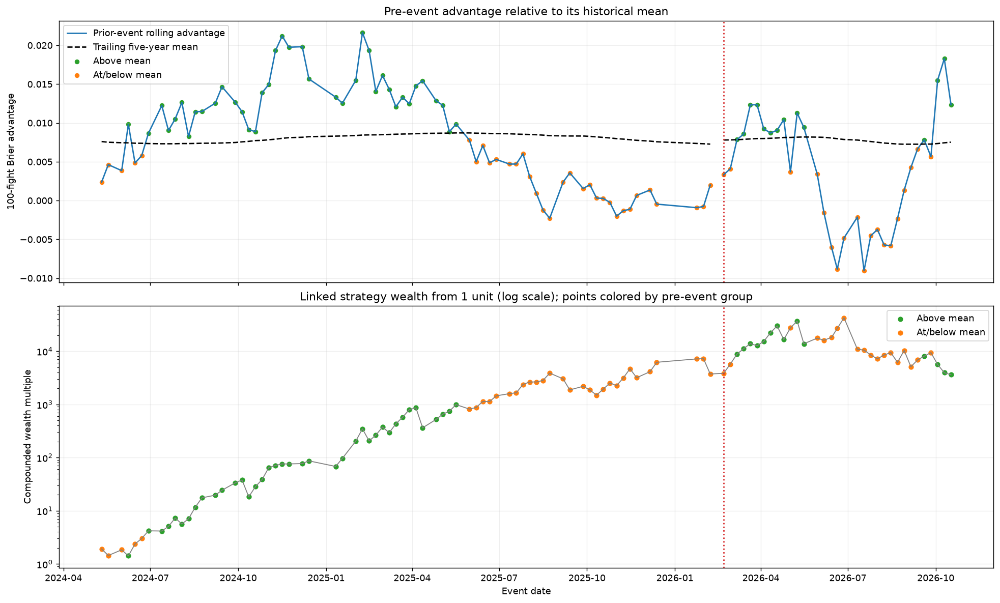

In [1]:
# Histogram of the exact train + validation curve displayed immediately above.
mean_adv_displayed = scores.rolling_brier_advantage.dropna()
fig, ax = plt.subplots(figsize=(12,4), constrained_layout=True)
ax.hist(mean_adv_displayed,bins=35,color='tab:green',alpha=.75,edgecolor='white')
ax.axvline(mean_adv_displayed.mean(),color='black',linestyle='--',label=f'Displayed curve mean = {mean_adv_displayed.mean():.5f}')
ax.set(title='Distribution of the train + validation rolling advantage plotted above',xlabel='100-fight Brier advantage',ylabel='Fight-indexed observations')
ax.legend();plt.show()

# Self-contained analysis: no dependence on later notebook cells.
from scipy.stats import pearsonr, spearmanr
MEAN_ADV_WINDOW = 100
mean_adv_root = settings.data_dir / 'model_comparisons/lr_open_close/report_predictions'
mean_adv_backtests = settings.data_dir / 'backtest_results/model_comparisons/inference_market_models'
mean_adv_keys = ['date','fighter_red','fighter_blue']

def mean_adv_score(frame):
    frame = frame.copy()
    frame['date'] = pd.to_datetime(frame.date).dt.normalize()
    model = pd.to_numeric(frame.proba_red,errors='coerce')
    red = pd.to_numeric(frame.dec_open_red,errors='coerce')
    blue = pd.to_numeric(frame.dec_open_blue,errors='coerce')
    good = frame.winner.isin([0,1]) & model.between(0,1) & np.isfinite(red) & np.isfinite(blue) & red.gt(1) & blue.gt(1)
    vegas = (1/red)/(1/red+1/blue)
    frame = frame.loc[good].copy()
    frame['advantage'] = ((vegas-frame.winner)**2-(model-frame.winner)**2).loc[good]
    frame['model_correct'] = (model.loc[good].ge(.5).astype(int)==frame.winner).astype(int)
    frame['vegas_correct'] = (vegas.loc[good].ge(.5).astype(int)==frame.winner).astype(int)
    return frame.sort_values('date',kind='stable').reset_index(drop=True)

mean_adv_train = mean_adv_score(pd.read_csv(mean_adv_root/'train/open/inference/train_with_open.csv'))
mean_adv_train['rolling_advantage'] = mean_adv_train.advantage.rolling(MEAN_ADV_WINDOW,min_periods=MEAN_ADV_WINDOW).mean()
mean_adv_training_mean = mean_adv_train.rolling_advantage.mean()
mean_adv_training_end = mean_adv_train.date.max()
mean_adv_train_endpoints = mean_adv_train.groupby('date').rolling_advantage.last()
mean_adv_train['prior_event_advantage'] = mean_adv_train.date.map(mean_adv_train_endpoints.shift(1))
mean_adv_return_pairs={};mean_adv_corr_rows=[];mean_adv_histories={}
for split,fit,prefix,prediction_split in [('Validation','train','train_val','val'),('Test','trainval','trainval_test','test')]:
    base=mean_adv_root/fit/'open/inference'
    warm=mean_adv_score(pd.read_csv(base/'train_with_open.csv'))
    prediction=pd.read_csv(base/f'{prediction_split}_with_open.csv',parse_dates=['date'])
    saved=pd.read_csv(mean_adv_backtests/f'{prefix}_open_with_open_inference_no_decay_moneylines.csv',parse_dates=['date'])
    for frame in [prediction,saved]:frame['date']=frame.date.dt.normalize()
    matched=saved.merge(prediction[mean_adv_keys+['proba_red','dec_open_red','dec_open_blue']],
        on=mean_adv_keys,how='outer',validate='one_to_one',indicator=True,suffixes=('','_reference'))
    assert matched['_merge'].eq('both').all()
    reference_model=matched['proba_red_reference'] if 'proba_red_reference' in matched else matched.proba_red
    np.testing.assert_allclose(matched.choice_proba.where(matched.pred_winner.eq(1),1-matched.choice_proba),reference_model,atol=1e-10)
    # Preserve saved within-event order exactly as in preceding correlation analyses.
    ordered=saved[mean_adv_keys].merge(prediction,on=mean_adv_keys,validate='one_to_one',sort=False)
    current=mean_adv_score(ordered)
    assert warm.date.max()<current.date.min()
    history=pd.concat([warm,current],ignore_index=True).sort_values('date',kind='stable').reset_index(drop=True)
    history['rolling_advantage']=history.advantage.rolling(MEAN_ADV_WINDOW,min_periods=MEAN_ADV_WINDOW).mean()
    # Same original training calendar period for both baselines, using each strategy's matching model.
    reference_mean=history.loc[history.date<=mean_adv_training_end,'rolling_advantage'].mean()
    if split=='Validation':np.testing.assert_allclose(reference_mean,mean_adv_training_mean,atol=1e-12)
    endpoints=history.groupby('date').rolling_advantage.last()
    cols=['bankroll_postevent','event_payout_money_line','parlay_net']
    assert saved.groupby('date')[cols].nunique(dropna=False).le(1).all().all()
    event=saved.groupby('date')[cols].first().sort_index()
    profit=event.event_payout_money_line+event.parlay_net
    start=event.bankroll_postevent-profit
    assert start.gt(0).all()
    np.testing.assert_allclose(start.iloc[1:],event.bankroll_postevent.iloc[:-1],rtol=1e-8,atol=1e-8)
    pair=pd.DataFrame({'prior_advantage':endpoints.shift(1),'feature_date':pd.Series(endpoints.index,index=endpoints.index).shift(1)})
    pair=pair.reindex(event.index)
    pair['return_pct']=100*profit/start
    pair['signed_distance']=pair.prior_advantage-reference_mean
    pair['absolute_distance']=pair.signed_distance.abs()
    assert pair.notna().all().all() and (pair.feature_date<pair.index).all()
    mean_adv_return_pairs[split]=pair;mean_adv_histories[split]=history
# One event-end point per event; each split uses its matching fitted strategy model.
mean_adv_timeline_parts=[]
for split,history in [('Train',mean_adv_histories['Validation']),
                      ('Validation',mean_adv_histories['Validation']),('Test',mean_adv_histories['Test'])]:
    events=history.groupby('date').agg(rolling_advantage=('rolling_advantage','last'),
        model_accuracy=('model_correct','mean'),fights=('model_correct','size'))
    events['prior_advantage']=events.rolling_advantage.shift(1)
    events['feature_date']=pd.Series(events.index,index=events.index).shift(1)
    if split=='Train':events=events.loc[events.index<=mean_adv_training_end]
    else:events=events.reindex(mean_adv_return_pairs[split].index)
    events['split']=split
    mean_adv_timeline_parts.append(events)
mean_adv_event_data=pd.concat(mean_adv_timeline_parts).sort_index()
validation_start=mean_adv_return_pairs['Validation'].index.min()
test_start=mean_adv_return_pairs['Test'].index.min()
fig,ax=plt.subplots(figsize=(15,5),constrained_layout=True)
for split,color in [('Train','tab:blue'),('Validation','tab:orange'),('Test','tab:green')]:
    points=mean_adv_event_data.loc[mean_adv_event_data.split.eq(split)]
    ax.plot(points.index,points.rolling_advantage,color=color,label=split,linewidth=1.4)
ax.axvline(validation_start,color='tab:orange',linestyle='--',label='Validation starts')
ax.axvline(test_start,color='tab:green',linestyle=':',label='Test starts; model refitted on train + validation')
ax.hlines(mean_adv_training_mean,validation_start,mean_adv_event_data.index.max(),
    colors='black',linestyles='--',label='Training mean (shown from validation start)')
ax.axhline(0,color='gray',linewidth=.6)
ax.set(title='100-fight rolling Brier advantage: train, validation, and test',
       xlabel='Event date',ylabel='Vegas Brier minus model Brier')
ax.legend(fontsize=8);ax.grid(alpha=.2);plt.show()

# Classify each event using only its preceding five calendar years of event-end points.
regime_parts=[]
for split,pair in mean_adv_return_pairs.items():
    endpoints=mean_adv_histories[split].groupby('date').rolling_advantage.last().dropna()
    part=pair[['prior_advantage','feature_date','return_pct']].copy()
    references=[];counts=[]
    for date in part.index:
        start_date=date-pd.DateOffset(years=5)
        historical=endpoints.loc[(endpoints.index>=start_date)&(endpoints.index<date)]
        assert len(historical)>0 and historical.index.max()<date
        references.append(historical.mean());counts.append(len(historical))
    part['five_year_mean']=references
    part['reference_events']=counts
    part['regime']=np.where(part.prior_advantage>part.five_year_mean,'Above mean','At/below mean')
    part['split']=split
    regime_parts.append(part)
mean_adv_regimes=pd.concat(regime_parts).sort_index()
assert mean_adv_regimes.index.is_unique and len(mean_adv_regimes)==105
assert (mean_adv_regimes.feature_date<mean_adv_regimes.index).all()
assert mean_adv_regimes.return_pct.gt(-100).all()
mean_adv_regimes['log_growth']=np.log1p(mean_adv_regimes.return_pct/100)
regime_rows=[]
for label,part in mean_adv_regimes.groupby('regime',sort=False):
    returns=part.return_pct
    regime_rows.append({'regime':label,'events':len(part),
        'validation_events':int(part.split.eq('Validation').sum()),'test_events':int(part.split.eq('Test').sum()),
        'mean_return_pct':returns.mean(),'median_return_pct':returns.median(),
        'std_return_pp':returns.std(ddof=1),'p10_return_pct':returns.quantile(.1),
        'p90_return_pct':returns.quantile(.9),'negative_events_pct':100*returns.lt(0).mean(),
        'geometric_return_per_event_pct':100*np.expm1(part.log_growth.mean())})
mean_adv_regime_summary=pd.DataFrame(regime_rows).set_index('regime').reindex(['Above mean','At/below mean'])
print('Reference: equal-event mean of prior 5 calendar years of event-end 100-fight rolling advantage.')
print(mean_adv_regime_summary.to_string(float_format=lambda x:f'{x:.4f}'))
print('Volatility = sample standard deviation of event returns in percentage points, not annualized.')

regime_colors={'Above mean':'tab:green','At/below mean':'tab:orange'}
fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
bins=np.histogram_bin_edges(mean_adv_regimes.return_pct,bins=18)
for label,color in regime_colors.items():
    values=mean_adv_regimes.loc[mean_adv_regimes.regime.eq(label),'return_pct']
    axes[0].hist(values,bins=bins,weights=np.ones(len(values))/len(values),
        histtype='step',linewidth=2,color=color,label=f'{label} (n={len(values)})')
    ordered=np.sort(values)
    axes[1].step(ordered,np.arange(1,len(ordered)+1)/len(ordered),where='post',color=color,label=label)
axes[0].set(title='Combined validation + test: event return distributions',xlabel='Event bankroll return (%)',ylabel='Fraction of events within each group')
axes[1].set(title='Cumulative return distributions',xlabel='Event bankroll return (%)',ylabel='Fraction at or below return')
for ax in axes:ax.axvline(0,color='gray',lw=.7);ax.legend();ax.grid(alpha=.2)
plt.show()

fig,axes=plt.subplots(1,3,figsize=(14,4),constrained_layout=True)
for ax,col,title,ylabel in zip(axes,['mean_return_pct','std_return_pp','geometric_return_per_event_pct'],
        ['Mean event return','Event return volatility','Geometric growth per event'],
        ['Return (%)','Standard deviation (percentage points)','Geometric return (%)']):
    values=mean_adv_regime_summary[col]
    bars=ax.bar(values.index,values,color=[regime_colors[k] for k in values.index])
    ax.bar_label(bars,fmt='%.2f');ax.axhline(0,color='gray',lw=.6)
    ax.set(title=title,ylabel=ylabel);ax.margins(y=.2)
plt.show()

fig,axes=plt.subplots(2,1,figsize=(15,9),sharex=True,constrained_layout=True)
# Draw splits separately to expose the model change instead of bridging it invisibly.
for split,part in mean_adv_regimes.groupby('split',sort=False):
    axes[0].plot(part.index,part.prior_advantage,color='tab:blue',label='Prior-event rolling advantage' if split=='Validation' else None)
    axes[0].plot(part.index,part.five_year_mean,color='black',linestyle='--',label='Trailing five-year mean' if split=='Validation' else None)
for label,color in regime_colors.items():
    part=mean_adv_regimes.loc[mean_adv_regimes.regime.eq(label)]
    axes[0].scatter(part.index,part.prior_advantage,color=color,s=18,label=label)
axes[0].set(title='Pre-event advantage relative to its historical mean',ylabel='100-fight Brier advantage');axes[0].legend()
# Standardized linked wealth path: descriptive compounding of the two saved strategy series.
mean_adv_regimes['linked_wealth']=np.exp(mean_adv_regimes.log_growth.cumsum())
axes[1].plot(mean_adv_regimes.index,mean_adv_regimes.linked_wealth,color='gray',lw=1)
for label,color in regime_colors.items():
    part=mean_adv_regimes.loc[mean_adv_regimes.regime.eq(label)]
    axes[1].scatter(part.index,part.linked_wealth,color=color,s=22,label=label)
axes[1].set_yscale('log')
axes[1].set(title='Linked strategy wealth from 1 unit (log scale); points colored by pre-event group',
    ylabel='Compounded wealth multiple',xlabel='Event date')
axes[1].legend()
for ax in axes:
    ax.axvline(test_start,color='tab:red',linestyle=':',label='Test/refit boundary');ax.grid(alpha=.2)
plt.show()


### Largest validation and test event losses above/below the historical mean

Rank negative event bankroll percentage returns from worst upward. Default: the 10 largest losses pooled across validation and test, with split counts and an event listing. Also report up to 10 worst losses within each split (fewer if that split has fewer than 10 losing events). Reuse the exact prior-event advantage versus trailing five-calendar-year mean classification above; no current outcomes enter that label. Counts are descriptive and use percentage losses rather than dollar losses. Change `BIGGEST_LOSSES_N` to adjust the cutoff.


In [1]:
# Largest losses use event bankroll percentage return, not dollar loss.
BIGGEST_LOSSES_N = 10
loss_events = mean_adv_regimes.loc[mean_adv_regimes.return_pct.lt(0)].copy()
loss_events['distance_from_mean'] = loss_events.prior_advantage-loss_events.five_year_mean
largest_losses = loss_events.sort_values('return_pct',kind='stable').head(BIGGEST_LOSSES_N)
loss_count_rows=[]
for scope,part in [('Combined',largest_losses),('Validation',largest_losses.loc[largest_losses.split.eq('Validation')]),
                   ('Test',largest_losses.loc[largest_losses.split.eq('Test')])]:
    loss_count_rows.append({'selection':'10 largest losses pooled','split':scope,'loss_events':len(part),
        'above_mean':int(part.regime.eq('Above mean').sum()),'at_or_below_mean':int(part.regime.eq('At/below mean').sum())})
# Also show each split's own worst losses, since the pooled selection can favor one split.
for split in ['Validation','Test']:
    part=loss_events.loc[loss_events.split.eq(split)].sort_values('return_pct',kind='stable').head(BIGGEST_LOSSES_N)
    loss_count_rows.append({'selection':'Up to 10 largest losses within split','split':split,'loss_events':len(part),
        'above_mean':int(part.regime.eq('Above mean').sum()),'at_or_below_mean':int(part.regime.eq('At/below mean').sum())})
loss_counts = pd.DataFrame(loss_count_rows)
print('Largest losses ranked by most negative event return percentage:')
print(loss_counts.to_string(index=False))
print('\n10 largest losses across validation + test:')
print(largest_losses[['split','return_pct','regime','prior_advantage','five_year_mean','distance_from_mean']].to_string(float_format=lambda x:f'{x:.5f}'))
print('\nAll losing events (context):')
loss_context = mean_adv_regimes.groupby('regime').agg(events=('return_pct','size'),losing_events=('return_pct',lambda x:int(x.lt(0).sum())))
loss_context['loss_rate_pct']=100*loss_context.losing_events/loss_context.events
print(loss_context.to_string(float_format=lambda x:f'{x:.2f}'))


Largest losses ranked by most negative event return percentage:
                           selection      split  loss_events  above_mean  at_or_below_mean
            10 largest losses pooled   Combined           10           6                 4
            10 largest losses pooled Validation            5           3                 2
            10 largest losses pooled       Test            5           3                 2
Up to 10 largest losses within split Validation           10           5                 5
Up to 10 largest losses within split       Test           10           5                 5

10 largest losses across validation + test:
                 split  return_pct         regime  prior_advantage  five_year_mean  distance_from_mean
date                                                                                                  
2026-07-11        Test   -74.31494  At/below mean         -0.00213         0.00779            -0.00993
2026-05-16        Test   -62.49649  

### Moneyline/parlay accuracy and pre-event advantage trend

Reuse the same five-year historical-mean classifications. Report equal-event mean accuracy and pooled wins/bets separately. Moneylines count only positive-stake (`choice_fstar > 0`) settled bets; parlay legs count positive-stake settled legs. Whole parlay tickets are grouped once per date and strategy (the saved files contain one ticket per such group); positive net odds count as wins and negative net odds as losses, with zero-net/refunded tickets excluded. Void fights are excluded from leg and moneyline accuracy. Events without eligible bets are omitted from that accuracy denominator, not counted as losses. All-model-choice accuracy also includes eligible predictions with no moneyline stake.

For a practical continuous trend metric, smooth event-end 100-fight advantage with a trailing **5-event EWMA**, then fit a straight line to the latest **5 smoothed event points**. Its signed coefficient is slope in Brier advantage per event. Shift all features to the following event, so no current results enter them. Normalize slope by the standard deviation of the smoothed series over the original training period for each fitted model. Report raw and normalized slope correlations separately for validation, test, and their pooled sample.

A fixed descriptive flat band is +/-0.02 training SD per event; above it is uptrend and below it is downtrend. This threshold and smoothing lengths are not optimized on returns. They are adjustable sensitivity choices, not statistically proven regimes. Direction is distinct from level: `position_z = (pre-event smoothed advantage - trailing five-year mean)/training SD` measures how high or low the signal sits relative to history, not its oscillatory phase or proximity to a future turning point. Show both metrics and a cross-tabulation of level and direction.

Training histories contain in-sample probabilities, and the test model is refitted. Repeated analysis, overlapping features, and small groups make correlations and return differences exploratory; no significance claim is made. No correlation scatter plots are reintroduced.


COMBINED VALIDATION + TEST ACCURACY:
                                     eligible_events  mean_event_accuracy_pct  wins  bets  pooled_accuracy_pct
regime        type                                                                                            
Above mean    All model choices                   53                   69.537   330   478               69.038
              Placed moneylines                   50                   73.571   116   169               68.639
              Placed parlay legs                  52                   73.077    75   103               72.816
              Placed parlay tickets               51                   54.902    28    51               54.902
At/below mean All model choices                   52                   72.597   343   477               71.908
              Placed moneylines                   52                   70.032    94   138               68.116
              Placed parlay legs                  52                   74.0

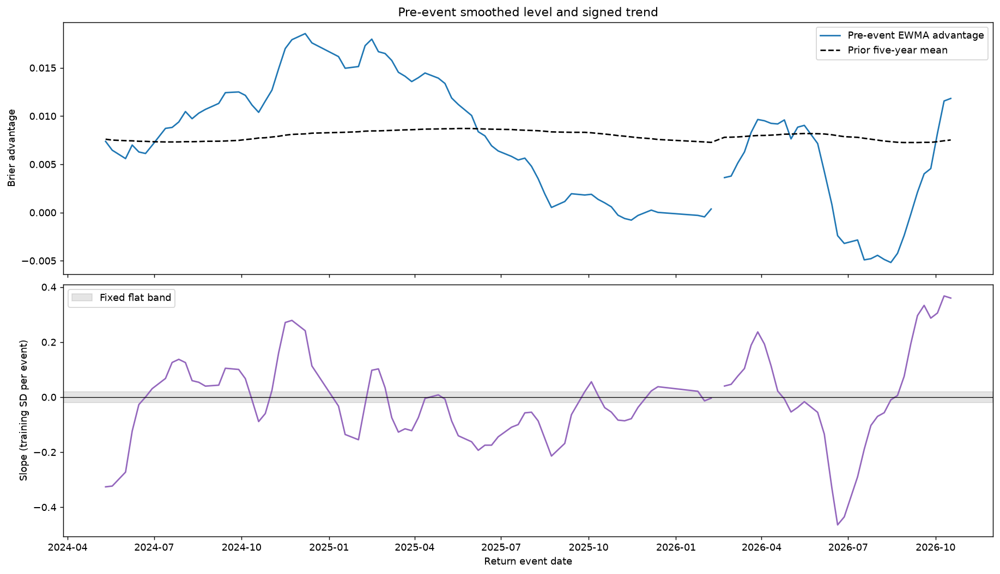

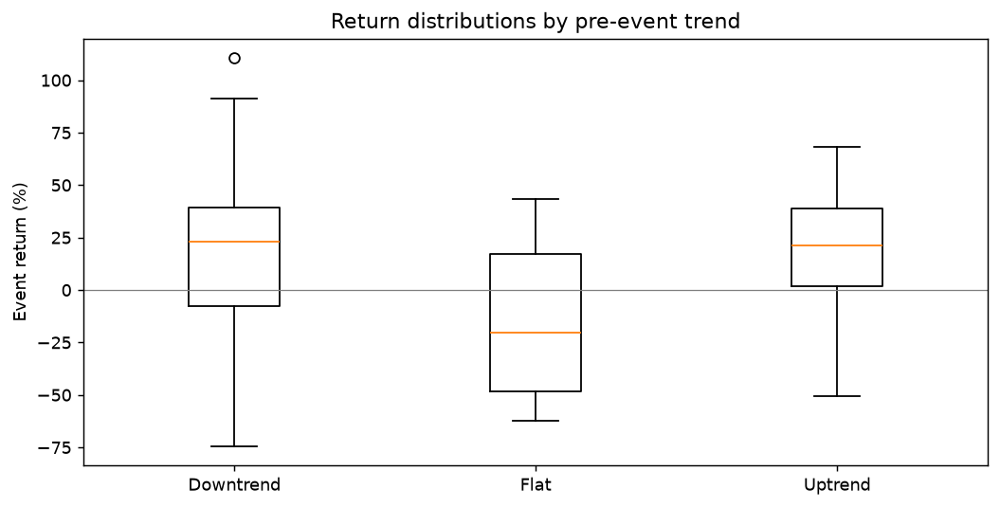

In [1]:
# Accuracy by historical-mean group; count placed bets, not candidate rows.
accuracy_event_rows=[]
for split,prefix in [('Validation','train_val'),('Test','trainval_test')]:
    ml=pd.read_csv(mean_adv_backtests/f'{prefix}_open_with_open_inference_no_decay_moneylines.csv',parse_dates=['date'])
    pl=pd.read_csv(mean_adv_backtests/f'{prefix}_open_with_open_inference_no_decay_parlays.csv',parse_dates=['date'])
    for frame in [ml,pl]:frame['date']=frame.date.dt.normalize()
    # One ticket per event and strategy, represented by multiple leg rows.
    ticket_groups=pl.loc[pl.fstar_parlay.gt(0)].groupby(['date','parlay_strategy'])
    assert ticket_groups.parlay_net_odds.nunique(dropna=False).le(1).all()
    tickets=ticket_groups.parlay_net_odds.first().reset_index()
    for date,group in ml.groupby('date'):
        settled=group.loc[group.winner.isin([0,1])]
        placed=settled.loc[settled.choice_fstar.gt(0)]
        legs=pl.loc[pl.date.eq(date)&pl.fstar_parlay.gt(0)&pl.winner.isin([0,1])]
        active=tickets.loc[tickets.date.eq(date)&tickets.parlay_net_odds.ne(0)]
        for label,wins,total in [
            ('All model choices',int(settled.pred_winner.eq(settled.winner).sum()),len(settled)),
            ('Placed moneylines',int(placed.pred_winner.eq(placed.winner).sum()),len(placed)),
            ('Placed parlay legs',int(legs.pred_winner.eq(legs.winner).sum()),len(legs)),
            ('Placed parlay tickets',int(active.parlay_net_odds.gt(0).sum()),len(active))]:
            accuracy_event_rows.append({'date':date,'split':split,'type':label,'wins':wins,'bets':total,
                'event_accuracy_pct':100*wins/total if total else np.nan})
regime_accuracy_events=pd.DataFrame(accuracy_event_rows).join(mean_adv_regimes.regime,on='date')
assert regime_accuracy_events.regime.notna().all()
regime_accuracy_summary=regime_accuracy_events.groupby(['regime','type']).agg(
    eligible_events=('event_accuracy_pct','count'),mean_event_accuracy_pct=('event_accuracy_pct','mean'),
    wins=('wins','sum'),bets=('bets','sum'))
regime_accuracy_summary['pooled_accuracy_pct']=100*regime_accuracy_summary.wins/regime_accuracy_summary.bets
print('COMBINED VALIDATION + TEST ACCURACY:')
print(regime_accuracy_summary.to_string(float_format=lambda x:f'{x:.3f}'))

# Smoothed direction AND level; all features stop before the target event.
TREND_EWMA_SPAN=5
TREND_SLOPE_EVENTS=5
FLAT_SLOPE_SD_PER_EVENT=.02  # <0.1 historical SD of change over five events.
trend_parts=[]
for split,pair in mean_adv_return_pairs.items():
    endpoint=mean_adv_histories[split].groupby('date').rolling_advantage.last().dropna()
    smooth=endpoint.ewm(span=TREND_EWMA_SPAN,adjust=False).mean()
    t=np.arange(TREND_SLOPE_EVENTS,dtype=float);t-=t.mean()
    slope=smooth.rolling(TREND_SLOPE_EVENTS).apply(lambda x:np.dot(t,x)/np.dot(t,t),raw=True)
    historical_sd=smooth.loc[smooth.index<=mean_adv_training_end].std(ddof=1)
    assert historical_sd>0
    features=pd.DataFrame({'smoothed_advantage':smooth,'slope':slope,'slope_sd_per_event':slope/historical_sd})
    features['source_date']=features.index
    features=features.shift(1).reindex(pair.index)
    assert (features.source_date<features.index).all()
    features['return_pct']=pair.return_pct
    features['split']=split
    features['position_z']=(features.smoothed_advantage-mean_adv_regimes.loc[pair.index,'five_year_mean'])/historical_sd
    features['trend']=np.select([features.slope_sd_per_event>FLAT_SLOPE_SD_PER_EVENT,
        features.slope_sd_per_event < -FLAT_SLOPE_SD_PER_EVENT],['Uptrend','Downtrend'],default='Flat')
    trend_parts.append(features)
regime_trend_data=pd.concat(trend_parts).sort_index()
assert regime_trend_data.notna().all().all()
trend_corr_rows=[]
for split,part in [('Combined',regime_trend_data),*list(regime_trend_data.groupby('split'))]:
    for feature in ['slope','slope_sd_per_event','position_z']:
        trend_corr_rows.append({'split':split,'feature':feature,'events':len(part),
            'Pearson_r':pearsonr(part[feature],part.return_pct).statistic,
            'Spearman_rho':spearmanr(part[feature],part.return_pct).statistic})
trend_correlations=pd.DataFrame(trend_corr_rows)
print('\nPRE-EVENT TREND CORRELATIONS:')
print(trend_correlations.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
trend_summary=regime_trend_data.groupby('trend').agg(events=('return_pct','size'),
    mean_return_pct=('return_pct','mean'),median_return_pct=('return_pct','median'),volatility_pp=('return_pct','std'))
trend_summary['geometric_return_pct']=regime_trend_data.groupby('trend').return_pct.apply(lambda x:100*np.expm1(np.log1p(x/100).mean()))
print('\nRETURN BY PRE-EVENT TREND:')
print(trend_summary.to_string(float_format=lambda x:f'{x:.3f}'))
print('\nLEVEL AND DIRECTION TOGETHER:')
print(regime_trend_data.join(mean_adv_regimes[['regime']]).groupby(['regime','trend']).return_pct.agg(['count','mean','median']).to_string(float_format=lambda x:f'{x:.3f}'))
fig,axes=plt.subplots(2,1,figsize=(14,8),sharex=True,constrained_layout=True)
for split,part in regime_trend_data.groupby('split',sort=False):
    axes[0].plot(part.index,part.smoothed_advantage,color='tab:blue',label='Pre-event EWMA advantage' if split=='Validation' else None)
    axes[1].plot(part.index,part.slope_sd_per_event,color='tab:purple')
axes[0].plot(mean_adv_regimes.index,mean_adv_regimes.five_year_mean,'k--',label='Prior five-year mean')
axes[0].set(ylabel='Brier advantage',title='Pre-event smoothed level and signed trend');axes[0].legend()
axes[1].axhspan(-FLAT_SLOPE_SD_PER_EVENT,FLAT_SLOPE_SD_PER_EVENT,color='gray',alpha=.2,label='Fixed flat band')
axes[1].axhline(0,color='black',lw=.7)
axes[1].set(ylabel='Slope (training SD per event)',xlabel='Return event date');axes[1].legend()
plt.show()
fig,ax=plt.subplots(figsize=(8,4),constrained_layout=True)
labels=['Downtrend','Flat','Uptrend']
ax.boxplot([regime_trend_data.loc[regime_trend_data.trend.eq(k),'return_pct'] for k in labels],tick_labels=labels)
ax.set(ylabel='Event return (%)',title='Return distributions by pre-event trend');ax.axhline(0,color='gray',lw=.7)
plt.show()


### Normalized slope bands: +/-0.02, +/-0.03, and +/-0.05

Compare three alternative flat thresholds while preserving the 5-event EWMA and 5-point slope calculation. For each threshold h: downtrend is slope < -h, flat includes -h through +h, and uptrend is slope > +h. Slope units are training standard deviations per event. Each threshold partitions the same 105 validation + test events.

Report mean return, sample standard deviation of returns (percentage points), percentage of events with positive bankroll returns, and mean event model prediction accuracy (correctly predicted settled fights divided by settled fights, then averaged equally across events). Event profit and fighter prediction accuracy are different quantities. These exploratory thresholds have not been selected or validated as a trading rule.


In [1]:
# Sensitivity to the flat-band width; keep smoothing, forecasts, and returns unchanged.
SLOPE_FLAT_THRESHOLDS = [.02,.03,.05]
slope_band_sample = regime_trend_data.copy()
event_choice_accuracy = regime_accuracy_events.loc[
    regime_accuracy_events['type'].eq('All model choices')].set_index('date').event_accuracy_pct
assert event_choice_accuracy.index.is_unique
slope_band_sample['event_prediction_accuracy_pct'] = event_choice_accuracy.reindex(slope_band_sample.index)
assert slope_band_sample.event_prediction_accuracy_pct.notna().all()
slope_band_rows=[]
for threshold in SLOPE_FLAT_THRESHOLDS:
    band = np.select([slope_band_sample.slope_sd_per_event > threshold,
        slope_band_sample.slope_sd_per_event < -threshold],['Uptrend','Downtrend'],default='Flat')
    for label in ['Downtrend','Flat','Uptrend']:
        part=slope_band_sample.loc[band==label]
        interval = (f'slope < -{threshold:.2f}' if label=='Downtrend' else
                    f'slope > +{threshold:.2f}' if label=='Uptrend' else
                    f'-{threshold:.2f} <= slope <= +{threshold:.2f}')
        slope_band_rows.append({'threshold':threshold,'trend':label,'interval':interval,'events':len(part),
            'mean_return_pct':part.return_pct.mean(),
            'volatility_pp':part.return_pct.std(ddof=1),
            'profitable_events_pct':100*part.return_pct.gt(0).mean(),
            'mean_event_prediction_accuracy_pct':part.event_prediction_accuracy_pct.mean()})
slope_band_summary=pd.DataFrame(slope_band_rows)
print(slope_band_summary.to_string(index=False,float_format=lambda x:f'{x:.3f}'))
print('Profitable events: event return > 0. Prediction accuracy: equal-event mean of correctly predicted fights / settled fights.')
print('Volatility: sample standard deviation of event returns, percentage points. These are alternative flat-band definitions, not disjoint bins across thresholds.')


 threshold     trend                interval  events  mean_return_pct  volatility_pp  profitable_events_pct  mean_event_prediction_accuracy_pct
     0.020 Downtrend           slope < -0.02      50           18.663         35.273                 70.000                              73.836
     0.020      Flat -0.02 <= slope <= +0.02      13          -15.035         37.174                 46.154                              63.397
     0.020   Uptrend           slope > +0.02      42           18.418         29.112                 76.190                              70.109
     0.030 Downtrend           slope < -0.03      48           16.573         34.431                 68.750                              73.267
     0.030      Flat -0.03 <= slope <= +0.03      19            4.777         44.441                 63.158                              68.013
     0.030   Uptrend           slope > +0.03      38           16.447         29.285                 73.684                             

### Linked strategy wealth colored by pre-event trend

Same validation + test linked wealth series and log scale as the earlier wealth plot. Green = uptrend, red = downtrend, blue = flat, using the existing pre-event smoothed slope and +/-0.02 normalized threshold. Each point shows wealth after that event, colored using information available before it. The dotted boundary marks test and the model refit.


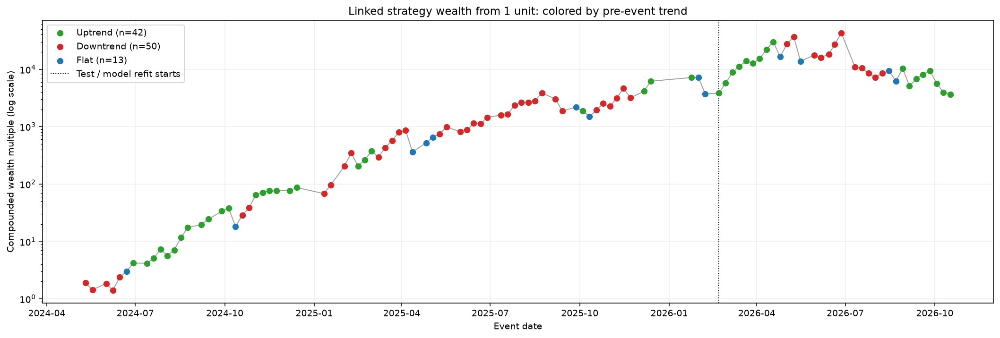

In [1]:
# Same linked wealth path; color each event using its historical trend label.
trend_wealth = mean_adv_regimes[['linked_wealth']].join(regime_trend_data[['trend','source_date']],validate='one_to_one')
assert trend_wealth.notna().all().all()
assert (trend_wealth.source_date < trend_wealth.index).all()
fig, ax = plt.subplots(figsize=(15,5),constrained_layout=True)
ax.plot(trend_wealth.index,trend_wealth.linked_wealth,color='gray',linewidth=1,alpha=.75)
trend_wealth_colors = {'Uptrend':'tab:green','Downtrend':'tab:red','Flat':'tab:blue'}
for label,color in trend_wealth_colors.items():
    part=trend_wealth.loc[trend_wealth.trend.eq(label)]
    ax.scatter(part.index,part.linked_wealth,color=color,s=35,zorder=3,label=f'{label} (n={len(part)})')
ax.axvline(test_start,color='black',linestyle=':',linewidth=1,label='Test / model refit starts')
ax.set_yscale('log')
ax.set(title='Linked strategy wealth from 1 unit: colored by pre-event trend',
       xlabel='Event date',ylabel='Compounded wealth multiple (log scale)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.legend();ax.grid(alpha=.2)
plt.show()


### Linked strategy wealth: +/-0.03, flat events skipped

Wealth is recomputed from the 86 uptrend/downtrend event returns only. All 19 flat events are skipped, including their returns. Green: slope > +0.03; red: slope < -0.03. This matches the unscaled non-flat comparison directly below.


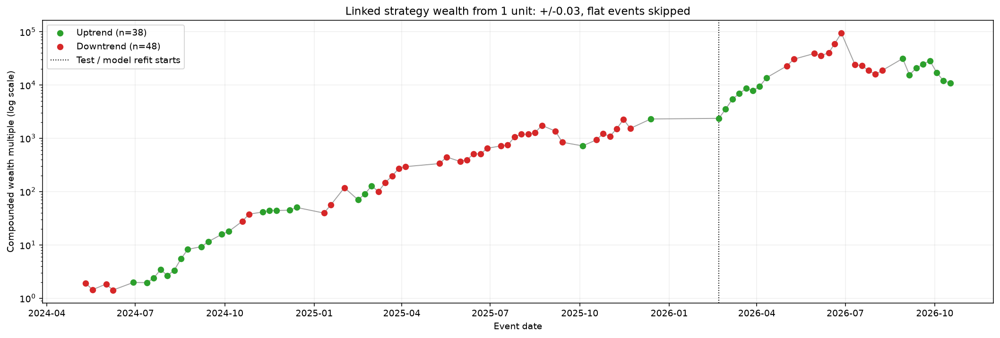

In [1]:
# Linked wealth recomputed with flat events excluded, using the +/-0.03 band.
WEALTH_FLAT_BAND_03 = .03
trend_wealth_03 = mean_adv_regimes[['return_pct']].join(
    regime_trend_data[['slope_sd_per_event','source_date']],validate='one_to_one')
assert trend_wealth_03.notna().all().all()
assert (trend_wealth_03.source_date < trend_wealth_03.index).all()
trend_wealth_03['trend'] = np.select([
    trend_wealth_03.slope_sd_per_event > WEALTH_FLAT_BAND_03,
    trend_wealth_03.slope_sd_per_event < -WEALTH_FLAT_BAND_03],
    ['Uptrend','Downtrend'],default='Flat')
# Recompute wealth excluding flat returns, rather than merely hiding markers.
trend_wealth_03 = trend_wealth_03.loc[trend_wealth_03.trend.ne('Flat')].copy()
trend_wealth_03['linked_wealth'] = (1 + trend_wealth_03.return_pct / 100).cumprod()
assert len(trend_wealth_03) == 86
fig, ax = plt.subplots(figsize=(15,5),constrained_layout=True)
ax.plot(trend_wealth_03.index,trend_wealth_03.linked_wealth,color='gray',linewidth=1,alpha=.75)
for label,color in {'Uptrend':'tab:green','Downtrend':'tab:red'}.items():
    part=trend_wealth_03.loc[trend_wealth_03.trend.eq(label)]
    ax.scatter(part.index,part.linked_wealth,color=color,s=35,zorder=3,label=f'{label} (n={len(part)})')
ax.axvline(test_start,color='black',linestyle=':',linewidth=1,label='Test / model refit starts')
ax.set_yscale('log')
ax.set(title='Linked strategy wealth from 1 unit: +/-0.03, flat events skipped',
       xlabel='Event date',ylabel='Compounded wealth multiple (log scale)')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.legend();ax.grid(alpha=.2)
plt.show()


### Compare 10-event volatility targets: above-mean non-flat versus uptrend

Both targets exclude flat events under the +/-0.03 band. Target A uses the last 10 completed above-mean **non-flat** events. Target B uses the last 10 completed **uptrend** events regardless of above/below-mean status. Group membership is assigned before each historical event using the existing prior-event features.

Hold the comparison risk estimate fixed: last 10 completed events in the current event's above/at-below-mean group, **including historical flat events**. Only the target eligibility changes between variants. Multiplier is `min(1, target_std / own_group_std)` using sample standard deviations of original percentage returns. Because the target now excludes flats while the denominator includes them, even above-mean stakes can be reduced. Insufficient 10-event histories or a zero denominator leave stakes unchanged.

All history dates must precede the current event; assertions verify this, target exclusions, and identical denominator values between variants. Flat events contribute only to the denominator history and are excluded from both targets, return metrics, and wealth compounding. All variants score the same 86 non-flat events. Original returns are used for risk histories regardless of scaling. Histories span validation and test across their model refit; the wealth overlay assumes identical bets and odds and proportionally scalable stakes.


     scope                   strategy  events  geometric_growth_per_event_pct  average_return_pct  volatility_pp  median_return_pct  worst_event_pct  max_drawdown_pct  final_wealth_multiple
  Combined   Original (flat excluded)      86                         11.4203             16.5176        32.0751            18.2118         -74.3149           88.2997             10938.1664
  Combined Above-mean non-flat target      86                         11.1454             14.1983        26.2186            12.5207         -38.1180           58.7749              8844.3514
  Combined             Uptrend target      86                         10.3659             13.3945        25.4865            12.9959         -52.5213           69.5055              4828.2857
Validation   Original (flat excluded)      58                         14.2769             18.2121        30.3155            18.0856         -40.6956           58.7749              2299.3008
Validation Above-mean non-flat target      58     

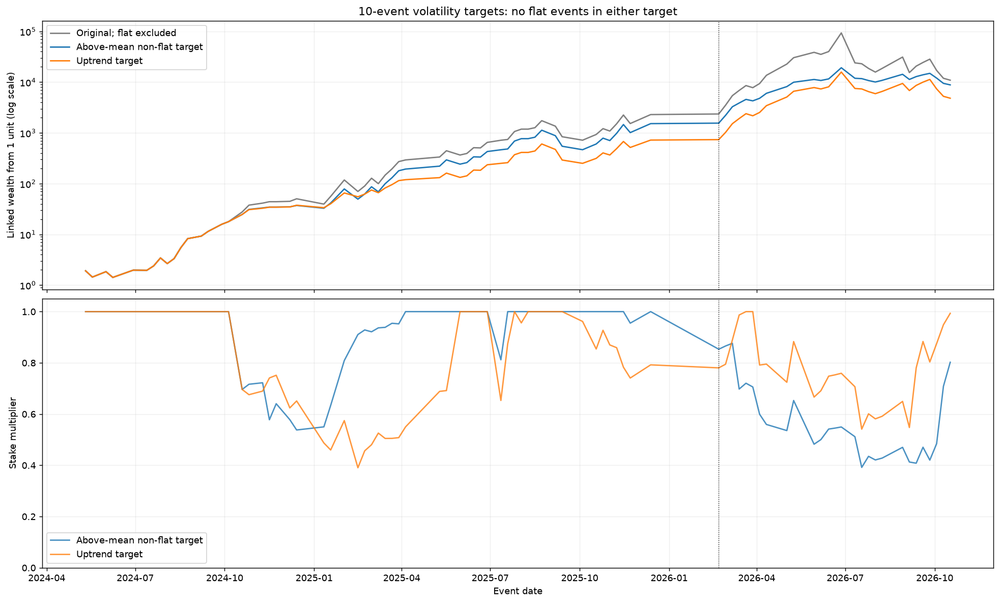

In [1]:
# Isolate target selection: denominator is unchanged across both variants.
VOL_EVENTS_PER_GROUP = 10
VOL_FLAT_BAND = .03
vol_risk_history = mean_adv_regimes[['return_pct','split','regime']].join(
    regime_trend_data[['slope_sd_per_event','source_date']]).copy()
assert (vol_risk_history.source_date < vol_risk_history.index).all()
vol_risk_history['trend']=np.select([vol_risk_history.slope_sd_per_event>VOL_FLAT_BAND,
    vol_risk_history.slope_sd_per_event < -VOL_FLAT_BAND],['Uptrend','Downtrend'],default='Flat')
vol_target_masks={
    'Above-mean non-flat target':vol_risk_history.regime.eq('Above mean') & vol_risk_history.trend.ne('Flat'),
    'Uptrend target':vol_risk_history.trend.eq('Uptrend')}
vol_comparisons={}
for label,target_mask in vol_target_masks.items():
    records=[]
    for date,row in vol_risk_history.iterrows():
        if row.trend=='Flat':continue
        prior=vol_risk_history.loc[vol_risk_history.index<date]
        target_events=prior.loc[target_mask.reindex(prior.index)].tail(VOL_EVENTS_PER_GROUP)
        # Include prior flat events in the current mean-group denominator, as requested earlier.
        own_events=prior.loc[prior.regime.eq(row.regime)].tail(VOL_EVENTS_PER_GROUP)
        assert target_events.trend.ne('Flat').all()
        assert (target_events.index<date).all() and (own_events.index<date).all()
        target=target_events.return_pct.std(ddof=1) if len(target_events)==VOL_EVENTS_PER_GROUP else np.nan
        own=own_events.return_pct.std(ddof=1) if len(own_events)==VOL_EVENTS_PER_GROUP else np.nan
        multiplier=1.;status='Insufficient prior observations'
        if np.isfinite(target) and np.isfinite(own):
            multiplier=min(1.,target/own) if own>1e-12 else 1.
            status='Ready' if own>1e-12 else 'Zero denominator; unchanged'
        records.append({'date':date,'split':row.split,'regime':row.regime,'trend':row.trend,
            'return_pct':row.return_pct,'target_vol_pp':target,'own_vol_pp':own,
            'target_count':len(target_events),'own_count':len(own_events),
            'multiplier':multiplier,'scaled_return_pct':row.return_pct*multiplier,'status':status})
    result=pd.DataFrame(records).set_index('date')
    assert len(result)==86 and result.multiplier.between(0,1).all()
    vol_comparisons[label]=result
# Both variants use identical events, outcomes, and comparison volatility.
a,b=vol_comparisons.values()
pd.testing.assert_index_equal(a.index,b.index)
np.testing.assert_allclose(a.return_pct,b.return_pct)
np.testing.assert_allclose(a.own_vol_pp,b.own_vol_pp,equal_nan=True)
def vol_metrics(values):
    r=np.asarray(values,dtype=float)/100
    assert (r>-1).all()
    wealth=np.r_[1.,np.cumprod(1+r)]
    drawdown=wealth/np.maximum.accumulate(wealth)-1
    return {'events':len(r),'geometric_growth_per_event_pct':100*np.expm1(np.log1p(r).mean()),
        'average_return_pct':100*r.mean(),'volatility_pp':100*r.std(ddof=1),
        'median_return_pct':100*np.median(r),'worst_event_pct':100*r.min(),
        'max_drawdown_pct':-100*drawdown.min(),'final_wealth_multiple':wealth[-1]}

vol_comparison_rows=[]
base=next(iter(vol_comparisons.values()))
for scope in ['Combined','Validation','Test']:
    baseline=base if scope=='Combined' else base.loc[base.split.eq(scope)]
    vol_comparison_rows.append({'scope':scope,'strategy':'Original (flat excluded)',**vol_metrics(baseline.return_pct)})
    for label,trial in vol_comparisons.items():
        part=trial if scope=='Combined' else trial.loc[trial.split.eq(scope)]
        vol_comparison_rows.append({'scope':scope,'strategy':label,**vol_metrics(part.scaled_return_pct)})
vol_scaling_metrics=pd.DataFrame(vol_comparison_rows)
print(vol_scaling_metrics.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
for label,trial in vol_comparisons.items():
    print('\n'+label)
    print(trial.groupby('regime').agg(events=('multiplier','size'),reduced_events=('multiplier',lambda x:int(x.lt(1-1e-12).sum())),
        mean_multiplier=('multiplier','mean'),minimum_multiplier=('multiplier','min')).to_string(float_format=lambda x:f'{x:.4f}'))
    print(trial.status.value_counts().to_string())
fig,axes=plt.subplots(2,1,figsize=(15,9),sharex=True,constrained_layout=True)
axes[0].plot(base.index,(1+base.return_pct/100).cumprod(),color='gray',label='Original; flat excluded')
for label,trial in vol_comparisons.items():
    axes[0].plot(trial.index,(1+trial.scaled_return_pct/100).cumprod(),label=label)
    axes[1].plot(trial.index,trial.multiplier,label=label,alpha=.8)
axes[0].set_yscale('log');axes[0].set(title='10-event volatility targets: no flat events in either target',ylabel='Linked wealth from 1 unit (log scale)')
axes[1].set(xlabel='Event date',ylabel='Stake multiplier',ylim=(0,1.05))
for ax in axes:ax.legend();ax.grid(alpha=.2);ax.axvline(test_start,color='black',ls=':',lw=.8)
plt.show()


### Compare 15-event volatility targets: above-mean non-flat versus uptrend

Both targets exclude flat events under the +/-0.03 band. Target A uses the last 15 completed above-mean **non-flat** events. Target B uses the last 15 completed **uptrend** events regardless of above/below-mean status. Group membership is assigned before each historical event using the existing prior-event features.

Hold the comparison risk estimate fixed: last 15 completed events in the current event's above/at-below-mean group, **including historical flat events**. Only the target eligibility changes between variants. Multiplier is `min(1, target_std / own_group_std)` using sample standard deviations of original percentage returns. Because the target now excludes flats while the denominator includes them, even above-mean stakes can be reduced. Insufficient 15-event histories or a zero denominator leave stakes unchanged.

All history dates must precede the current event; assertions verify this, target exclusions, and identical denominator values between variants. Flat events contribute only to the denominator history and are excluded from both targets, return metrics, and wealth compounding. All variants score the same 86 non-flat events. Original returns are used for risk histories regardless of scaling. Histories span validation and test across their model refit; the wealth overlay assumes identical bets and odds and proportionally scalable stakes.


     scope                   strategy  events  geometric_growth_per_event_pct  average_return_pct  volatility_pp  median_return_pct  worst_event_pct  max_drawdown_pct  final_wealth_multiple
  Combined   Original (flat excluded)      86                         11.4203             16.5176        32.0751            18.2118         -74.3149           88.2997             10938.1664
  Combined Above-mean non-flat target      86                         11.7470             15.0999        27.2999            12.4880         -46.3563           62.5951             14069.5921
  Combined             Uptrend target      86                         10.6467             14.3103        27.8066            13.9134         -60.4783           78.7245              6007.7805
Validation   Original (flat excluded)      58                         14.2769             18.2121        30.3155            18.0856         -40.6956           58.7749              2299.3008
Validation Above-mean non-flat target      58     

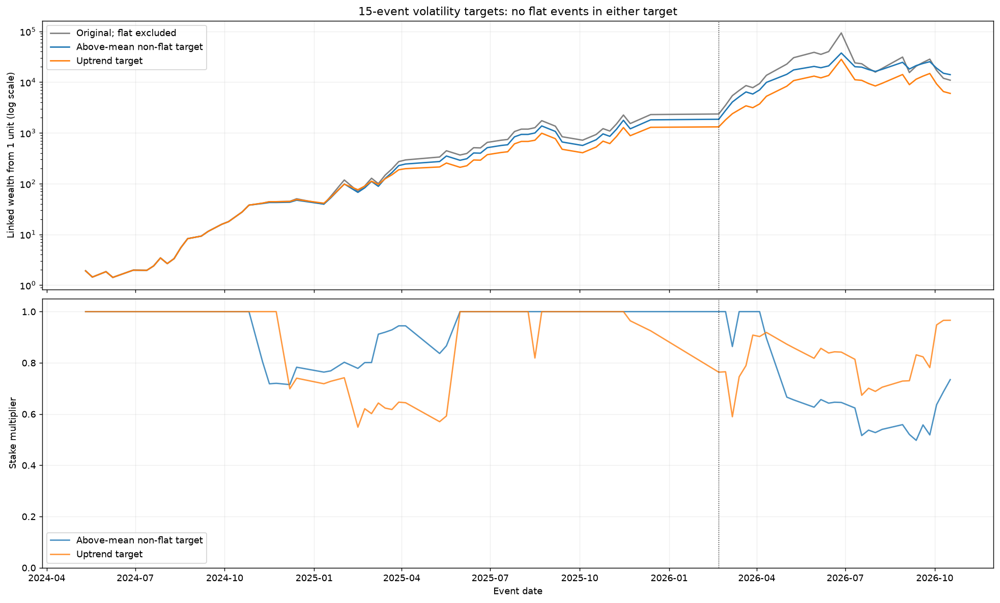

In [1]:
# Isolate target selection: denominator is unchanged across both variants.
VOL_EVENTS_PER_GROUP = 15
VOL_FLAT_BAND = .03
vol_risk_history = mean_adv_regimes[['return_pct','split','regime']].join(
    regime_trend_data[['slope_sd_per_event','source_date']]).copy()
assert (vol_risk_history.source_date < vol_risk_history.index).all()
vol_risk_history['trend']=np.select([vol_risk_history.slope_sd_per_event>VOL_FLAT_BAND,
    vol_risk_history.slope_sd_per_event < -VOL_FLAT_BAND],['Uptrend','Downtrend'],default='Flat')
vol_target_masks={
    'Above-mean non-flat target':vol_risk_history.regime.eq('Above mean') & vol_risk_history.trend.ne('Flat'),
    'Uptrend target':vol_risk_history.trend.eq('Uptrend')}
vol_comparisons={}
for label,target_mask in vol_target_masks.items():
    records=[]
    for date,row in vol_risk_history.iterrows():
        if row.trend=='Flat':continue
        prior=vol_risk_history.loc[vol_risk_history.index<date]
        target_events=prior.loc[target_mask.reindex(prior.index)].tail(VOL_EVENTS_PER_GROUP)
        # Include prior flat events in the current mean-group denominator, as requested earlier.
        own_events=prior.loc[prior.regime.eq(row.regime)].tail(VOL_EVENTS_PER_GROUP)
        assert target_events.trend.ne('Flat').all()
        assert (target_events.index<date).all() and (own_events.index<date).all()
        target=target_events.return_pct.std(ddof=1) if len(target_events)==VOL_EVENTS_PER_GROUP else np.nan
        own=own_events.return_pct.std(ddof=1) if len(own_events)==VOL_EVENTS_PER_GROUP else np.nan
        multiplier=1.;status='Insufficient prior observations'
        if np.isfinite(target) and np.isfinite(own):
            multiplier=min(1.,target/own) if own>1e-12 else 1.
            status='Ready' if own>1e-12 else 'Zero denominator; unchanged'
        records.append({'date':date,'split':row.split,'regime':row.regime,'trend':row.trend,
            'return_pct':row.return_pct,'target_vol_pp':target,'own_vol_pp':own,
            'target_count':len(target_events),'own_count':len(own_events),
            'multiplier':multiplier,'scaled_return_pct':row.return_pct*multiplier,'status':status})
    result=pd.DataFrame(records).set_index('date')
    assert len(result)==86 and result.multiplier.between(0,1).all()
    vol_comparisons[label]=result
# Both variants use identical events, outcomes, and comparison volatility.
a,b=vol_comparisons.values()
pd.testing.assert_index_equal(a.index,b.index)
np.testing.assert_allclose(a.return_pct,b.return_pct)
np.testing.assert_allclose(a.own_vol_pp,b.own_vol_pp,equal_nan=True)
def vol_metrics(values):
    r=np.asarray(values,dtype=float)/100
    assert (r>-1).all()
    wealth=np.r_[1.,np.cumprod(1+r)]
    drawdown=wealth/np.maximum.accumulate(wealth)-1
    return {'events':len(r),'geometric_growth_per_event_pct':100*np.expm1(np.log1p(r).mean()),
        'average_return_pct':100*r.mean(),'volatility_pp':100*r.std(ddof=1),
        'median_return_pct':100*np.median(r),'worst_event_pct':100*r.min(),
        'max_drawdown_pct':-100*drawdown.min(),'final_wealth_multiple':wealth[-1]}

vol_comparison_rows=[]
base=next(iter(vol_comparisons.values()))
for scope in ['Combined','Validation','Test']:
    baseline=base if scope=='Combined' else base.loc[base.split.eq(scope)]
    vol_comparison_rows.append({'scope':scope,'strategy':'Original (flat excluded)',**vol_metrics(baseline.return_pct)})
    for label,trial in vol_comparisons.items():
        part=trial if scope=='Combined' else trial.loc[trial.split.eq(scope)]
        vol_comparison_rows.append({'scope':scope,'strategy':label,**vol_metrics(part.scaled_return_pct)})
vol_scaling_metrics=pd.DataFrame(vol_comparison_rows)
print(vol_scaling_metrics.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
for label,trial in vol_comparisons.items():
    print('\n'+label)
    print(trial.groupby('regime').agg(events=('multiplier','size'),reduced_events=('multiplier',lambda x:int(x.lt(1-1e-12).sum())),
        mean_multiplier=('multiplier','mean'),minimum_multiplier=('multiplier','min')).to_string(float_format=lambda x:f'{x:.4f}'))
    print(trial.status.value_counts().to_string())
fig,axes=plt.subplots(2,1,figsize=(15,9),sharex=True,constrained_layout=True)
axes[0].plot(base.index,(1+base.return_pct/100).cumprod(),color='gray',label='Original; flat excluded')
for label,trial in vol_comparisons.items():
    axes[0].plot(trial.index,(1+trial.scaled_return_pct/100).cumprod(),label=label)
    axes[1].plot(trial.index,trial.multiplier,label=label,alpha=.8)
axes[0].set_yscale('log');axes[0].set(title='15-event volatility targets: no flat events in either target',ylabel='Linked wealth from 1 unit (log scale)')
axes[1].set(xlabel='Event date',ylabel='Stake multiplier',ylim=(0,1.05))
for ax in axes:ax.legend();ax.grid(alpha=.2);ax.axvline(test_start,color='black',ls=':',lw=.8)
plt.show()


### EWMA volatility: 10-event span, above-mean versus uptrend targets

Compare the same two targets using `ewm(span=10, adjust=False, min_periods=10).std(bias=False)`. Alpha is 2/11. The span counts qualifying **events**, not fights; all earlier qualifying events retain exponentially decreasing weight. Compute both target and current mean-group denominator this way, requiring at least 10 observations in each before scaling.

Target A includes above-mean non-flat events; target B includes uptrend events regardless of mean group. Both exclude flats. Denominator includes all prior events in the current above/at-below-mean group, including flats. Only data strictly before the current event are used. Keep multiplier capped at 1, +/-0.03 flat exclusion from performance, original returns for histories, and identical 86-event comparison. Full histories carry across the model refit. The ordinary 10- and 15-event comparisons are retained separately.


     scope                   strategy  events  geometric_growth_per_event_pct  average_return_pct  volatility_pp  median_return_pct  worst_event_pct  max_drawdown_pct  final_wealth_multiple
  Combined   Original (flat excluded)      86                         11.4203             16.5176        32.0751            18.2118         -74.3149           88.2997             10938.1664
  Combined Above-mean non-flat target      86                         11.1630             14.4997        27.1422            12.4880         -49.6223           62.3203              8965.3671
  Combined             Uptrend target      86                         10.4657             13.6832        26.1274            13.8765         -56.3428           69.5513              5218.6679
Validation   Original (flat excluded)      58                         14.2769             18.2121        30.3155            18.0856         -40.6956           58.7749              2299.3008
Validation Above-mean non-flat target      58     

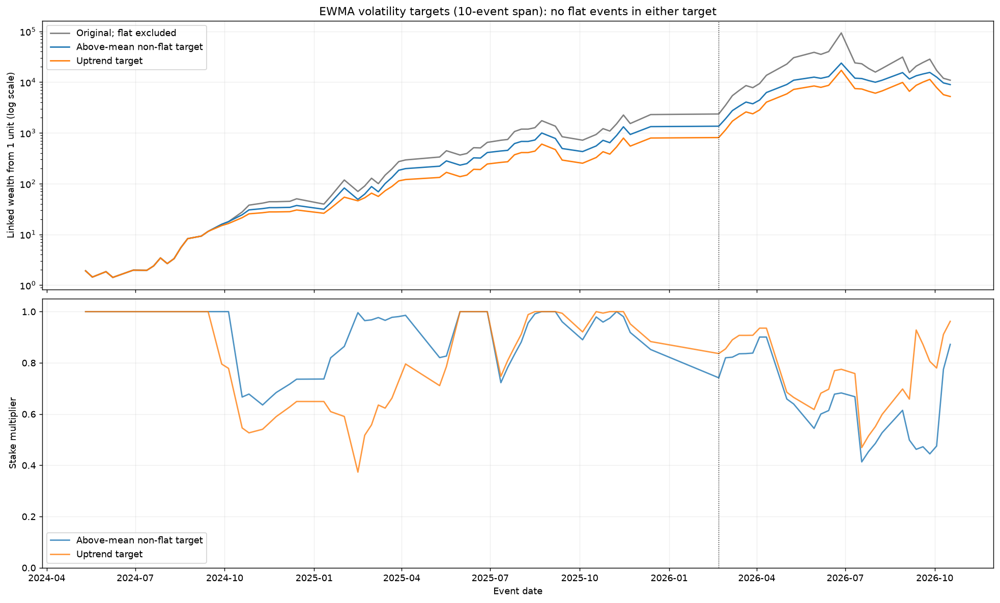

In [1]:
# EWMA standard deviations: span 10 qualifying events, minimum 10 observations, bias correction.
EWMA_VOL_SPAN = 10
EWMA_MIN_EVENTS = 10
VOL_FLAT_BAND = .03
vol_risk_history = mean_adv_regimes[['return_pct','split','regime']].join(
    regime_trend_data[['slope_sd_per_event','source_date']]).copy()
assert (vol_risk_history.source_date < vol_risk_history.index).all()
vol_risk_history['trend']=np.select([vol_risk_history.slope_sd_per_event>VOL_FLAT_BAND,
    vol_risk_history.slope_sd_per_event < -VOL_FLAT_BAND],['Uptrend','Downtrend'],default='Flat')
vol_target_masks={
    'Above-mean non-flat target':vol_risk_history.regime.eq('Above mean') & vol_risk_history.trend.ne('Flat'),
    'Uptrend target':vol_risk_history.trend.eq('Uptrend')}
vol_comparisons={}
for label,target_mask in vol_target_masks.items():
    records=[]
    for date,row in vol_risk_history.iterrows():
        if row.trend=='Flat':continue
        prior=vol_risk_history.loc[vol_risk_history.index<date]
        target_events=prior.loc[target_mask.reindex(prior.index)]
        # Include prior flat events in the current mean-group denominator, as requested earlier.
        own_events=prior.loc[prior.regime.eq(row.regime)]
        assert target_events.trend.ne('Flat').all()
        assert (target_events.index<date).all() and (own_events.index<date).all()
        target=target_events.return_pct.ewm(span=EWMA_VOL_SPAN,adjust=False,min_periods=EWMA_MIN_EVENTS).std(bias=False).iloc[-1] if len(target_events)>=EWMA_MIN_EVENTS else np.nan
        own=own_events.return_pct.ewm(span=EWMA_VOL_SPAN,adjust=False,min_periods=EWMA_MIN_EVENTS).std(bias=False).iloc[-1] if len(own_events)>=EWMA_MIN_EVENTS else np.nan
        multiplier=1.;status='Insufficient prior observations'
        if np.isfinite(target) and np.isfinite(own):
            multiplier=min(1.,target/own) if own>1e-12 else 1.
            status='Ready' if own>1e-12 else 'Zero denominator; unchanged'
        records.append({'date':date,'split':row.split,'regime':row.regime,'trend':row.trend,
            'return_pct':row.return_pct,'target_vol_pp':target,'own_vol_pp':own,
            'target_count':len(target_events),'own_count':len(own_events),
            'multiplier':multiplier,'scaled_return_pct':row.return_pct*multiplier,'status':status})
    result=pd.DataFrame(records).set_index('date')
    assert len(result)==86 and result.multiplier.between(0,1).all()
    vol_comparisons[label]=result
# Both variants use identical events, outcomes, and comparison volatility.
a,b=vol_comparisons.values()
pd.testing.assert_index_equal(a.index,b.index)
np.testing.assert_allclose(a.return_pct,b.return_pct)
np.testing.assert_allclose(a.own_vol_pp,b.own_vol_pp,equal_nan=True)
def vol_metrics(values):
    r=np.asarray(values,dtype=float)/100
    assert (r>-1).all()
    wealth=np.r_[1.,np.cumprod(1+r)]
    drawdown=wealth/np.maximum.accumulate(wealth)-1
    return {'events':len(r),'geometric_growth_per_event_pct':100*np.expm1(np.log1p(r).mean()),
        'average_return_pct':100*r.mean(),'volatility_pp':100*r.std(ddof=1),
        'median_return_pct':100*np.median(r),'worst_event_pct':100*r.min(),
        'max_drawdown_pct':-100*drawdown.min(),'final_wealth_multiple':wealth[-1]}

vol_comparison_rows=[]
base=next(iter(vol_comparisons.values()))
for scope in ['Combined','Validation','Test']:
    baseline=base if scope=='Combined' else base.loc[base.split.eq(scope)]
    vol_comparison_rows.append({'scope':scope,'strategy':'Original (flat excluded)',**vol_metrics(baseline.return_pct)})
    for label,trial in vol_comparisons.items():
        part=trial if scope=='Combined' else trial.loc[trial.split.eq(scope)]
        vol_comparison_rows.append({'scope':scope,'strategy':label,**vol_metrics(part.scaled_return_pct)})
vol_scaling_metrics=pd.DataFrame(vol_comparison_rows)
print(vol_scaling_metrics.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
for label,trial in vol_comparisons.items():
    print('\n'+label)
    print(trial.groupby('regime').agg(events=('multiplier','size'),reduced_events=('multiplier',lambda x:int(x.lt(1-1e-12).sum())),
        mean_multiplier=('multiplier','mean'),minimum_multiplier=('multiplier','min')).to_string(float_format=lambda x:f'{x:.4f}'))
    print(trial.status.value_counts().to_string())
fig,axes=plt.subplots(2,1,figsize=(15,9),sharex=True,constrained_layout=True)
axes[0].plot(base.index,(1+base.return_pct/100).cumprod(),color='gray',label='Original; flat excluded')
for label,trial in vol_comparisons.items():
    axes[0].plot(trial.index,(1+trial.scaled_return_pct/100).cumprod(),label=label)
    axes[1].plot(trial.index,trial.multiplier,label=label,alpha=.8)
axes[0].set_yscale('log');axes[0].set(title='EWMA volatility targets (10-event span): no flat events in either target',ylabel='Linked wealth from 1 unit (log scale)')
axes[1].set(xlabel='Event date',ylabel='Stake multiplier',ylim=(0,1.05))
for ax in axes:ax.legend();ax.grid(alpha=.2);ax.axvline(test_start,color='black',ls=':',lw=.8)
plt.show()


### Previous-event actual Vegas Brier versus returns, by pre-event trend

Use actual no-vig Vegas Brier averaged within the previous single event (not rolling advantage) and current event bankroll percent return. Split by the current event's historical normalized slope under +/-0.03; exclude flat events from every correlation. Report combined validation + test and each split separately. Features are verified to precede the target event.

Approximate pointwise 95% Pearson intervals use 5,000 paired moving-block bootstrap replicates with blocks of five chronological events. Resample each split separately, retaining flat events and trend labels in the resampling timeline, then subset to the requested non-flat trend in each replicate. This preserves local spacing rather than treating nonadjacent up/down events as consecutive. Group counts can vary across replicates; degenerate replicates are excluded. Intervals do not account for prior feature/threshold selection or multiple comparisons. The combined result spans two fitted strategy models.


In [1]:
# Prior single-event actual Vegas Brier versus current returns, split by pre-event trend.
BRIER_TREND_BAND = .03
BRIER_TREND_BOOTSTRAPS = 5000
BRIER_TREND_BLOCK_EVENTS = 5
brier_trend_parts=[]
for split,returns in mean_adv_return_pairs.items():
    history=mean_adv_histories[split].copy()
    red=pd.to_numeric(history.dec_open_red);blue=pd.to_numeric(history.dec_open_blue)
    vegas=(1/red)/(1/red+1/blue)
    history['actual_vegas_brier']=(vegas-history.winner)**2
    event_brier=history.groupby('date').actual_vegas_brier.mean().sort_index()
    prior=pd.DataFrame({'prior_event_brier':event_brier.shift(1),
        'brier_source_date':pd.Series(event_brier.index,index=event_brier.index).shift(1)})
    part=returns[['return_pct']].join(prior).join(regime_trend_data[['slope_sd_per_event']])
    assert part.notna().all().all() and (part.brier_source_date<part.index).all()
    part['trend']=np.select([part.slope_sd_per_event>BRIER_TREND_BAND,
        part.slope_sd_per_event < -BRIER_TREND_BAND],['Uptrend','Downtrend'],default='Flat')
    part['split']=split;brier_trend_parts.append(part)
brier_trend_all=pd.concat(brier_trend_parts).sort_index()
# Resample chronological blocks BEFORE subsetting by trend, preserving gaps between regimes.
# Resample validation and test separately to avoid blocks crossing the model-refit boundary.
rng=np.random.default_rng(42)
brier_trend_draws={}
for split,part in brier_trend_all.groupby('split',sort=False):
    size=len(part);block=min(BRIER_TREND_BLOCK_EVENTS,size)
    starts=rng.integers(0,size-block+1,size=(BRIER_TREND_BOOTSTRAPS,int(np.ceil(size/block))))
    ids=(starts[:,:,None]+np.arange(block)).reshape(BRIER_TREND_BOOTSTRAPS,-1)[:,:size]
    brier_trend_draws[split]=(part,ids)
brier_trend_records=[]
for scope in ['Combined','Validation','Test']:
    sample=brier_trend_all if scope=='Combined' else brier_trend_all.loc[brier_trend_all.split.eq(scope)]
    scopes=['Validation','Test'] if scope=='Combined' else [scope]
    for label in ['Uptrend','Downtrend']:
        selected=sample.loc[sample.trend.eq(label)]
        draws=[]
        for j in range(BRIER_TREND_BOOTSTRAPS):
            boot=pd.concat([brier_trend_draws[k][0].iloc[brier_trend_draws[k][1][j]] for k in scopes])
            boot=boot.loc[boot.trend.eq(label)]
            x=boot.prior_event_brier.to_numpy();y=boot.return_pct.to_numpy()
            if len(x)>=4 and np.std(x)>0 and np.std(y)>0:
                draws.append(np.corrcoef(x,y)[0,1])
        lo,hi=np.quantile(draws,[.025,.975])
        brier_trend_records.append({'scope':scope,'trend':label,'events':len(selected),
            'Pearson_r':pearsonr(selected.prior_event_brier,selected.return_pct).statistic,
            'CI_95_low':lo,'CI_95_high':hi,
            'Spearman_rho':spearmanr(selected.prior_event_brier,selected.return_pct).statistic,
            'valid_bootstraps':len(draws)})
brier_trend_correlations=pd.DataFrame(brier_trend_records)
print(brier_trend_correlations.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
assert brier_trend_all.trend.ne('Flat').sum()==86


     scope     trend  events  Pearson_r  CI_95_low  CI_95_high  Spearman_rho  valid_bootstraps
  Combined   Uptrend      38     0.0727    -0.2114      0.4861        0.1804              5000
  Combined Downtrend      48     0.2586     0.0542      0.5230        0.2288              5000
Validation   Uptrend      22     0.2974     0.0652      0.5372        0.2919              4999
Validation Downtrend      36     0.0815    -0.1552      0.4457        0.0664              5000
      Test   Uptrend      16    -0.1116    -0.5162      0.8109        0.0441              4863
      Test Downtrend      12     0.6082     0.2884      0.8885        0.6573              4908


### Prior-Brier expected-return stake scaling

Feature: actual Vegas Brier averaged within the previous single event. Target: current event original strategy bankroll percent return. Keep +/-0.03 flat exclusion and score the same 86 non-flat events. Fit one pooled relationship across up/down events rather than selecting separate models from the tiny trend subgroups. The first 20 included events initialize the return model and retain original stakes.

Before each subsequent event, standardize Brier using only earlier included observations and fit a univariate ridge regression with an unpenalized intercept and fixed penalty 10. Constrain the coefficient nonnegative to implement the proposed positive-Brier relationship; if earlier data favor a negative coefficient, use zero and leave stakes unchanged. Predict expected event return from its prior Brier. With positive prior mean return, use `multiplier = max(0, predicted_return / prior_mean_return)`. If the prior mean is nonpositive, use zero for nonpositive predictions and one for positive predictions. All estimates update after the event, using original returns even if scaled stakes were zero. Both smoothing/flat settings and feature choice were previously explored, so this chronological computation is not a fresh untouched evaluation.

This standalone exposure rule does not multiply by the volatility rules; their comparisons remain above. It applies the multiplier equally to original stakes with unchanged selections and odds, then compounds adjusted simple returns. Current/future outcomes are excluded from fitting; source dates and a future-target perturbation check verify alignment. Training-model refit at test remains a limitation of pooled histories. Hyperparameters `BRIER_SCALE_MIN_EVENTS` and `BRIER_SCALE_RIDGE` are explicit and were not optimized on these results.


Stake increases are enabled when predicted return exceeds the historical mean. Cap the resulting multiplier at `1 / original_total_stake_fraction`, so **all moneyline and parlay stakes combined cannot exceed 100% of the current adjusted bankroll**. Original total stake is reconstructed from moneyline fractions plus one fraction per parlay ticket (not per leg) and checked against saved `event_total_fstar`. No original bets means no scaled bets. Apply the same multiplier to each original bet, preserving allocation proportions. The cap also applies during initialization. The adjusted bankroll path compounds scaled returns; there are no borrowed funds. Assertions check total exposure and loss bounds.


     scope                 strategy  events  geometric_growth_pct  average_return_pct  volatility_pp  worst_event_pct  max_drawdown_pct  final_wealth_multiple
  Combined Original (flat excluded)      86               11.4203             16.5176        32.0751         -74.3149           88.2997             10938.1664
  Combined       Prior-Brier scaled      86               11.1057             17.0143        34.9563         -78.1646           92.8278              8577.0172
Validation Original (flat excluded)      58               14.2769             18.2121        30.3155         -40.6956           58.7749              2299.3008
Validation       Prior-Brier scaled      58               14.1444             18.2614        31.7185         -37.9025           60.0807              2149.6631
      Test Original (flat excluded)      28                5.7282             13.0076        35.7734         -74.3149           88.2997                 4.7572
      Test       Prior-Brier scaled      28   

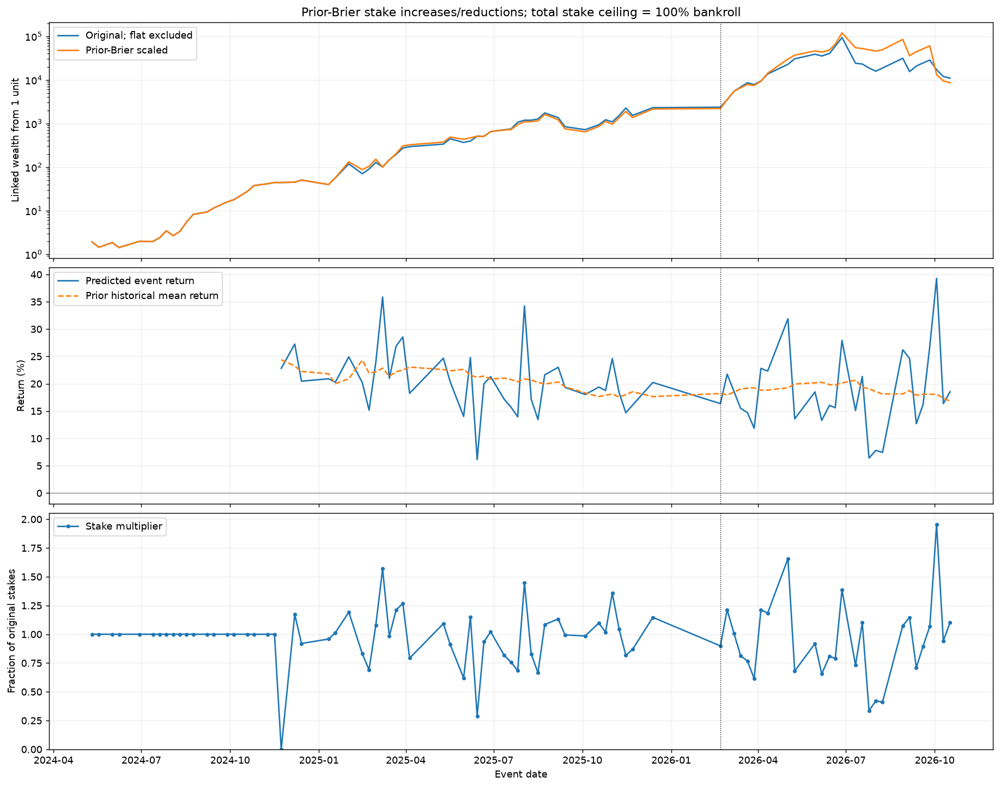

In [1]:
# Return-based stake scaling from prior single-event actual Vegas Brier.
# Hyperparameters are fixed for this exploratory run, not selected on its returns.
BRIER_SCALE_MIN_EVENTS = 20
BRIER_SCALE_RIDGE = 10.0
brier_scale_data = brier_trend_all.loc[brier_trend_all.trend.ne('Flat')].copy()
assert len(brier_scale_data)==86
assert (brier_scale_data.brier_source_date < brier_scale_data.index).all()

def fit_prior_brier_return_rule(past, current_brier):
    x=past.prior_event_brier.to_numpy(float); y=past.return_pct.to_numpy(float)
    baseline=float(y.mean()); xmean=float(x.mean()); xsd=float(x.std(ddof=0))
    slope=0.; predicted=baseline
    if xsd>1e-12:
        z=(x-xmean)/xsd
        # Standardized univariate ridge, intercept unpenalized, nonnegative slope.
        slope=max(0.,float(np.dot(z,y-baseline)/(np.dot(z,z)+BRIER_SCALE_RIDGE)))
        predicted=baseline+slope*(current_brier-xmean)/xsd
    # Relative expected return permits increases; the event-level stake cap is applied below.
    if baseline>1e-12:
        multiplier=float(max(0.,predicted/baseline))
    else:
        multiplier=0. if predicted<=0 else 1.
    return baseline,predicted,slope,multiplier

# Reconstruct total event stake; parlay rows are legs, so count each ticket once.
brier_exposure_parts=[]
for split,prefix in [('Validation','train_val'),('Test','trainval_test')]:
    ml=pd.read_csv(mean_adv_backtests/f'{prefix}_open_with_open_inference_no_decay_moneylines.csv',parse_dates=['date'])
    pl=pd.read_csv(mean_adv_backtests/f'{prefix}_open_with_open_inference_no_decay_parlays.csv',parse_dates=['date'])
    singles=ml.groupby('date').choice_fstar.sum()
    tickets=pl.groupby(['date','parlay_strategy'])
    assert tickets.fstar_parlay.nunique(dropna=False).le(1).all()
    parlays=tickets.fstar_parlay.first().groupby('date').sum()
    total=singles.add(parlays,fill_value=0).reindex(singles.index)
    np.testing.assert_allclose(total,ml.groupby('date').event_total_fstar.first(),atol=1e-12)
    brier_exposure_parts.append(total)
brier_scale_data['original_stake_fraction']=pd.concat(brier_exposure_parts).reindex(brier_scale_data.index)
assert brier_scale_data.original_stake_fraction.notna().all()
assert brier_scale_data.original_stake_fraction.between(0,1+1e-12).all()

brier_scale_rows=[]
for j,(date,row) in enumerate(brier_scale_data.iterrows()):
    past=brier_scale_data.iloc[:j]
    multiplier=1.;baseline=predicted=slope=np.nan;status='Warmup unchanged'
    if len(past)>=BRIER_SCALE_MIN_EVENTS:
        assert past.index.max()<date
        baseline,predicted,slope,multiplier=fit_prior_brier_return_rule(past,row.prior_event_brier)
        status='Fitted on earlier events'
    desired_multiplier=multiplier
    cap=1./row.original_stake_fraction if row.original_stake_fraction>0 else 0.
    multiplier=min(desired_multiplier,cap)
    brier_scale_rows.append({'desired_multiplier':desired_multiplier,'bankroll_cap_multiplier':cap,'date':date,'training_events':len(past),'baseline_return_pct':baseline,
        'predicted_return_pct':predicted,'slope_pp_per_sd':slope,'multiplier':multiplier,'status':status})
brier_scale_trial=brier_scale_data.join(pd.DataFrame(brier_scale_rows).set_index('date'))
brier_scale_trial['scaled_return_pct']=brier_scale_trial.return_pct*brier_scale_trial.multiplier
brier_scale_trial['adjusted_stake_fraction']=brier_scale_trial.original_stake_fraction*brier_scale_trial.multiplier
assert brier_scale_trial.multiplier.ge(0).all()
assert brier_scale_trial.adjusted_stake_fraction.le(1+1e-12).all()
assert brier_scale_trial.scaled_return_pct.ge(-100-1e-8).all()

# Verify future/current target mutations cannot change pre-event decisions.
probe=brier_scale_data.copy();probe.loc[probe.index[40]:,'return_pct']+=1000
np.testing.assert_allclose(fit_prior_brier_return_rule(probe.iloc[:40],probe.prior_event_brier.iloc[40]),
    fit_prior_brier_return_rule(brier_scale_data.iloc[:40],brier_scale_data.prior_event_brier.iloc[40]))

def brier_scale_metrics(returns):
    r=np.asarray(returns,float)/100
    assert (r>-1).all()
    wealth=np.r_[1.,np.cumprod(1+r)]
    return {'events':len(r),'geometric_growth_pct':100*np.expm1(np.log1p(r).mean()),
        'average_return_pct':100*r.mean(),'volatility_pp':100*r.std(ddof=1),
        'worst_event_pct':100*r.min(),'max_drawdown_pct':-100*(wealth/np.maximum.accumulate(wealth)-1).min(),
        'final_wealth_multiple':wealth[-1]}
brier_scale_records=[]
for scope,part in [('Combined',brier_scale_trial),*list(brier_scale_trial.groupby('split',sort=False))]:
    for name,column in [('Original (flat excluded)','return_pct'),('Prior-Brier scaled','scaled_return_pct')]:
        brier_scale_records.append({'scope':scope,'strategy':name,**brier_scale_metrics(part[column])})
brier_scale_summary=pd.DataFrame(brier_scale_records)
print(brier_scale_summary.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
print('\nScaling counts:')
print(brier_scale_trial.groupby('split').agg(events=('multiplier','size'),
    increased_events=('multiplier',lambda x:int(x.gt(1+1e-12).sum())),
    reduced_events=('multiplier',lambda x:int(x.lt(1-1e-12).sum())),ceiling_events=('adjusted_stake_fraction',lambda x:int(x.ge(1-1e-12).sum())),skipped_events=('multiplier',lambda x:int(x.eq(0).sum())),
    average_multiplier=('multiplier','mean'),minimum_multiplier=('multiplier','min')).to_string(float_format=lambda x:f'{x:.4f}'))
print('Warmup:',int(brier_scale_trial.status.eq('Warmup unchanged').sum()),'events; actual return targets never enter their own fitted prediction.')
fig,axes=plt.subplots(3,1,figsize=(14,11),sharex=True,constrained_layout=True)
for col,label in [('return_pct','Original; flat excluded'),('scaled_return_pct','Prior-Brier scaled')]:
    axes[0].plot(brier_scale_trial.index,(1+brier_scale_trial[col]/100).cumprod(),label=label)
axes[0].set_yscale('log');axes[0].set(title='Prior-Brier stake increases/reductions; total stake ceiling = 100% bankroll',ylabel='Linked wealth from 1 unit');axes[0].legend()
axes[1].plot(brier_scale_trial.index,brier_scale_trial.predicted_return_pct,label='Predicted event return')
axes[1].plot(brier_scale_trial.index,brier_scale_trial.baseline_return_pct,'--',label='Prior historical mean return')
axes[1].axhline(0,color='gray',lw=.7);axes[1].set(ylabel='Return (%)');axes[1].legend()
axes[2].plot(brier_scale_trial.index,brier_scale_trial.multiplier,marker='.',label='Stake multiplier')
axes[2].set(xlabel='Event date',ylabel='Fraction of original stakes',ylim=(0,max(1.05,brier_scale_trial.multiplier.max()*1.05)));axes[2].legend()
for ax in axes:ax.axvline(test_start,color='black',ls=':',lw=.8);ax.grid(alpha=.2)
plt.show()


### Combined prior-Brier reductions and 10-event volatility scaling

Prior-Brier is now **reduction-only**: `brier_factor = min(1, desired_Brier_multiplier)`. Multiply by the ordinary 10-event volatility factor, then enforce the total event bankroll cap: `min(brier_factor * volatility_factor, 1/original_total_stake_fraction)`. Neither factor increases stakes; assertions verify the combined allocation never exceeds the original allocation or 100% of bankroll. Zero original exposure stays zero.

Volatility target: last 10 completed above-mean non-flat events. Denominator: last 10 completed events of the current above/below-mean group, including prior flat events. Use ordinary sample standard deviations, not EWMA. Prior-Brier retains its existing historical-only regression and 20-event warmup. Both mean-group membership and all inputs precede the current event. Flat events remain excluded from returns and compounding.

Compare original, volatility-only, prior-Brier reductions-only, and combined on the same 86 events. The earlier standalone Brier-increase experiment remains separate; this combined strategy allows no increases. Proportional stake overlay assumes unchanged bets and odds. These previously examined strategy periods provide exploratory results.


     scope                               strategy  events  geometric_growth_pct  average_return_pct  volatility_pp  worst_event_pct  max_drawdown_pct  final_wealth_multiple
  Combined                               Original      86               11.4203             16.5176        32.0751         -74.3149           88.2997             10938.1664
  Combined               10-event volatility only      86               11.1454             14.1983        26.2186         -38.1180           58.7749              8844.3514
  Combined            Prior-Brier reductions only      86               11.6790             15.8887        30.3769         -54.3405           77.4165             13352.3324
  Combined Combined Brier reductions + volatility      86               10.8467             13.5916        25.1708         -37.9025           58.5257              7017.2886
Validation                               Original      58               14.2769             18.2121        30.3155         -40.6956    

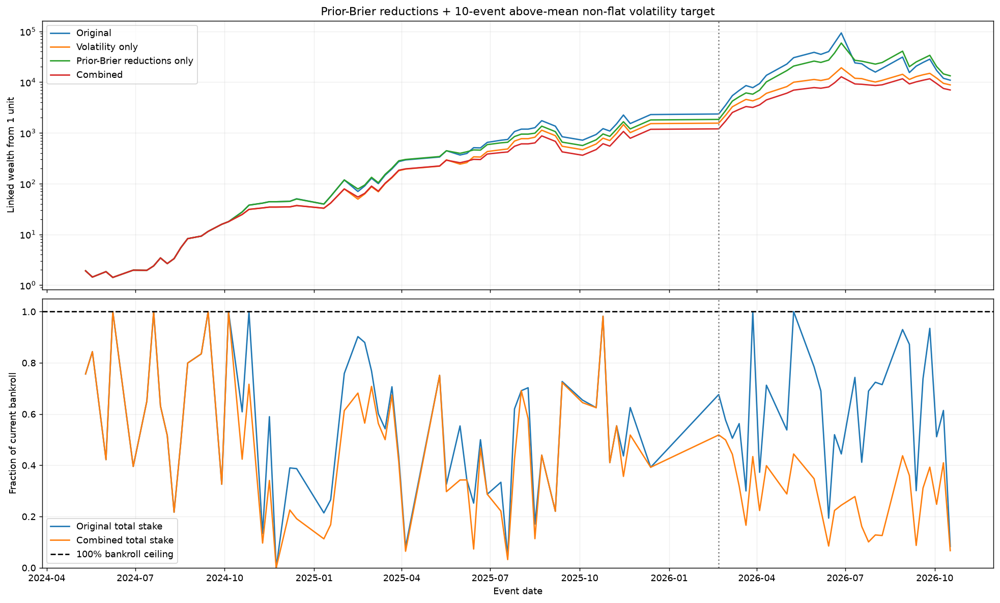

In [1]:
# Combine raw prior-Brier allocation adjustment with ordinary 10-event volatility scaling.
COMBINED_VOL_EVENTS = 10
combined_risk_history = mean_adv_regimes[['return_pct','regime']].join(regime_trend_data[['slope_sd_per_event','source_date']])
combined_risk_history['flat'] = combined_risk_history.slope_sd_per_event.abs().le(.03)
combined_trial = brier_scale_trial.copy()
combined_vol_rows=[]
for date,row in combined_trial.iterrows():
    prior=combined_risk_history.loc[combined_risk_history.index<date]
    target=prior.loc[prior.regime.eq('Above mean') & ~prior.flat].tail(COMBINED_VOL_EVENTS)
    own=prior.loc[prior.regime.eq(mean_adv_regimes.loc[date,'regime'])].tail(COMBINED_VOL_EVENTS)
    assert not target.flat.any()
    assert (prior.source_date < prior.index).all()
    multiplier=1.
    if len(target)==COMBINED_VOL_EVENTS and len(own)==COMBINED_VOL_EVENTS:
        target_sd=target.return_pct.std(ddof=1);own_sd=own.return_pct.std(ddof=1)
        multiplier=min(1.,target_sd/own_sd) if own_sd>1e-12 else 1.
    combined_vol_rows.append(multiplier)
combined_trial['vol_multiplier']=combined_vol_rows
# Prior-Brier is reduction-only before combining with volatility.
combined_trial['brier_downscale_multiplier']=np.minimum(1.,combined_trial.desired_multiplier)
combined_trial['brier_downscale_return_pct']=combined_trial.return_pct*np.minimum(combined_trial.brier_downscale_multiplier,combined_trial.bankroll_cap_multiplier)
combined_trial['combined_multiplier']=np.minimum(
    combined_trial.brier_downscale_multiplier*combined_trial.vol_multiplier,
    combined_trial.bankroll_cap_multiplier)
combined_trial['combined_stake_fraction']=combined_trial.original_stake_fraction*combined_trial.combined_multiplier
assert combined_trial.combined_stake_fraction.between(0,1+1e-12).all()
assert combined_trial.combined_multiplier.between(0,1).all()
assert combined_trial.combined_stake_fraction.le(combined_trial.original_stake_fraction+1e-12).all()
combined_trial['vol_only_return_pct']=combined_trial.return_pct*combined_trial.vol_multiplier
combined_trial['combined_return_pct']=combined_trial.return_pct*combined_trial.combined_multiplier
assert len(combined_trial)==86 and combined_trial.trend.ne('Flat').all()
combined_records=[]
for scope,part in [('Combined',combined_trial),*list(combined_trial.groupby('split',sort=False))]:
    for name,column in [('Original','return_pct'),('10-event volatility only','vol_only_return_pct'),
                        ('Prior-Brier reductions only','brier_downscale_return_pct'),('Combined Brier reductions + volatility','combined_return_pct')]:
        combined_records.append({'scope':scope,'strategy':name,**brier_scale_metrics(part[column])})
combined_scaling_summary=pd.DataFrame(combined_records)
print(combined_scaling_summary.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
print('Combined stake increases:',int(combined_trial.combined_multiplier.gt(1+1e-12).sum()),
      '; reductions:',int(combined_trial.combined_multiplier.lt(1-1e-12).sum()),
      '; events at bankroll ceiling:',int(combined_trial.combined_stake_fraction.ge(1-1e-12).sum()))
fig,axes=plt.subplots(2,1,figsize=(15,9),sharex=True,constrained_layout=True)
for label,column in [('Original','return_pct'),('Volatility only','vol_only_return_pct'),
                     ('Prior-Brier reductions only','brier_downscale_return_pct'),('Combined','combined_return_pct')]:
    axes[0].plot(combined_trial.index,(1+combined_trial[column]/100).cumprod(),label=label)
axes[0].set_yscale('log');axes[0].set(title='Prior-Brier reductions + 10-event above-mean non-flat volatility target',ylabel='Linked wealth from 1 unit');axes[0].legend()
axes[1].plot(combined_trial.index,combined_trial.original_stake_fraction,label='Original total stake')
axes[1].plot(combined_trial.index,combined_trial.combined_stake_fraction,label='Combined total stake')
axes[1].axhline(1,color='black',ls='--',label='100% bankroll ceiling')
axes[1].set(xlabel='Event date',ylabel='Fraction of current bankroll',ylim=(0,1.05));axes[1].legend()
for ax in axes:ax.axvline(test_start,color='gray',ls=':');ax.grid(alpha=.2)
plt.show()


### Alternative: target volatility follows the current pre-event mean group

This separate trial preserves the preceding fixed-above-mean target result for comparison. Classify the current event using the previous event's rolling advantage versus its preceding five-year mean. If above mean, target the last 10 above-mean non-flat events; if at/below mean, target the last 10 at/below-mean non-flat events. The denominator is the last 10 events in the **same** mean group, including flats. Uptrend/downtrend directions remain pooled; this trial changes only the target's above/below selection. If both target and denominator excluded flats, their samples would be identical and the volatility multiplier would always be one.

All source dates precede the current event. Keep +/-0.03 flat exclusion from performance, 10-observation requirements with unchanged stakes during warmup, and reduction-only prior-Brier scaling. Multiply factors and retain the total-bankroll cap. Compare the same 86 events. No changes are made to the separate closing-market notebook or earlier fixed-target results.


     scope                               strategy  events  geometric_growth_pct  average_return_pct  volatility_pp  worst_event_pct  max_drawdown_pct  final_wealth_multiple
  Combined                               Original      86               11.4203             16.5176        32.0751         -74.3149           88.2997             10938.1664
  Combined               10-event volatility only      86               10.8640             15.0213        29.2522         -67.7186           78.6761              7111.9959
  Combined            Prior-Brier reductions only      86               11.6790             15.8887        30.3769         -54.3405           77.4165             13352.3324
  Combined Combined Brier reductions + volatility      86               10.9875             14.4599        27.6519         -49.5171           63.4671              7826.5932
Validation                               Original      58               14.2769             18.2121        30.3155         -40.6956    

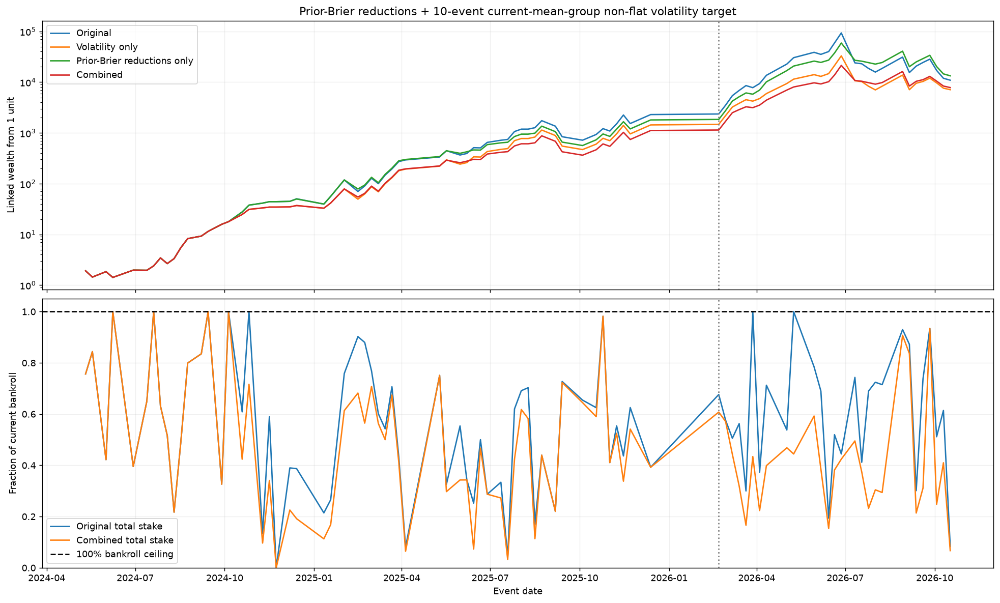

In [1]:
# Combine raw prior-Brier allocation adjustment with ordinary 10-event volatility scaling.
COMBINED_VOL_EVENTS = 10
combined_risk_history = mean_adv_regimes[['return_pct','regime']].join(regime_trend_data[['slope_sd_per_event','source_date']])
combined_risk_history['flat'] = combined_risk_history.slope_sd_per_event.abs().le(.03)
combined_trial = brier_scale_trial.copy()
combined_vol_rows=[]
for date,row in combined_trial.iterrows():
    prior=combined_risk_history.loc[combined_risk_history.index<date]
    current_group=mean_adv_regimes.loc[date,'regime']
    target=prior.loc[prior.regime.eq(current_group) & ~prior.flat].tail(COMBINED_VOL_EVENTS)
    own=prior.loc[prior.regime.eq(mean_adv_regimes.loc[date,'regime'])].tail(COMBINED_VOL_EVENTS)
    assert not target.flat.any()
    assert target.regime.eq(current_group).all() and own.regime.eq(current_group).all()
    assert (prior.source_date < prior.index).all()
    multiplier=1.
    if len(target)==COMBINED_VOL_EVENTS and len(own)==COMBINED_VOL_EVENTS:
        target_sd=target.return_pct.std(ddof=1);own_sd=own.return_pct.std(ddof=1)
        multiplier=min(1.,target_sd/own_sd) if own_sd>1e-12 else 1.
    combined_vol_rows.append(multiplier)
combined_trial['vol_multiplier']=combined_vol_rows
# Prior-Brier is reduction-only before combining with volatility.
combined_trial['brier_downscale_multiplier']=np.minimum(1.,combined_trial.desired_multiplier)
combined_trial['brier_downscale_return_pct']=combined_trial.return_pct*np.minimum(combined_trial.brier_downscale_multiplier,combined_trial.bankroll_cap_multiplier)
combined_trial['combined_multiplier']=np.minimum(
    combined_trial.brier_downscale_multiplier*combined_trial.vol_multiplier,
    combined_trial.bankroll_cap_multiplier)
combined_trial['combined_stake_fraction']=combined_trial.original_stake_fraction*combined_trial.combined_multiplier
assert combined_trial.combined_stake_fraction.between(0,1+1e-12).all()
assert combined_trial.combined_multiplier.between(0,1).all()
assert combined_trial.combined_stake_fraction.le(combined_trial.original_stake_fraction+1e-12).all()
combined_trial['vol_only_return_pct']=combined_trial.return_pct*combined_trial.vol_multiplier
combined_trial['combined_return_pct']=combined_trial.return_pct*combined_trial.combined_multiplier
assert len(combined_trial)==86 and combined_trial.trend.ne('Flat').all()
combined_records=[]
for scope,part in [('Combined',combined_trial),*list(combined_trial.groupby('split',sort=False))]:
    for name,column in [('Original','return_pct'),('10-event volatility only','vol_only_return_pct'),
                        ('Prior-Brier reductions only','brier_downscale_return_pct'),('Combined Brier reductions + volatility','combined_return_pct')]:
        combined_records.append({'scope':scope,'strategy':name,**brier_scale_metrics(part[column])})
combined_scaling_summary=pd.DataFrame(combined_records)
print(combined_scaling_summary.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
print('Combined stake increases:',int(combined_trial.combined_multiplier.gt(1+1e-12).sum()),
      '; reductions:',int(combined_trial.combined_multiplier.lt(1-1e-12).sum()),
      '; events at bankroll ceiling:',int(combined_trial.combined_stake_fraction.ge(1-1e-12).sum()))
fig,axes=plt.subplots(2,1,figsize=(15,9),sharex=True,constrained_layout=True)
for label,column in [('Original','return_pct'),('Volatility only','vol_only_return_pct'),
                     ('Prior-Brier reductions only','brier_downscale_return_pct'),('Combined','combined_return_pct')]:
    axes[0].plot(combined_trial.index,(1+combined_trial[column]/100).cumprod(),label=label)
axes[0].set_yscale('log');axes[0].set(title='Prior-Brier reductions + 10-event current-mean-group non-flat volatility target',ylabel='Linked wealth from 1 unit');axes[0].legend()
axes[1].plot(combined_trial.index,combined_trial.original_stake_fraction,label='Original total stake')
axes[1].plot(combined_trial.index,combined_trial.combined_stake_fraction,label='Combined total stake')
axes[1].axhline(1,color='black',ls='--',label='100% bankroll ceiling')
axes[1].set(xlabel='Event date',ylabel='Fraction of current bankroll',ylim=(0,1.05));axes[1].legend()
for ax in axes:ax.axvline(test_start,color='gray',ls=':');ax.grid(alpha=.2)
plt.show()


## Vegas excess Brier over time

For each fight, let `p` be Vegas's no-vig red-win probability and `y` the outcome
(1 for a red win, 0 for a blue win). Actual Brier is `(p - y)**2`.
If `p` is the true win probability, expected Brier is
`p * (1 - p)**2 + (1 - p) * p**2 = p * (1 - p)`.

We calculate this expectation separately for every fight, then average over the
same 100-fight window. We do **not** apply the formula to the average probability.
Excess Brier = actual Brier minus expected Brier. Above zero means outcomes scored
worse than the market's own probability-based baseline; below zero means better.
This is a descriptive diagnostic, not a standalone calibration test: positive and
negative errors can cancel, and at p=0.5 excess Brier is always zero.


Full-period actual: 0.2210; expected: 0.2263; excess: -0.0053


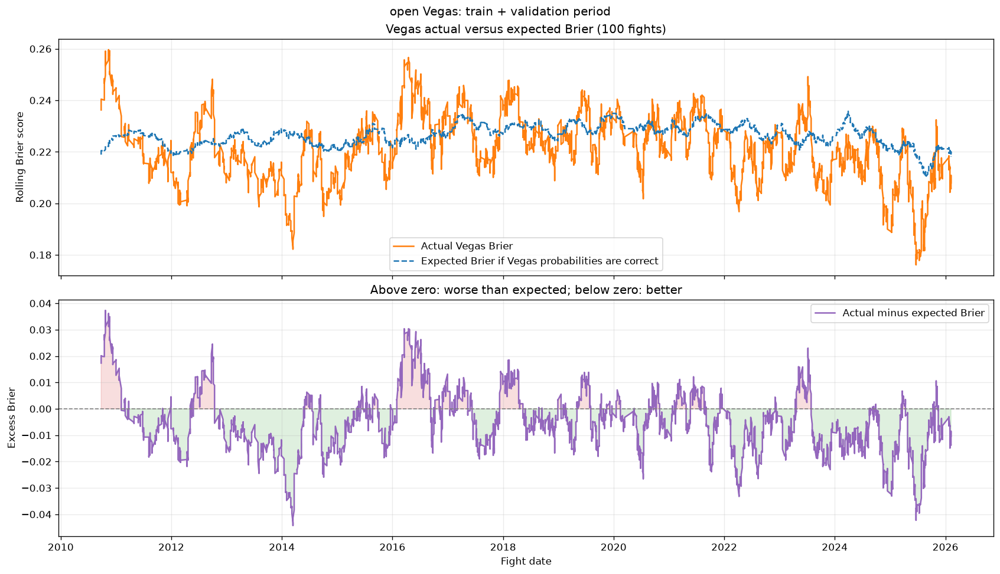

In [4]:
scores["vegas_probability"] = vegas.loc[scores.index]
scores["vegas_expected_brier"] = scores.vegas_probability * (1 - scores.vegas_probability)
scores["vegas_excess_brier"] = scores.vegas_brier - scores.vegas_expected_brier
scores["rolling_vegas_expected"] = scores.vegas_expected_brier.rolling(WINDOW, min_periods=WINDOW).mean()
scores["rolling_vegas_excess"] = scores.vegas_excess_brier.rolling(WINDOW, min_periods=WINDOW).mean()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, constrained_layout=True)
axes[0].plot(scores.date, scores.rolling_vegas, color="tab:orange", label="Actual Vegas Brier")
axes[0].plot(scores.date, scores.rolling_vegas_expected, color="tab:blue", linestyle="--",
             label="Expected Brier if Vegas probabilities are correct")
axes[0].set(ylabel="Rolling Brier score", title=f"Vegas actual versus expected Brier ({WINDOW} fights)")
axes[1].plot(scores.date, scores.rolling_vegas_excess, color="tab:purple", label="Actual minus expected Brier")
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1].fill_between(scores.date, 0, scores.rolling_vegas_excess,
                     where=scores.rolling_vegas_excess.ge(0), color="tab:red", alpha=.15)
axes[1].fill_between(scores.date, 0, scores.rolling_vegas_excess,
                     where=scores.rolling_vegas_excess.lt(0), color="tab:green", alpha=.15)
axes[1].set(xlabel="Fight date", ylabel="Excess Brier", title="Above zero: worse than expected; below zero: better")
locator = mdates.AutoDateLocator()
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
for ax in axes:
    ax.grid(alpha=.25)
    ax.legend()
fig.suptitle(f"{ODDS_TYPE} Vegas: train + validation period")
print(f"Full-period actual: {scores.vegas_brier.mean():.4f}; "
      f"expected: {scores.vegas_expected_brier.mean():.4f}; "
      f"excess: {scores.vegas_excess_brier.mean():+.4f}")
plt.show()


## Autocorrelation, unit roots, and shuffled-event cycle test

The ACF and ADF use **unsmoothed event-average actual Vegas Brier**, with one
observation per event date. A lag means events apart, not calendar months.
The ACF of the 100-fight rolling curve is also shown, but its overlap creates
mechanical dependence and it must not be interpreted as independent evidence.

ADF null: the event-level series has a unit root. Rejection is evidence against
that null under the chosen specification; non-rejection does not prove a random
walk, and neither outcome proves or disproves cycles. Both constant-only and
constant-plus-linear-trend specifications are reported; lag length uses AIC.
Brier is bounded, making an unrestricted random walk an imperfect literal model.

Permutation null: whole event blocks are exchangeable in chronological order.
We shuffle events **without replacement**, keeping every fight, its outcome,
probability, and within-event order intact. Each shuffled sample gets the same
100-fight rolling calculation as the observed data.

The primary statistic is the largest periodogram power of the linearly detrended
rolling curve across periods from 2 × WINDOW fights to one-third of the available
rolling observations (at least three repetitions). The maximum is recomputed for
each shuffle, accounting for the search across frequencies in this range.
A secondary statistic is rolling peak-to-trough range. Monte Carlo p-values use
(1 + number of null statistics at least as large as observed) / (permutations + 1).

These are exploratory tests because the waves have already been inspected.
Rejection indicates temporal structure beyond random event ordering, which can
also arise from changing fight mix, trends, or regimes; it does not establish a
stable forecastable cycle. Periods here are measured in fights, not calendar time.


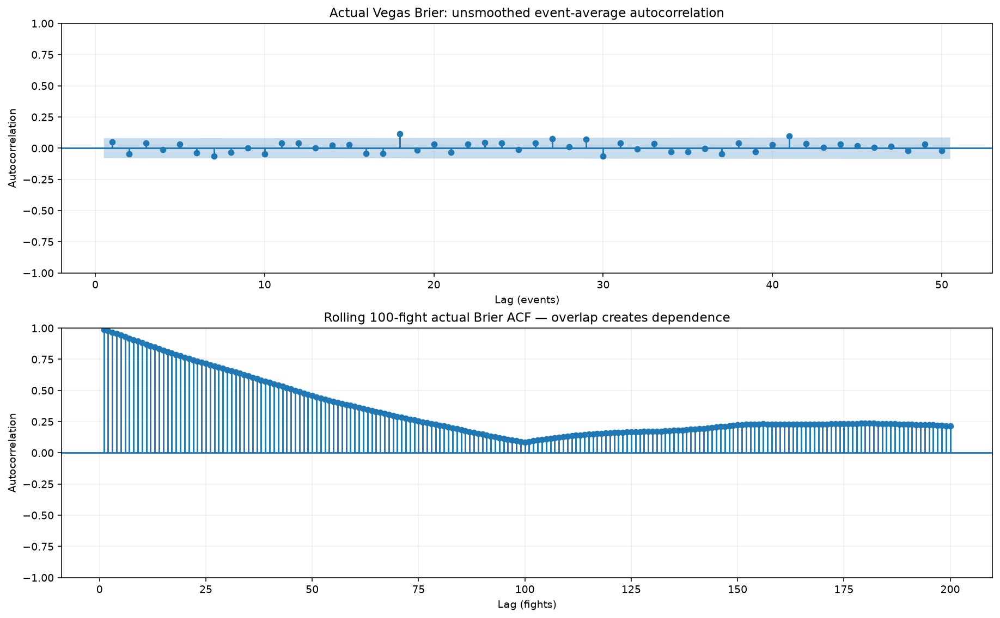

   specification  ADF statistic  p-value  lags  observations  5% critical unit-root null at 5%
        Constant     -23.498266      0.0     0           608    -2.866305               Reject
Constant + trend     -23.508756      0.0     0           608    -3.417736               Reject
ADF rejection is not a test of whether there are cycles or whether returns are forecastable.


In [5]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller
from scipy.signal import periodogram

# Unsmoothed actual scores; do not substitute expected or excess Brier.
event_brier = scores.groupby("date", sort=True).vegas_brier.mean()
rolling_actual = scores.rolling_vegas.dropna().to_numpy()
ACF_LAGS = min(50, len(event_brier) // 4)
fig, axes = plt.subplots(2, 1, figsize=(13, 8), constrained_layout=True)
plot_acf(event_brier.to_numpy(), lags=ACF_LAGS, zero=False, ax=axes[0], alpha=.05)
axes[0].set(title="Actual Vegas Brier: unsmoothed event-average autocorrelation",
            xlabel="Lag (events)", ylabel="Autocorrelation")
plot_acf(rolling_actual, lags=min(200, len(rolling_actual)//4), zero=False,
         ax=axes[1], alpha=None)
axes[1].set(title=f"Rolling {WINDOW}-fight actual Brier ACF — overlap creates dependence",
            xlabel="Lag (fights)", ylabel="Autocorrelation")
for ax in axes:
    ax.grid(alpha=.2)
plt.show()

adf_records = []
for specification, label in [("c", "Constant"), ("ct", "Constant + trend")]:
    statistic, pvalue, used_lags, nobs, critical, _ = adfuller(
        event_brier.to_numpy(), regression=specification, autolag="AIC")
    adf_records.append({"specification": label, "ADF statistic": statistic,
                        "p-value": pvalue, "lags": used_lags, "observations": nobs,
                        "5% critical": critical["5%"],
                        "unit-root null at 5%": "Reject" if pvalue < .05 else "Do not reject"})
adf_results = pd.DataFrame(adf_records)
print(adf_results.to_string(index=False))
print("ADF rejection is not a test of whether there are cycles or whether returns are forecastable.")


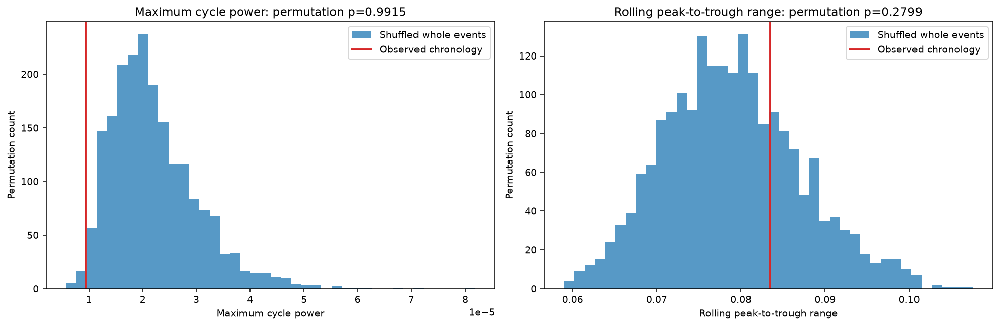

                                 statistic  observed  null 95th percentile  permutation p-value
Maximum detrended spectral power (primary)  0.000009              0.000037             0.991504
                 Rolling range (secondary)  0.083463              0.093419             0.279860
Observed strongest period in tested range: 1139.8 fights
609 whole events; 2000 permutations; seed=42
Primary conclusion: Do not reject random event ordering at 5%. This does not establish a stable cycle.


In [6]:
N_PERMUTATIONS = 2000
RANDOM_SEED = 42
MIN_PERIOD_FIGHTS = 2 * WINDOW
MAX_PERIOD_FIGHTS = len(rolling_actual) / 3
if MAX_PERIOD_FIGHTS <= MIN_PERIOD_FIGHTS:
    raise ValueError("Insufficient history for the specified cycle-period range")

blocks = [group.vegas_brier.to_numpy() for _, group in scores.groupby("date", sort=True)]

def rolling_values(values, window):
    cumulative = np.r_[0., np.cumsum(values, dtype=float)]
    return (cumulative[window:] - cumulative[:-window]) / window

def cycle_statistic(values):
    frequency, power = periodogram(values, detrend="linear", scaling="spectrum")
    eligible = ((frequency >= 1 / MAX_PERIOD_FIGHTS) &
                (frequency <= 1 / MIN_PERIOD_FIGHTS))
    indices = np.flatnonzero(eligible)
    peak = indices[np.argmax(power[eligible])]
    return float(power[peak]), float(1 / frequency[peak]), frequency, power

observed_peak, observed_period, frequency, observed_power = cycle_statistic(rolling_actual)
observed_range = float(np.ptp(rolling_actual))
rng = np.random.default_rng(RANDOM_SEED)
null_peak = np.empty(N_PERMUTATIONS)
null_range = np.empty(N_PERMUTATIONS)
for iteration in range(N_PERMUTATIONS):
    shuffled = np.concatenate([blocks[j] for j in rng.permutation(len(blocks))])
    null_rolling = rolling_values(shuffled, WINDOW)
    null_peak[iteration] = cycle_statistic(null_rolling)[0]
    null_range[iteration] = np.ptp(null_rolling)

peak_pvalue = (1 + np.count_nonzero(null_peak >= observed_peak)) / (N_PERMUTATIONS + 1)
range_pvalue = (1 + np.count_nonzero(null_range >= observed_range)) / (N_PERMUTATIONS + 1)
permutation_results = pd.DataFrame({
    "statistic": ["Maximum detrended spectral power (primary)", "Rolling range (secondary)"],
    "observed": [observed_peak, observed_range],
    "null 95th percentile": [np.quantile(null_peak, .95), np.quantile(null_range, .95)],
    "permutation p-value": [peak_pvalue, range_pvalue],
})
print(permutation_results.to_string(index=False))
print(f"Observed strongest period in tested range: {observed_period:.1f} fights")
print(f"{len(blocks)} whole events; {N_PERMUTATIONS} permutations; seed={RANDOM_SEED}")
print("Primary conclusion: " + ("Reject" if peak_pvalue < .05 else "Do not reject") +
      " random event ordering at 5%. This does not establish a stable cycle.")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
for ax, null, observed, title, pvalue in [
    (axes[0], null_peak, observed_peak, "Maximum cycle power", peak_pvalue),
    (axes[1], null_range, observed_range, "Rolling peak-to-trough range", range_pvalue),
]:
    ax.hist(null, bins=40, alpha=.75, label="Shuffled whole events")
    ax.axvline(observed, color="tab:red", linewidth=2, label="Observed chronology")
    ax.set(title=f"{title}: permutation p={pvalue:.4f}", xlabel=title, ylabel="Permutation count")
    ax.legend()
plt.show()


## ARIMA: forecasting actual Vegas Brier on the held-out test events

Target: **unsmoothed mean actual Vegas Brier per event**, not the overlapping
100-fight curve. Each event receives equal weight in evaluation. Dates label
observations; the model's time step is one event, not a fixed number of days.

Fit on the combined train + validation period. Select p and q from 0, 1, 2 by
training AICc, comparing a constant against a constant plus linear event-index
trend. Use d=0, consistent with the earlier ADF results: this allows stationary
fluctuations around a constant or deterministic trend. The test set does not
select the specification. Nonconverged fits are excluded.

Two separate evaluations are shown:
- **Fixed-origin:** forecast the entire test period before seeing any test outcomes.
- **Next-event:** forecast each event before observing its outcome, then update
  the model state with that result without refitting its coefficients.

Baselines: training mean, last-20-event mean, and last event. Next-event baselines
also update using completed events only. Forecast intervals are 95% model-based
intervals, assuming the selected ARIMA model; model-selection uncertainty is omitted.
Raw forecasts are not clipped to [0, 1]. This test period was already inspected in
previous analysis, so results are a retrospective holdout evaluation, not a fresh
untouched confirmation. Forecasting Vegas Brier does not establish betting edge.


## Before-event forecast of the event's rolling Brier

One forecast is issued before each event, targeting the **100-fight rolling Brier
at the end of that event**. This includes the event's fights and enough preceding
fights to make exactly 100. It is not the Brier average of just that event.

Both ARIMA training observations and plotted actual values are sampled once per
completed event. ARIMA's time step is now **one event**, not one fight. Orders are
selected by training-only AICc. Before each test event, forecast one event ahead;
after its results arrive, update the model state without refitting coefficients.

The x-axis is the target event date. The actual and forecast lines have exactly
one point per event on identical dates. The actual line is retrospective; it is
never used to forecast its own event. Baselines use only earlier completed events.
The underlying historical plots above retain their per-fight rolling calculations;
this evaluation samples those calculations at event ends. The previous fight-horizon
evaluation has been replaced. This is a retrospective test on previously inspected
data, not an untouched prospective assessment.

Expanded search: p and q each range from 0 through 5. For d=0, compare a
constant and a constant plus linear trend; for d=1, compare no-drift models.
This gives 108 specifications. Higher p/q are lag orders, not polynomial-trend
degrees. Selection uses training AICc among converged fits only; BIC is also
reported. The full ranking is available as `rolling_candidate_table`.


Testing 108 ARIMA specifications on training data only.
Rolling-series training selection:
    order trend         AICc          BIC  converged
(2, 0, 0)     c -4585.792102 -4568.298821       True
(1, 0, 1)     c -4585.753327 -4568.260046      False
(1, 0, 0)     c -4585.369201 -4572.239019      False
(2, 0, 0)    ct -4585.328487 -4563.478978      False
(1, 0, 1)    ct -4585.314066 -4563.464558       True
(1, 0, 0)    ct -4584.815468 -4567.322187       True
(2, 0, 1)     c -4583.752428 -4561.902920      False
(3, 0, 0)     c -4583.713801 -4561.864293       True
(1, 0, 2)     c -4583.646816 -4561.797308       True
(2, 0, 1)    ct -4583.290980 -4557.092150      False
(3, 0, 0)    ct -4583.262663 -4557.063834       True
(1, 0, 2)    ct -4583.247133 -4557.048304      False
(2, 0, 5)     c -4582.944729 -4543.739730       True
(2, 0, 5)    ct -4582.716553 -4539.190214      False
(4, 0, 0)     c -4581.983366 -4555.784537       True
(2, 0, 2)     c -4581.945786 -4555.746957       True
(1, 0, 3

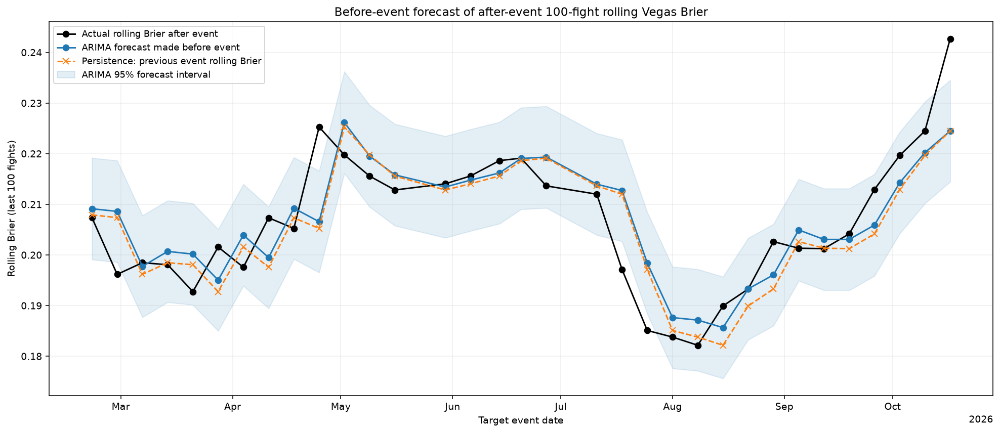

In [8]:
import warnings
from statsmodels.tsa.arima.model import ARIMA

# Independent setup: uses the same ordering and eligible rows as the original curve.
rolling_test_path = prediction_path.with_name(f"test_with_{ODDS_TYPE}.csv")
rolling_test = pd.read_csv(rolling_test_path)
rolling_test["date"] = pd.to_datetime(rolling_test.date, errors="raise")
test_order = ["date"] + (["bout_position"] if "bout_position" in rolling_test else [])
rolling_test = rolling_test.sort_values(test_order + ["fighter_red", "fighter_blue"], kind="stable")
r = pd.to_numeric(rolling_test[f"dec_{ODDS_TYPE}_red"], errors="coerce")
b = pd.to_numeric(rolling_test[f"dec_{ODDS_TYPE}_blue"], errors="coerce")
valid_test = (rolling_test.winner.isin([0, 1]) & rolling_test.date.notna()
              & pd.to_numeric(rolling_test.proba_red, errors="coerce").between(0, 1)
              & np.isfinite(r) & np.isfinite(b) & r.gt(1) & b.gt(1))
p_test = (1/r) / (1/r + 1/b)
rolling_test = rolling_test.loc[valid_test].copy()
rolling_test["vegas_brier"] = (p_test.loc[valid_test] - rolling_test.winner)**2
rolling_test = rolling_test.reset_index(drop=True)
if rolling_test.empty or rolling_test.date.min() <= scores.date.max():
    raise ValueError("Test must strictly follow the training period")
raw_train = scores.vegas_brier.to_numpy()
raw_test = rolling_test.vegas_brier.to_numpy()
# One training observation per completed event: the final 100-fight average.
train_event_rolling = scores.groupby('date', sort=True).rolling_vegas.last().dropna()
rolling_train_values = train_event_rolling.to_numpy()
combined_rolling = pd.Series(np.r_[raw_train, raw_test]).rolling(WINDOW, min_periods=WINDOW).mean()
rolling_test_actual = combined_rolling.iloc[len(raw_train):].to_numpy()

# Editable search limits: p = AR lags, q = moving-average error lags.
MAX_AR_ORDER = 5
MAX_MA_ORDER = 5
rolling_specs = [((ar, 0, ma), trend)
                 for ar in range(MAX_AR_ORDER + 1)
                 for ma in range(MAX_MA_ORDER + 1)
                 for trend in ('c', 'ct')]
# Retain integrated alternatives as well; no drift in these candidates.
rolling_specs += [((ar, 1, ma), 'n')
                  for ar in range(MAX_AR_ORDER + 1)
                  for ma in range(MAX_MA_ORDER + 1)]
print(f'Testing {len(rolling_specs)} ARIMA specifications on training data only.')
rolling_fits = {}
rolling_candidate_records = []
for order, trend in rolling_specs:
    try:
        with warnings.catch_warnings(record=True):
            candidate = ARIMA(rolling_train_values, order=order, trend=trend).fit(
                method_kwargs={"maxiter": 300})
        converged = bool(candidate.mle_retvals.get('converged', True))
        rolling_candidate_records.append(dict(order=str(order), trend=trend,
                                              AICc=candidate.aicc, BIC=candidate.bic, converged=converged))
        if converged and np.isfinite(candidate.aicc):
            rolling_fits[(order, trend)] = candidate
    except (ValueError, np.linalg.LinAlgError) as exc:
        rolling_candidate_records.append(dict(order=str(order), trend=trend,
                                              AICc=np.nan, BIC=np.nan, converged=False))
if not rolling_fits:
    raise RuntimeError("No rolling-series ARIMA candidates converged")
rolling_best_key = min(rolling_fits, key=lambda key: rolling_fits[key].aicc)
rolling_fit = rolling_fits[rolling_best_key]
rolling_candidate_table = pd.DataFrame(rolling_candidate_records).sort_values('AICc')
print("Rolling-series training selection:")
print(rolling_candidate_table.head(20).to_string(index=False))
print(f'{len(rolling_fits)} of {len(rolling_specs)} candidates converged with finite AICc.')
print('Full results: rolling_candidate_table; nonconverged candidates cannot be selected.')
print('Best converged candidates by (d, trend):')
print(rolling_candidate_table.loc[rolling_candidate_table.converged].assign(
    d=lambda frame: frame.order.map(lambda order: int(order.split(",")[1]))
).groupby(['d', 'trend'], sort=False).head(1).to_string(index=False))
print(f"Selected ARIMA{rolling_best_key[0]}, trend={rolling_best_key[1]}")

# Target for each event is the final rolling value after every fight on that card.
rolling_test['rolling_actual'] = rolling_test_actual
test_event_rolling = rolling_test.groupby('date', sort=True).rolling_actual.last()
state = rolling_fit
history = list(rolling_train_values)
records = []
for event_date, actual in test_event_rolling.items():
    # Forecast before this event; no outcomes from this card are available here.
    forecast = state.get_forecast(steps=1)
    interval = np.asarray(forecast.conf_int(alpha=.05))[0]
    records.append(dict(event_date=event_date, actual=actual,
                        ARIMA=float(np.asarray(forecast.predicted_mean)[0]),
                        Persistence=history[-1], recent20=np.mean(history[-20:]),
                        lower=interval[0], upper=interval[1],
                        information_through=(train_event_rolling.index[-1] if not records else records[-1]['event_date'])))
    # Update only after this entire event has completed.
    state = state.extend([actual])
    history.append(actual)
event_rolling_forecasts = pd.DataFrame(records).set_index('event_date')
metric_records = []
for method in ('ARIMA', 'Persistence', 'recent20'):
    error = event_rolling_forecasts[method] - event_rolling_forecasts.actual
    metric_records.append(dict(method=method, events=len(error),
                               RMSE=np.sqrt(np.mean(error**2)), MAE=np.mean(np.abs(error))))
event_rolling_accuracy = pd.DataFrame(metric_records)
print(f"\nOne forecast before each of {len(test_event_rolling)} test events; target = post-event {WINDOW}-fight rolling Brier")
print(event_rolling_accuracy.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

fig, ax = plt.subplots(figsize=(14, 6), constrained_layout=True)
ax.plot(event_rolling_forecasts.index, event_rolling_forecasts.actual, 'o-',
        color='black', label='Actual rolling Brier after event')
ax.plot(event_rolling_forecasts.index, event_rolling_forecasts.ARIMA, 'o-',
        color='tab:blue', label='ARIMA forecast made before event')
ax.plot(event_rolling_forecasts.index, event_rolling_forecasts.Persistence, 'x--',
        color='tab:orange', label='Persistence: previous event rolling Brier')
ax.fill_between(event_rolling_forecasts.index, event_rolling_forecasts.lower,
                event_rolling_forecasts.upper, color='tab:blue', alpha=.12,
                label='ARIMA 95% forecast interval')
ax.set(title=f'Before-event forecast of after-event {WINDOW}-fight rolling Vegas Brier',
       xlabel='Target event date', ylabel=f'Rolling Brier (last {WINDOW} fights)')
locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.legend(fontsize=9); ax.grid(alpha=.2)
plt.show()


## ARIMA lag search: p=15–45, d=0 or 1, q=1–10

620 combinations evaluated on the same 179 chronological one-event-ahead
training forecast origins. Select by RMSE on the **original rolling-Brier level**,
not on differences. For d=1, predict the next change and add it to the latest
observed level. Regression target dates are aligned across d=0 and d=1.

Uses two-stage Hannan–Rissanen-style ARMA estimation with a 60-lag pilot and a
common 70-observation hold-back, not maximum-likelihood ARIMA. Each model has
an intercept (a drift term in the differenced equation when d=1). Stable AR and
invertible MA coefficients are required at every origin and final refit; rejected
models and reasons remain in `arma_lag_search`. Refit coefficients at each training
origin, select without test data, then refit on all train+validation. Test forecasts
keep coefficients fixed and update observations/innovations only after each event.
The plot compares the best MA order at each AR lag for each differencing order.


620 candidates; 179 forward events per eligible candidate; 557 eligible.
 p  d  q  forecasts  eligible     RMSE      MAE reason
15  1  1        179      True 0.005455 0.004345       
15  1  2        179      True 0.005460 0.004349       
16  0  1        179      True 0.005463 0.004331       
15  0  1        179      True 0.005466 0.004334       
16  0  2        179      True 0.005466 0.004339       
15  1  3        179      True 0.005467 0.004354       
15  1  4        179      True 0.005467 0.004357       
16  1  1        179      True 0.005467 0.004346       
15  1  5        179      True 0.005468 0.004360       
16  0  3        179      True 0.005470 0.004343       
17  0  1        179      True 0.005472 0.004336       
17  1  1        179      True 0.005472 0.004346       
16  1  2        179      True 0.005472 0.004350       
17  0  2        179      True 0.005474 0.004340       
18  1  5        179      True 0.005474 0.004347       
16  1  4        179      True 0.005476 0.004357

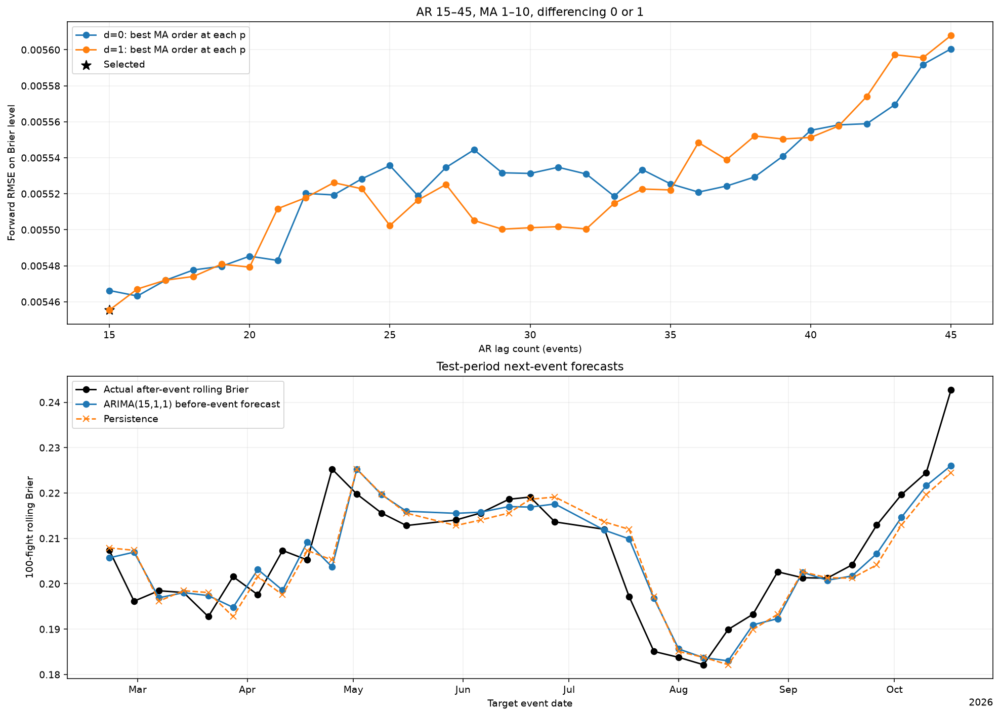

In [9]:
import warnings
from statsmodels.tsa.arima.model import ARIMA

# Independent setup: uses the same ordering and eligible rows as the original curve.
rolling_test_path = prediction_path.with_name(f"test_with_{ODDS_TYPE}.csv")
rolling_test = pd.read_csv(rolling_test_path)
rolling_test["date"] = pd.to_datetime(rolling_test.date, errors="raise")
test_order = ["date"] + (["bout_position"] if "bout_position" in rolling_test else [])
rolling_test = rolling_test.sort_values(test_order + ["fighter_red", "fighter_blue"], kind="stable")
r = pd.to_numeric(rolling_test[f"dec_{ODDS_TYPE}_red"], errors="coerce")
b = pd.to_numeric(rolling_test[f"dec_{ODDS_TYPE}_blue"], errors="coerce")
valid_test = (rolling_test.winner.isin([0, 1]) & rolling_test.date.notna()
              & pd.to_numeric(rolling_test.proba_red, errors="coerce").between(0, 1)
              & np.isfinite(r) & np.isfinite(b) & r.gt(1) & b.gt(1))
p_test = (1/r) / (1/r + 1/b)
rolling_test = rolling_test.loc[valid_test].copy()
rolling_test["vegas_brier"] = (p_test.loc[valid_test] - rolling_test.winner)**2
rolling_test = rolling_test.reset_index(drop=True)
if rolling_test.empty or rolling_test.date.min() <= scores.date.max():
    raise ValueError("Test must strictly follow the training period")
raw_train = scores.vegas_brier.to_numpy()
raw_test = rolling_test.vegas_brier.to_numpy()
# One training observation per completed event: the final 100-fight average.
train_event_rolling = scores.groupby('date', sort=True).rolling_vegas.last().dropna()
rolling_train_values = train_event_rolling.to_numpy()
combined_rolling = pd.Series(np.r_[raw_train, raw_test]).rolling(WINDOW, min_periods=WINDOW).mean()
rolling_test_actual = combined_rolling.iloc[len(raw_train):].to_numpy()


# Two-stage (Hannan-Rissanen style) conditional ARMA estimation.
from scipy.signal import lfilter
from threadpoolctl import threadpool_limits
MIN_AR_LAG, MAX_AR_LAG = 15, 45
MIN_MA_ORDER, MAX_MA_ORDER = 1, 10
DIFFERENCING_ORDERS = (0, 1)
PILOT_AR_LAG = 60
INITIAL_TRAIN_FRACTION = .70
ar_y = train_event_rolling.to_numpy()
initial_count = max(PILOT_AR_LAG + 40, int(len(ar_y) * INITIAL_TRAIN_FRACTION))
HOLD_BACK = PILOT_AR_LAG + MAX_MA_ORDER
if initial_count >= len(ar_y):
    raise ValueError('Not enough events for forward selection')

def prepare_arma_history(history):
    y = np.asarray(history, dtype=float)
    pilot_indices = np.arange(PILOT_AR_LAG, len(y))
    pilot_X = np.column_stack([np.ones(len(pilot_indices))] +
                             [y[pilot_indices-j] for j in range(1, PILOT_AR_LAG+1)])
    pilot_coef = np.linalg.lstsq(pilot_X, y[pilot_indices], rcond=None)[0]
    residual = np.zeros(len(y))
    residual[pilot_indices] = y[pilot_indices] - pilot_X @ pilot_coef
    indices = np.arange(HOLD_BACK, len(y))
    ar_columns = np.column_stack([np.ones(len(indices))] +
                                [y[indices-j] for j in range(1, MAX_AR_LAG+1)])
    ma_columns = np.column_stack([residual[indices-j] for j in range(1, MAX_MA_ORDER+1)])
    return y, indices, ar_columns, ma_columns

def fit_arma_prepared(prepared, p, q):
    y, indices, ar_columns, ma_columns = prepared
    X = np.column_stack([ar_columns[:, :p+1], ma_columns[:, :q]])
    coefficients, _, rank, _ = np.linalg.lstsq(X, y[indices], rcond=None)
    if rank < X.shape[1] or not np.isfinite(coefficients).all():
        raise ValueError('Rank-deficient ARMA fit')
    phi, theta = coefficients[1:p+1], coefficients[p+1:]
    # Enforce stable AR and invertible MA before using recursive innovations.
    if np.max(np.abs(np.roots(np.r_[1., -phi]))) >= 1:
        raise ValueError('Unstable AR coefficients')
    if q and np.max(np.abs(np.roots(np.r_[1., theta]))) >= 1:
        raise ValueError('Noninvertible MA coefficients')
    return coefficients

def forecast_arma(coefficients, history, p, q):
    y = np.asarray(history, dtype=float)
    phi, theta = coefficients[1:p+1], coefficients[p+1:]
    conditional = y.copy() - coefficients[0]
    for j, coefficient in enumerate(phi, 1):
        conditional[j:] -= coefficient*y[:-j]
    conditional[:p] = 0.
    innovations = lfilter([1.], np.r_[1., theta], conditional)
    prediction = coefficients[0] + phi @ y[-p:][::-1]
    if q:
        prediction += theta @ innovations[-q:][::-1]
    return float(prediction)

def transformed_history(history, d):
    # Align regression target dates across d=0 and d=1 candidates.
    values = np.asarray(history, dtype=float)
    return values[1:] if d == 0 else np.diff(values)

def forecast_level(coefficients, history, p, d, q):
    prediction = forecast_arma(coefficients, transformed_history(history, d), p, q)
    return prediction if d == 0 else float(history[-1] + prediction)

specs = [(p,d,q) for p in range(MIN_AR_LAG, MAX_AR_LAG+1)
         for d in DIFFERENCING_ORDERS for q in range(MIN_MA_ORDER, MAX_MA_ORDER+1)]
cv_predictions = {spec: [] for spec in specs}
failures = {}
with threadpool_limits(limits=1):
    for origin in range(initial_count, len(ar_y)):
        prepared = {d: prepare_arma_history(transformed_history(ar_y[:origin], d))
                    for d in DIFFERENCING_ORDERS}
        for spec in specs:
            if spec in failures:
                continue
            p, d, q = spec
            try:
                coefficients = fit_arma_prepared(prepared[d], p, q)
                predicted = forecast_level(coefficients, ar_y[:origin], p, d, q)
                if not np.isfinite(predicted):
                    raise ValueError('Nonfinite forecast')
                cv_predictions[spec].append(predicted)
            except ValueError as exc:
                failures[spec] = str(exc)
    final_prepared = {d: prepare_arma_history(transformed_history(ar_y, d))
                      for d in DIFFERENCING_ORDERS}
    full_fits = {}
    for spec in specs:
        if spec not in failures:
            p, d, q = spec
            try:
                full_fits[spec] = fit_arma_prepared(final_prepared[d], p, q)
            except ValueError as exc:
                failures[spec] = 'Full-training fit: ' + str(exc)

actual_cv = ar_y[initial_count:]
search_records = []
for p,d,q in specs:
    spec = (p,d,q)
    predictions = np.asarray(cv_predictions[spec])
    valid = spec not in failures and len(predictions)==len(actual_cv)
    error = predictions-actual_cv if valid else np.array([np.nan])
    search_records.append(dict(p=p,d=d,q=q, forecasts=len(predictions), eligible=valid,
        RMSE=np.sqrt(np.mean(error**2)), MAE=np.mean(np.abs(error)),
        reason=failures.get(spec,'')))
arma_lag_search = pd.DataFrame(search_records).sort_values(['RMSE','p','d','q']).reset_index(drop=True)
eligible = arma_lag_search.loc[arma_lag_search.eligible]
if eligible.empty:
    raise RuntimeError('No stable/invertible candidate completed all forward origins')
best_p, best_d, best_q = (int(eligible.iloc[0][key]) for key in ('p','d','q'))
best_coefficients = full_fits[(best_p,best_d,best_q)]
print(f'{len(specs)} candidates; {len(actual_cv)} forward events per eligible candidate; {len(eligible)} eligible.')
print(arma_lag_search.head(30).to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print('Full 620-row results: arma_lag_search. Best eligible model per differencing order:')
print(eligible.groupby('d',sort=True).head(1).to_string(index=False))
print(f'Selected ARIMA({best_p}, {best_d}, {best_q}) by training forward RMSE; two-stage estimation.')

rolling_test['rolling_actual'] = rolling_test_actual
test_event_rolling = rolling_test.groupby('date', sort=True).rolling_actual.last()
history = list(ar_y)
records=[]
for date, actual in test_event_rolling.items():
    records.append(dict(event_date=date, actual=actual,
        ARMA=forecast_level(best_coefficients,history,best_p,best_d,best_q),
        Persistence=history[-1], recent20=np.mean(history[-20:]),
        information_through=train_event_rolling.index[-1] if not records else records[-1]['event_date']))
    history.append(actual)
arma_event_forecasts=pd.DataFrame(records).set_index('event_date')
metrics=[]
for method in ('ARMA','Persistence','recent20'):
    error=arma_event_forecasts[method]-arma_event_forecasts.actual
    metrics.append(dict(method=method,events=len(error),RMSE=np.sqrt(np.mean(error**2)),MAE=np.mean(np.abs(error))))
arma_test_accuracy=pd.DataFrame(metrics)
print('\nTest accuracy (coefficients fixed; lag values and innovations updated after each event):')
print(arma_test_accuracy.to_string(index=False,float_format=lambda x:f'{x:.6f}'))

fig,axes=plt.subplots(2,1,figsize=(14,10),constrained_layout=True)
# Plot the best eligible MA order at each AR lag for each differencing order.
for d, group in eligible.groupby('d'):
    best_by_p = group.sort_values(['RMSE','q']).groupby('p',sort=True).head(1).sort_values('p')
    axes[0].plot(best_by_p.p,best_by_p.RMSE,'o-',label=f'd={d}: best MA order at each p')
axes[0].scatter([best_p],[eligible.iloc[0].RMSE],color='black',s=100,marker='*',label='Selected')
axes[0].set(xlabel='AR lag count (events)',ylabel='Forward RMSE on Brier level',
            title='AR 15–45, MA 1–10, differencing 0 or 1')
axes[1].plot(arma_event_forecasts.index,arma_event_forecasts.actual,'o-',color='black',label='Actual after-event rolling Brier')
axes[1].plot(arma_event_forecasts.index,arma_event_forecasts.ARMA,'o-',label=f'ARIMA({best_p},{best_d},{best_q}) before-event forecast')
axes[1].plot(arma_event_forecasts.index,arma_event_forecasts.Persistence,'x--',label='Persistence')
axes[1].set(xlabel='Target event date',ylabel='100-fight rolling Brier',title='Test-period next-event forecasts')
locator=mdates.AutoDateLocator()
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
for ax in axes:
    ax.legend();ax.grid(alpha=.2)
plt.show()


## ARIMAX: expected Vegas Brier as a pre-event predictor

Predictor: **100-fight rolling expected Vegas Brier at the event end**, computed
from each fight's no-vig probability `p*(1-p)`. It matches the target's window and
is known once the card and the selected odds snapshot are available. No current
or future outcomes enter the predictor. Each event's forecast receives that event's
expected score before actual results update the model.

Search AR lags 0–20 for ARIMAX, with d=1 and q=1 fixed. Each candidate fits
on the first 70% of training events and forecasts the remaining 30% one event at
a time, updating state without coefficient refitting. Select by forward RMSE,
breaking exact ties toward fewer lags. Exclude failed or nonconverged fits.
Then compare ARIMA and ARIMAX at that selected order, refitting both on all
train+validation for test evaluation. Both use maximum-likelihood estimation.
The ARIMA comparison uses the ARIMAX-selected order; it is not independently tuned.
The test set does not decide whether the feature or order should be used.

This retrospective comparison keeps the notebook's eligible settled-fight cohort.
Its event-end windows exclude eventual voids as elsewhere in the notebook, so
live deployment must explicitly handle cancellations/voids without knowing them
in advance. Opening prices are pre-event inputs here; other markets must be
available at the intended forecast time. Expected Brier is computed per fight
before averaging, not from the average probability.


Expected-Brier ARIMAX lag search: training-period next-event forecast errors
 p  d  q     RMSE      MAE  eligible reason
 1  1  1 0.005119 0.004022      True       
 8  1  1 0.005137 0.003949      True       
 7  1  1 0.005137 0.003949      True       
 9  1  1 0.005144 0.003957      True       
20  1  1 0.005175 0.003970      True       
16  1  1 0.005175 0.003970      True       
19  1  1 0.005177 0.003974      True       
15  1  1 0.005193 0.003986      True       
13  1  1 0.005207 0.004006      True       
18  1  1 0.005207 0.003988      True       
17  1  1 0.005212 0.003990      True       
14  1  1 0.005217 0.004014      True       
12  1  1 0.005224 0.004014      True       
 0  1  1 0.005235 0.004078      True       
 2  1  1 0.005241 0.004085      True       
 3  1  1 0.005259 0.004095      True       
 4  1  1 0.005273 0.004109      True       
 5  1  1 0.005293 0.004114      True       
 6  1  1 0.005308 0.004113      True       
10  1  1 0.005327 0.004098      True       

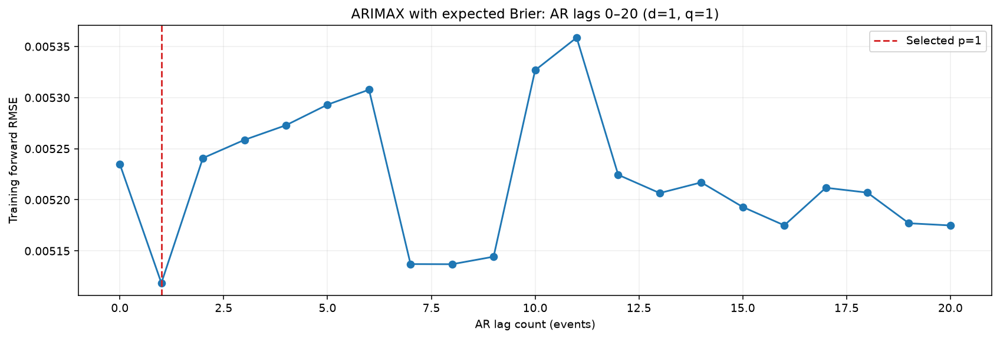

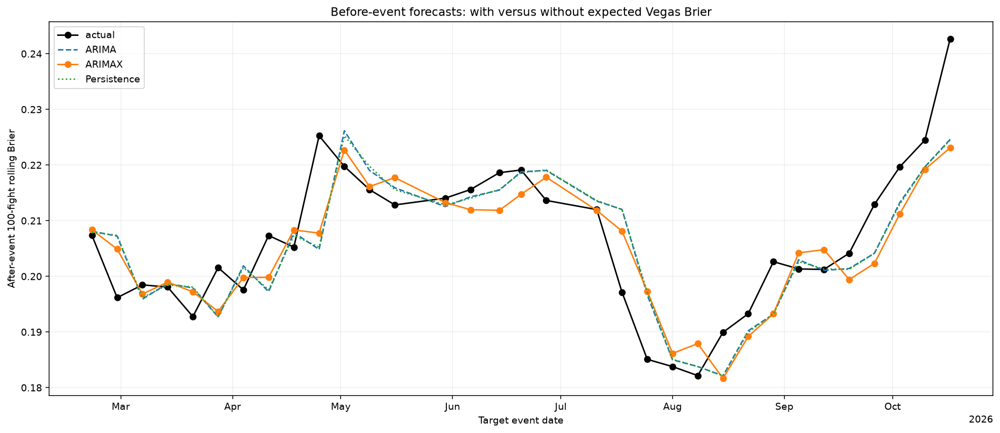

In [10]:
import warnings
from statsmodels.tsa.arima.model import ARIMA

# Independent setup: uses the same ordering and eligible rows as the original curve.
rolling_test_path = prediction_path.with_name(f"test_with_{ODDS_TYPE}.csv")
rolling_test = pd.read_csv(rolling_test_path)
rolling_test["date"] = pd.to_datetime(rolling_test.date, errors="raise")
test_order = ["date"] + (["bout_position"] if "bout_position" in rolling_test else [])
rolling_test = rolling_test.sort_values(test_order + ["fighter_red", "fighter_blue"], kind="stable")
r = pd.to_numeric(rolling_test[f"dec_{ODDS_TYPE}_red"], errors="coerce")
b = pd.to_numeric(rolling_test[f"dec_{ODDS_TYPE}_blue"], errors="coerce")
valid_test = (rolling_test.winner.isin([0, 1]) & rolling_test.date.notna()
              & pd.to_numeric(rolling_test.proba_red, errors="coerce").between(0, 1)
              & np.isfinite(r) & np.isfinite(b) & r.gt(1) & b.gt(1))
p_test = (1/r) / (1/r + 1/b)
rolling_test = rolling_test.loc[valid_test].copy()
rolling_test["vegas_brier"] = (p_test.loc[valid_test] - rolling_test.winner)**2
rolling_test = rolling_test.reset_index(drop=True)
if rolling_test.empty or rolling_test.date.min() <= scores.date.max():
    raise ValueError("Test must strictly follow the training period")
raw_train = scores.vegas_brier.to_numpy()
raw_test = rolling_test.vegas_brier.to_numpy()
# One training observation per completed event: the final 100-fight average.
train_event_rolling = scores.groupby('date', sort=True).rolling_vegas.last().dropna()
rolling_train_values = train_event_rolling.to_numpy()
combined_rolling = pd.Series(np.r_[raw_train, raw_test]).rolling(WINDOW, min_periods=WINDOW).mean()
rolling_test_actual = combined_rolling.iloc[len(raw_train):].to_numpy()



from threadpoolctl import threadpool_limits
ARIMAX_ORDER = (0, 1, 1)  # p selected below; d=1 and q=1 remain fixed
ARIMAX_LAGS = range(21)

train_prices_red = pd.to_numeric(train[f'dec_{ODDS_TYPE}_red'], errors='coerce')
train_prices_blue = pd.to_numeric(train[f'dec_{ODDS_TYPE}_blue'], errors='coerce')
train_vegas_p = (1/train_prices_red) / (1/train_prices_red + 1/train_prices_blue)
train_expected = (train_vegas_p*(1-train_vegas_p)).loc[scores.index].to_numpy()
# Recompute from the sorted eligible test frame so indices cannot misalign.
test_r = rolling_test[f'dec_{ODDS_TYPE}_red'].to_numpy(float)
test_b = rolling_test[f'dec_{ODDS_TYPE}_blue'].to_numpy(float)
test_vegas_p = (1/test_r)/(1/test_r+1/test_b)
test_expected = test_vegas_p*(1-test_vegas_p)
train_x_fights = pd.Series(train_expected).rolling(WINDOW,min_periods=WINDOW).mean()
all_x_fights = pd.Series(np.r_[train_expected,test_expected]).rolling(WINDOW,min_periods=WINDOW).mean()
train_x = pd.DataFrame({'date':scores.date.to_numpy(),'expected':train_x_fights.to_numpy()}).groupby('date').expected.last()
train_x = train_x.loc[train_event_rolling.index]
rolling_test['rolling_actual'] = rolling_test_actual
test_y = rolling_test.groupby('date',sort=True).rolling_actual.last()
test_x = pd.DataFrame({'date':rolling_test.date.to_numpy(),
                      'expected':all_x_fights.iloc[len(train_expected):].to_numpy()}).groupby('date').expected.last().loc[test_y.index]
y_train = train_event_rolling.to_numpy()
x_train = train_x.to_numpy()
if not np.isfinite(np.r_[x_train,test_x.to_numpy()]).all():
    raise ValueError('Expected Brier predictor must be finite')

fit_records=[]
def fit_comparison(y,x,use_exog,label,order=None):
    order = ARIMAX_ORDER if order is None else order
    # Scaling helps optimization of small-valued Brier data.
    y_center,y_scale=float(np.mean(y)),float(np.std(y))
    x_center,x_scale=float(np.mean(x)),float(np.std(x))
    if y_scale<=0 or x_scale<=0:
        raise ValueError('Constant training series')
    with warnings.catch_warnings(record=True) as captured:
        result=ARIMA((y-y_center)/y_scale,
            exog=((x-x_center)/x_scale)[:,None] if use_exog else None,
            order=order,trend='n' if order[1] else 'c').fit(method_kwargs={'maxiter':500})
    converged=bool(result.mle_retvals.get('converged',True))
    fit_records.append(dict(stage=label,order=str(order),model='ARIMAX' if use_exog else 'ARIMA',
                            converged=converged,warnings='; '.join(str(w.message) for w in captured)))
    if not converged:
        raise RuntimeError(f'{label} fit did not converge; do not interpret this comparison')
    return result,y_center,y_scale,x_center,x_scale

def forecast_events(fitted,y,x,use_exog):
    state,y_center,y_scale,x_center,x_scale=fitted
    predictions=[]
    for actual,predictor in zip(y,x):
        exog=np.array([[(predictor-x_center)/x_scale]]) if use_exog else None
        forecast=state.forecast(steps=1,exog=exog)
        predictions.append(float(np.asarray(forecast)[0])*y_scale+y_center)
        state=state.extend([(actual-y_center)/y_scale],exog=exog)
    return np.asarray(predictions)

cut=int(.70*len(y_train))
# Same training forecast origins for all lag orders; test outcomes are not consulted.
arimax_search_records=[]
with threadpool_limits(limits=1):
    for lag in ARIMAX_LAGS:
        try:
            fitted=fit_comparison(y_train[:cut],x_train[:cut],True,f'Lag search p={lag}',order=(lag,1,1))
            predicted=forecast_events(fitted,y_train[cut:],x_train[cut:],True)
            error=predicted-y_train[cut:]
            if not np.isfinite(error).all():
                raise ValueError('Nonfinite forecast')
            arimax_search_records.append(dict(p=lag,d=1,q=1,RMSE=np.sqrt(np.mean(error**2)),
                MAE=np.mean(np.abs(error)),eligible=True,reason=''))
        except (RuntimeError,ValueError,np.linalg.LinAlgError) as exc:
            arimax_search_records.append(dict(p=lag,d=1,q=1,RMSE=np.nan,MAE=np.nan,
                eligible=False,reason=str(exc)))
arimax_lag_search=pd.DataFrame(arimax_search_records).sort_values(['RMSE','p']).reset_index(drop=True)
eligible_search=arimax_lag_search.loc[arimax_lag_search.eligible]
if eligible_search.empty:
    raise RuntimeError('No ARIMAX lag candidates completed forward evaluation')
ARIMAX_ORDER=(int(eligible_search.iloc[0].p),1,1)
print('Expected-Brier ARIMAX lag search: training-period next-event forecast errors')
print(arimax_lag_search.to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print(f'Selected {ARIMAX_ORDER} using training forward RMSE only.')
fig,ax=plt.subplots(figsize=(12,4),constrained_layout=True)
lag_plot=arimax_lag_search.sort_values('p')
ax.plot(lag_plot.p,lag_plot.RMSE,'o-')
ax.axvline(ARIMAX_ORDER[0],color='tab:red',linestyle='--',label=f'Selected p={ARIMAX_ORDER[0]}')
ax.set(title='ARIMAX with expected Brier: AR lags 0–20 (d=1, q=1)',
       xlabel='AR lag count (events)',ylabel='Training forward RMSE')
ax.legend();ax.grid(alpha=.2)
plt.show()
comparison_metrics=[]
arimax_test_forecasts=pd.DataFrame({'actual':test_y,'expected_brier':test_x})
with threadpool_limits(limits=1):
    for use_exog in (False,True):
        name='ARIMAX' if use_exog else 'ARIMA'
        cvfit=fit_comparison(y_train[:cut],x_train[:cut],use_exog,'Training forward check')
        cvpred=forecast_events(cvfit,y_train[cut:],x_train[cut:],use_exog)
        finalfit=fit_comparison(y_train,x_train,use_exog,'Full training refit')
        testpred=forecast_events(finalfit,test_y.to_numpy(),test_x.to_numpy(),use_exog)
        arimax_test_forecasts[name]=testpred
        for stage,predicted,actual in [('Training forward',cvpred,y_train[cut:]),('Test',testpred,test_y.to_numpy())]:
            error=predicted-actual
            comparison_metrics.append(dict(stage=stage,model=name,events=len(error),
                                            RMSE=np.sqrt(np.mean(error**2)),MAE=np.mean(np.abs(error))))
# Matching persistence forecasts, using only the last completed event.
for stage,actual,last in [('Training forward',y_train[cut:],y_train[cut-1]),('Test',test_y.to_numpy(),y_train[-1])]:
    predicted=np.r_[last,actual[:-1]]
    error=predicted-actual
    comparison_metrics.append(dict(stage=stage,model='Persistence',events=len(error),
                                    RMSE=np.sqrt(np.mean(error**2)),MAE=np.mean(np.abs(error))))
    if stage=='Test':arimax_test_forecasts['Persistence']=predicted
arimax_accuracy=pd.DataFrame(comparison_metrics).sort_values(['stage','RMSE'])
arimax_fit_diagnostics=pd.DataFrame(fit_records)
print(f'Order: {ARIMAX_ORDER}; expected Brier predictor uses no-vig {ODDS_TYPE} probabilities.')
print(arimax_accuracy.to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print(arimax_fit_diagnostics[['stage','model','converged']].to_string(index=False))
fig,ax=plt.subplots(figsize=(14,6),constrained_layout=True)
for name,style in [('actual','ko-'),('ARIMA','--'),('ARIMAX','o-'),('Persistence',':')]:
    ax.plot(arimax_test_forecasts.index,arimax_test_forecasts[name],style,label=name)
ax.set(title='Before-event forecasts: with versus without expected Vegas Brier',
       xlabel='Target event date',ylabel=f'After-event {WINDOW}-fight rolling Brier')
locator=mdates.AutoDateLocator();ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.grid(alpha=.2);ax.legend()
plt.show()


## Stochastic-cycle forecast: irregular waves instead of fixed harmonics

A structural state-space model separates a changing level/trend, an optional
stochastic cycle, and observation noise. Random cycle shocks allow phase and
amplitude to change, so realized peaks need not be equally spaced. The model
still estimates a characteristic frequency; it does not explicitly estimate a
separate free period at every instant. Damping permits oscillations to fade.

Use a **daily calendar grid**, with missing observations on non-event days (no
interpolation). The Kalman filter handles these gaps. Observations remain the
post-event 100-fight rolling actual Vegas Brier. A forecast issued the day before
each event uses only completed events strictly before that issue date.

Search local-level versus local-linear-trend specifications, with no cycle,
an undamped stochastic cycle, or a damped stochastic cycle. Cycle period bounds
are 30–1,000 calendar days. Select by one-day-before-event RMSE over the final
30% of training events, then refit using all train+validation. Coefficients remain
fixed within each evaluation; filtered states update as earlier events become
available. Report a cycle-free baseline and persistence alongside the best cycle
model, even if the cycle-free model wins. Nonconverged fits are excluded.

This replaces the fixed-harmonic experiment. Test data is previously inspected,
so this remains retrospective evidence, not independent confirmation.


Training forward selection:
                                 name  trend  cycle  damped     RMSE      MAE  period_days  eligible reason
       Local trend + stochastic cycle   True   True   False 0.005526 0.004398    60.264111      True       
                          Local level  False  False   False 0.005605 0.004514          NaN      True       
Local level + damped stochastic cycle  False   True    True 0.005606 0.004515    57.871878      True       
                          Local trend   True  False   False 0.005609 0.004520          NaN      True       
Local trend + damped stochastic cycle   True   True    True 0.005610 0.004524    58.277681      True       
       Local level + stochastic cycle  False   True   False 0.005634 0.004543    62.138953      True       
Overall training winner: Local trend + stochastic cycle

Test: issued the day before each event
                         model  events     RMSE      MAE  fitted_period_days
                   Persistence      33 0.00

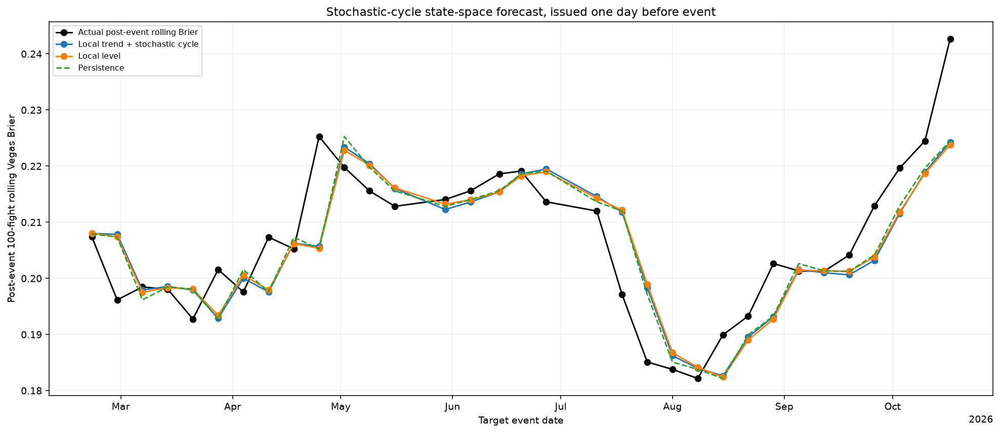

In [11]:
import warnings
from statsmodels.tsa.arima.model import ARIMA

# Independent setup: uses the same ordering and eligible rows as the original curve.
rolling_test_path = prediction_path.with_name(f"test_with_{ODDS_TYPE}.csv")
rolling_test = pd.read_csv(rolling_test_path)
rolling_test["date"] = pd.to_datetime(rolling_test.date, errors="raise")
test_order = ["date"] + (["bout_position"] if "bout_position" in rolling_test else [])
rolling_test = rolling_test.sort_values(test_order + ["fighter_red", "fighter_blue"], kind="stable")
r = pd.to_numeric(rolling_test[f"dec_{ODDS_TYPE}_red"], errors="coerce")
b = pd.to_numeric(rolling_test[f"dec_{ODDS_TYPE}_blue"], errors="coerce")
valid_test = (rolling_test.winner.isin([0, 1]) & rolling_test.date.notna()
              & pd.to_numeric(rolling_test.proba_red, errors="coerce").between(0, 1)
              & np.isfinite(r) & np.isfinite(b) & r.gt(1) & b.gt(1))
p_test = (1/r) / (1/r + 1/b)
rolling_test = rolling_test.loc[valid_test].copy()
rolling_test["vegas_brier"] = (p_test.loc[valid_test] - rolling_test.winner)**2
rolling_test = rolling_test.reset_index(drop=True)
if rolling_test.empty or rolling_test.date.min() <= scores.date.max():
    raise ValueError("Test must strictly follow the training period")
raw_train = scores.vegas_brier.to_numpy()
raw_test = rolling_test.vegas_brier.to_numpy()
# One training observation per completed event: the final 100-fight average.
train_event_rolling = scores.groupby('date', sort=True).rolling_vegas.last().dropna()
rolling_train_values = train_event_rolling.to_numpy()
combined_rolling = pd.Series(np.r_[raw_train, raw_test]).rolling(WINDOW, min_periods=WINDOW).mean()
rolling_test_actual = combined_rolling.iloc[len(raw_train):].to_numpy()





from statsmodels.tsa.statespace.structural import UnobservedComponents
from threadpoolctl import threadpool_limits

rolling_test['rolling_actual']=rolling_test_actual
test_event_rolling=rolling_test.groupby('date',sort=True).rolling_actual.last()
PERIOD_BOUNDS=(30.,1000.)
cv_start=int(.70*len(train_event_rolling))
initial_events=train_event_rolling.iloc[:cv_start]
cv_events=train_event_rolling.iloc[cv_start:]

def fit_structural(events,spec):
    spec = {**spec, **{key: bool(spec[key]) for key in ('trend','cycle','damped')}}
    daily=events.asfreq('D') # Non-event days remain NaN.
    center=float(events.mean());scale=float(events.std())
    if scale<=0:raise ValueError('Constant series')
    model=UnobservedComponents((daily-center)/scale,
        level=True,trend=spec['trend'],stochastic_level=True,
        stochastic_trend=spec['trend'],irregular=True,
        cycle=spec['cycle'],stochastic_cycle=spec['cycle'],
        damped_cycle=spec['damped'],cycle_period_bounds=PERIOD_BOUNDS)
    with warnings.catch_warnings(record=True):
        fit=model.fit(disp=False,maxiter=400)
        if not fit.mle_retvals.get('converged',True):
            fit=model.fit(start_params=fit.params,method='powell',disp=False,maxiter=600)
    if not fit.mle_retvals.get('converged',True):raise ValueError('Fit did not converge')
    frequency=fit.params.get('frequency.cycle',np.nan)
    period=2*np.pi/frequency if np.isfinite(frequency) and frequency>0 else np.nan
    return fit,center,scale,float(period)

def forecast_before_events(fitted,prior_events,targets):
    state,center,scale,_=fitted
    available_series=pd.concat([prior_events,targets]).sort_index()
    last_state_date=prior_events.index[-1]
    rows=[]
    for target_date,actual in targets.items():
        issue_date=target_date-pd.Timedelta(days=1)
        cutoff=issue_date-pd.Timedelta(days=1)
        if last_state_date>cutoff:raise ValueError('State contains information after forecast cutoff')
        if last_state_date<cutoff:
            dates=pd.date_range(last_state_date+pd.Timedelta(days=1),cutoff,freq='D')
            new_values=available_series.reindex(dates)
            state=state.extend((new_values-center)/scale)
            last_state_date=cutoff
        steps=(target_date-last_state_date).days
        forecast=state.get_forecast(steps=steps)
        predicted=float(forecast.predicted_mean.iloc[-1])*scale+center
        interval=np.asarray(forecast.conf_int())[-1]*scale+center
        known=available_series.loc[available_series.index<=cutoff]
        rows.append(dict(event_date=target_date,issue_date=issue_date,
                         information_through=known.index[-1],actual=actual,
                         prediction=predicted,lower=interval[0],upper=interval[1],
                         Persistence=known.iloc[-1]))
    return pd.DataFrame(rows).set_index('event_date')

specifications=[]
for trend in (False,True):
    for cycle,damped in [(False,False),(True,False),(True,True)]:
        name=('Local trend' if trend else 'Local level') + (' + damped stochastic cycle' if damped else ' + stochastic cycle' if cycle else '')
        specifications.append(dict(name=name,trend=trend,cycle=cycle,damped=damped))
search=[]
with threadpool_limits(limits=1):
    for spec in specifications:
        try:
            fitted=fit_structural(initial_events,spec)
            predicted=forecast_before_events(fitted,initial_events,cv_events)
            error=predicted.prediction-predicted.actual
            if not np.isfinite(error).all():raise ValueError('Nonfinite forecasts')
            search.append(dict(**spec,RMSE=np.sqrt(np.mean(error**2)),MAE=np.mean(np.abs(error)),
                               period_days=fitted[3],eligible=True,reason=''))
        except (ValueError,np.linalg.LinAlgError) as exc:
            search.append(dict(**spec,RMSE=np.nan,MAE=np.nan,period_days=np.nan,eligible=False,reason=str(exc)))
stochastic_cycle_search=pd.DataFrame(search).sort_values('RMSE').reset_index(drop=True)
valid=stochastic_cycle_search.loc[stochastic_cycle_search.eligible]
if valid.empty or not valid.cycle.any():raise RuntimeError('No eligible stochastic-cycle fit')
best_cycle=valid.loc[valid.cycle].iloc[0]
best_baseline=valid.loc[~valid.cycle].iloc[0]
print('Training forward selection:')
print(stochastic_cycle_search.to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print('Overall training winner:',valid.iloc[0]['name'])

cycle_test_forecasts={};test_metrics=[]
with threadpool_limits(limits=1):
    for row in (best_cycle,best_baseline):
        spec={key:row[key] for key in ('name','trend','cycle','damped')}
        fitted=fit_structural(train_event_rolling,spec)
        predictions=forecast_before_events(fitted,train_event_rolling,test_event_rolling)
        cycle_test_forecasts[spec['name']]=predictions
        error=predictions.prediction-predictions.actual
        test_metrics.append(dict(model=spec['name'],events=len(error),RMSE=np.sqrt(np.mean(error**2)),
                                 MAE=np.mean(np.abs(error)),fitted_period_days=fitted[3]))
reference=next(iter(cycle_test_forecasts.values()))
error=reference.Persistence-reference.actual
test_metrics.append(dict(model='Persistence',events=len(error),RMSE=np.sqrt(np.mean(error**2)),
                         MAE=np.mean(np.abs(error)),fitted_period_days=np.nan))
stochastic_cycle_test_accuracy=pd.DataFrame(test_metrics).sort_values('RMSE')
print('\nTest: issued the day before each event')
print(stochastic_cycle_test_accuracy.to_string(index=False,float_format=lambda x:f'{x:.6f}'))

fig,ax=plt.subplots(figsize=(14,6),constrained_layout=True)
ax.plot(reference.index,reference.actual,'ko-',label='Actual post-event rolling Brier')
for name,predictions in cycle_test_forecasts.items():
    ax.plot(predictions.index,predictions.prediction,'o-',label=name)
ax.plot(reference.index,reference.Persistence,'--',label='Persistence')
ax.set(title='Stochastic-cycle state-space forecast, issued one day before event',
       xlabel='Target event date',ylabel='Post-event 100-fight rolling Vegas Brier')
locator=mdates.AutoDateLocator();ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.legend(fontsize=8);ax.grid(alpha=.2)
plt.show()


## Detrended rolling actual Vegas Brier

Train + validation, using the existing 100-fight rolling average. Fit a straight
line against elapsed calendar days over this displayed period, then subtract it.
Only the residual is plotted. This is retrospective linear detrending, not a
forecast or a causal feature: the fitted line uses the whole displayed period.


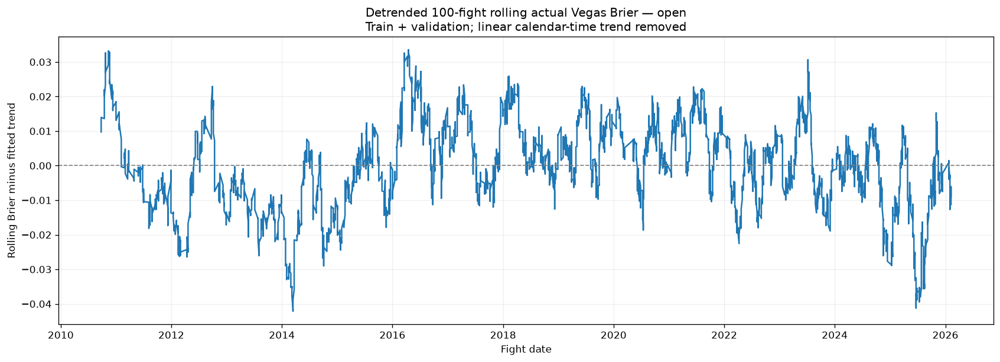

In [5]:
detrended_brier = scores.loc[scores.rolling_vegas.notna(), ["date", "rolling_vegas"]].copy()
elapsed_days = (detrended_brier.date - detrended_brier.date.min()).dt.total_seconds().to_numpy() / 86400
trend_design = np.column_stack([np.ones(len(elapsed_days)), elapsed_days])
trend_coefficients = np.linalg.lstsq(trend_design, detrended_brier.rolling_vegas.to_numpy(), rcond=None)[0]
detrended_brier["linear_trend"] = trend_design @ trend_coefficients
detrended_brier["residual"] = detrended_brier.rolling_vegas - detrended_brier.linear_trend

fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
ax.plot(detrended_brier.date, detrended_brier.residual, color="tab:blue")
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set(title=f"Detrended {WINDOW}-fight rolling actual Vegas Brier — {ODDS_TYPE}"
             "\nTrain + validation; linear calendar-time trend removed",
       xlabel="Fight date", ylabel="Rolling Brier minus fitted trend")
locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.grid(alpha=.2)
plt.show()


## Cycle tests: train + validation rolling Brier advantage

Advantage = **Vegas Brier minus model Brier**; positive favors the model. Use the
same 100-fight rolling average and eligible train+validation fights as above.
These model probabilities were fitted on train+validation, so findings concern
in-sample advantage, not demonstrated future betting performance.

Two exploratory tests, with periods from 200 fights (2 × window) to one-third
of the rolling-series length:
1. Maximum spectral power after linear detrending.
2. Maximum repeated autocorrelation alignment: average normalized ACF at lag T
   and lag 2T, searching all integer T in that period range. This measures recurring
   shape alignment rather than absolute amplitude. Negative ACF is not rewarded.

Shuffle whole event blocks without replacement 2,000 times, keeping paired model
and Vegas errors and within-event fight order together. Recompute rolling averages,
detrending, and the full period search for every shuffle. The null is random event
ordering (exchangeable event blocks), not every conceivable noncyclical process.
Report Monte Carlo p-values with +1 correction and Holm adjustment across the two
tests. Overlap-induced dependence is present in both observed and shuffled curves.

Rejecting this null shows temporal structure inconsistent with random ordering;
trend changes or regimes can also cause rejection. It does not by itself establish
stable future cycles. Failing to reject is not proof that no cycle exists. Periods
are in fights, not calendar days, and these tests follow visual exploration.


Train+validation: 4658 fights, 609 events; window=100.
Tested periods: 200–1519 fights; 2000 whole-event shuffles.
                              test  observed  candidate_period_fights  permutation_p  Holm_adjusted_p  reject_at_5pct
  Maximum detrended spectral power  0.000006               303.933333       0.637681         1.000000           False
Repeated ACF alignment at T and 2T  0.087377               889.000000       0.850075         1.000000           False
Probabilities are in-sample trainval fits. These are exploratory temporal-structure tests.


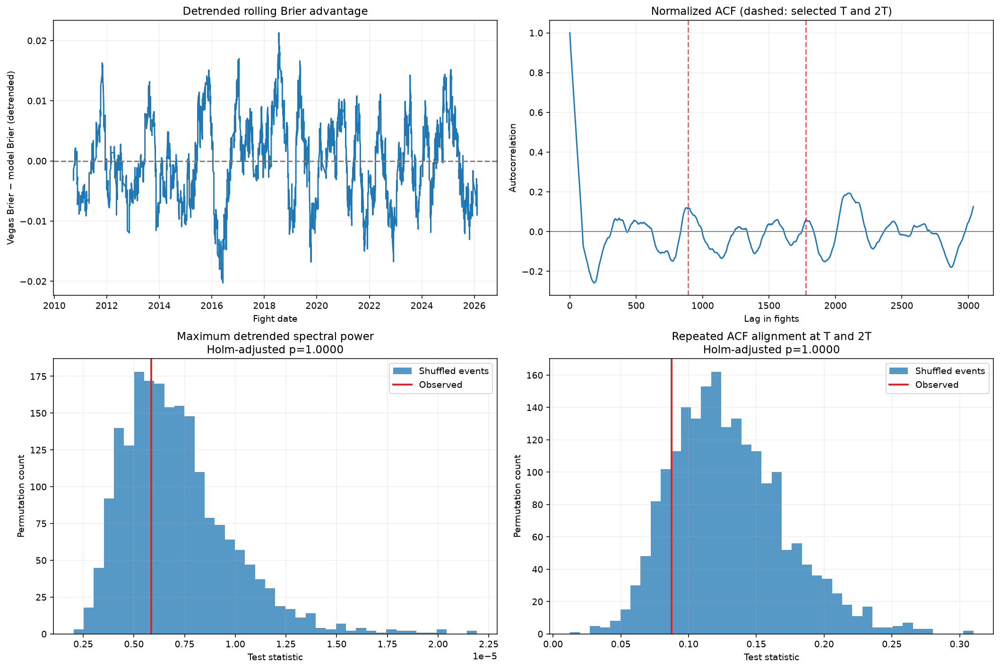

In [13]:
from scipy.signal import detrend, periodogram
from scipy.fft import rfft, irfft, next_fast_len

ADVANTAGE_PERMUTATIONS = 2000
ADVANTAGE_SEED = 42
advantage_fights = scores[["date", "vegas_brier", "model_brier"]].copy()
advantage_fights["advantage"] = advantage_fights.vegas_brier - advantage_fights.model_brier

def advantage_rolling(values):
    cumulative = np.r_[0., np.cumsum(values, dtype=float)]
    return (cumulative[WINDOW:] - cumulative[:-WINDOW]) / WINDOW

observed_advantage = advantage_rolling(advantage_fights.advantage.to_numpy())
advantage_dates = advantage_fights.date.iloc[WINDOW-1:]
MIN_CYCLE = 2 * WINDOW
MAX_CYCLE = len(observed_advantage) // 3
if MAX_CYCLE <= MIN_CYCLE:
    raise ValueError("Insufficient data for at least three repetitions in the tested range")
cycle_lags = np.arange(MIN_CYCLE, MAX_CYCLE+1)

def advantage_cycle_metrics(values):
    residual = detrend(values, type='linear')
    frequency, power = periodogram(residual, detrend=False, scaling='spectrum')
    mask = (frequency >= 1/MAX_CYCLE) & (frequency <= 1/MIN_CYCLE)
    spectral_indices = np.flatnonzero(mask)
    peak = spectral_indices[np.argmax(power[mask])]
    nfft = next_fast_len(2*len(residual)-1)
    transform = rfft(residual, nfft)
    covariance = irfft(transform * transform.conj(), nfft)[:len(residual)]
    if covariance[0] <= 0:
        raise ValueError('Constant advantage series')
    acf = covariance / covariance[0]
    alignment = (acf[cycle_lags] + acf[2*cycle_lags]) / 2
    best = int(np.argmax(alignment))
    return dict(power=float(power[peak]), spectral_period=float(1/frequency[peak]),
                alignment=float(alignment[best]), acf_period=int(cycle_lags[best]),
                acf=acf, residual=residual, frequency=frequency, spectrum=power)

observed_cycle = advantage_cycle_metrics(observed_advantage)
blocks = [group.advantage.to_numpy() for _,group in advantage_fights.groupby('date',sort=True)]
rng = np.random.default_rng(ADVANTAGE_SEED)
null_statistics = np.empty((ADVANTAGE_PERMUTATIONS,2))
for iteration in range(ADVANTAGE_PERMUTATIONS):
    shuffled = np.concatenate([blocks[j] for j in rng.permutation(len(blocks))])
    result = advantage_cycle_metrics(advantage_rolling(shuffled))
    null_statistics[iteration] = result['power'], result['alignment']
observed_stats = np.array([observed_cycle['power'],observed_cycle['alignment']])
raw_p = (1 + (null_statistics >= observed_stats).sum(axis=0))/(ADVANTAGE_PERMUTATIONS+1)
order = np.argsort(raw_p)
adjusted_p = np.empty(2)
adjusted_p[order] = np.minimum(1, np.maximum.accumulate(raw_p[order] * np.array([2,1])))
advantage_cycle_results = pd.DataFrame({
    'test':['Maximum detrended spectral power','Repeated ACF alignment at T and 2T'],
    'observed':observed_stats,
    'candidate_period_fights':[observed_cycle['spectral_period'],observed_cycle['acf_period']],
    'permutation_p':raw_p, 'Holm_adjusted_p':adjusted_p,
    'reject_at_5pct':adjusted_p<.05,
})
print(f'Train+validation: {len(advantage_fights)} fights, {len(blocks)} events; window={WINDOW}.')
print(f'Tested periods: {MIN_CYCLE}–{MAX_CYCLE} fights; {ADVANTAGE_PERMUTATIONS} whole-event shuffles.')
print(advantage_cycle_results.to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print('Probabilities are in-sample trainval fits. These are exploratory temporal-structure tests.')

fig,axes = plt.subplots(2,2,figsize=(15,10),constrained_layout=True)
axes[0,0].plot(advantage_dates,observed_cycle['residual'])
axes[0,0].axhline(0,color='gray',linestyle='--')
axes[0,0].set(title='Detrended rolling Brier advantage',xlabel='Fight date',ylabel='Vegas Brier − model Brier (detrended)')
locator=mdates.AutoDateLocator();axes[0,0].xaxis.set_major_locator(locator)
axes[0,0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
axes[0,1].plot(np.arange(2*MAX_CYCLE+1),observed_cycle['acf'][:2*MAX_CYCLE+1])
for lag in (observed_cycle['acf_period'],2*observed_cycle['acf_period']):
    axes[0,1].axvline(lag,color='tab:red',linestyle='--',alpha=.7)
axes[0,1].axhline(0,color='gray',linewidth=1)
axes[0,1].set(title='Normalized ACF (dashed: selected T and 2T)',xlabel='Lag in fights',ylabel='Autocorrelation')
for j,ax in enumerate(axes[1]):
    ax.hist(null_statistics[:,j],bins=40,alpha=.75,label='Shuffled events')
    ax.axvline(observed_stats[j],color='tab:red',linewidth=2,label='Observed')
    ax.set(title=f'{advantage_cycle_results.test.iloc[j]}\nHolm-adjusted p={adjusted_p[j]:.4f}',
           xlabel='Test statistic',ylabel='Permutation count')
    ax.legend()
for ax in axes.flat:ax.grid(alpha=.2)
plt.show()


## Adaptive oscillator for detrended rolling Brier advantage

Target: event-end 100-fight rolling **Vegas Brier minus model Brier**. Positive
advantage favors the model. Remove a linear calendar-time trend fitted on training
history only. Unlike fixed harmonics, this oscillator has a time-varying frequency:
a noisy two-dimensional rotation represents the wave and its phase, while log
frequency follows a random walk. An extended Kalman filter learns amplitude,
phase, and frequency from successive observations. Candidate periods are bounded
to 30–1,000 days; seed periods are initialization choices, not fixed cycle lengths.

Tune process/observation noise and initial period using next-event forecast RMSE
on the last 30% of training events. Its detrending line uses only the initial 70%.
Then refit the trend on all train+validation and filter through that history before
forecasting test events. Each forecast is recorded before its event observation
updates the state. No test outcomes select settings or fit the trend.

**Filtered tracking** uses the current event observation and is not a forecast.
It is shown separately from **pre-event predictions**. The estimated period is a
model interpretation, not proof of a physical cycle; frequency changes can be
weakly identified. All trainval model probabilities are in-sample; test predictions
are from the separate test export. This remains retrospective, previously explored
data. The event-end target retains the notebook's settled-fight cohort.


Training forward candidates (top 8):
 seed_period  amplitude_noise  frequency_noise  observation_noise     RMSE      MAE
   60.000000         0.020000         0.005000           0.050000 0.003075 0.002406
  180.000000         0.020000         0.005000           0.050000 0.003075 0.002406
  540.000000         0.020000         0.005000           0.050000 0.003075 0.002406
  540.000000         0.020000         0.030000           0.050000 0.003188 0.002555
   60.000000         0.020000         0.030000           0.050000 0.003188 0.002555
  180.000000         0.020000         0.030000           0.050000 0.003191 0.002557
   60.000000         0.020000         0.005000           0.200000 0.003881 0.003054
  180.000000         0.020000         0.005000           0.200000 0.003881 0.003054
Selected adaptive-oscillator settings: {'seed_period': 60.0, 'amplitude_noise': 0.02, 'frequency_noise': 0.005, 'observation_noise': 0.05}

Test forecasts on detrended advantage (prediction = oscillator):
  

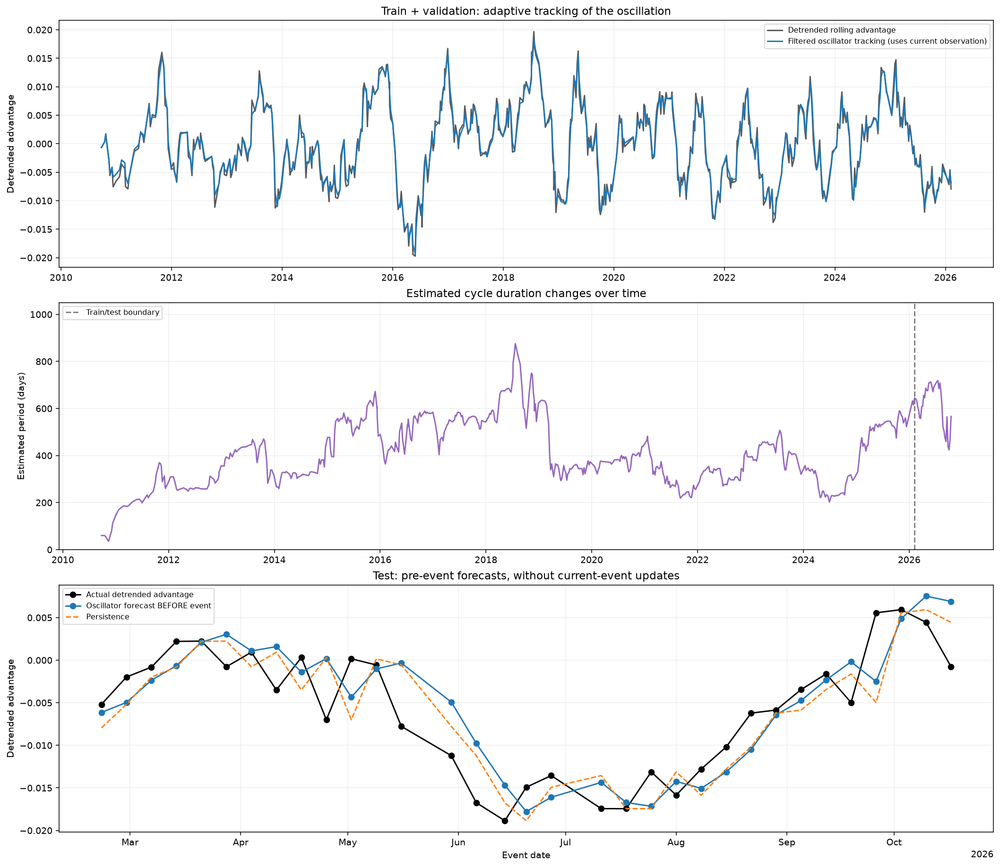

In [14]:
from itertools import product

# Build the same advantage series, sampled once at the end of each event.
osc_train_fights=scores[['date','model_brier','vegas_brier']].copy()
osc_train_fights['raw_advantage']=osc_train_fights.vegas_brier-osc_train_fights.model_brier
osc_train_fights['rolling_advantage']=osc_train_fights.raw_advantage.rolling(WINDOW,min_periods=WINDOW).mean()
osc_train=osc_train_fights.groupby('date',sort=True).rolling_advantage.last().dropna()
osc_test_path=prediction_path.with_name(f'test_with_{ODDS_TYPE}.csv')
osc_test_fights=pd.read_csv(osc_test_path)
osc_test_fights['date']=pd.to_datetime(osc_test_fights.date)
osc_sort=['date']+(['bout_position'] if 'bout_position' in osc_test_fights else [])+['fighter_red','fighter_blue']
osc_test_fights=osc_test_fights.sort_values(osc_sort,kind='stable').reset_index(drop=True)
r=pd.to_numeric(osc_test_fights[f'dec_{ODDS_TYPE}_red'],errors='coerce')
b=pd.to_numeric(osc_test_fights[f'dec_{ODDS_TYPE}_blue'],errors='coerce')
m=pd.to_numeric(osc_test_fights.proba_red,errors='coerce')
valid_osc=(osc_test_fights.winner.isin([0,1]) & osc_test_fights.date.notna() & m.between(0,1)
           & np.isfinite(r) & np.isfinite(b) & r.gt(1) & b.gt(1))
v=(1/r)/(1/r+1/b)
osc_test_fights['raw_advantage']=(v-osc_test_fights.winner)**2-(m-osc_test_fights.winner)**2
osc_test_fights=osc_test_fights.loc[valid_osc].copy()
combined=pd.Series(np.r_[osc_train_fights.raw_advantage.to_numpy(),osc_test_fights.raw_advantage.to_numpy()])
osc_test_fights['rolling_advantage']=combined.rolling(WINDOW,min_periods=WINDOW).mean().iloc[len(osc_train_fights):].to_numpy()
osc_test=osc_test_fights.groupby('date',sort=True).rolling_advantage.last()
if osc_test.index.min()<=osc_train.index.max():raise ValueError('Overlapping train/test events')
OSC_ORIGIN=osc_train.index[0]

def oscillator_trend_fit(series):
    t=(series.index-OSC_ORIGIN).days.to_numpy()/365.25
    design=np.column_stack([np.ones(len(t)),t])
    coefficient=np.linalg.lstsq(design,series.to_numpy(),rcond=None)[0]
    residual=series.to_numpy()-design@coefficient
    scale=float(np.std(residual))
    if scale<=0:raise ValueError('Constant detrended series')
    return coefficient,scale

def oscillator_trend(dates,coefficient):
    t=(pd.DatetimeIndex(dates)-OSC_ORIGIN).days.to_numpy()/365.25
    return coefficient[0]+coefficient[1]*t

def oscillator_path(series,coefficient,scale,seed_period,amplitude_noise,frequency_noise,observation_noise):
    # State = [wave coordinate, quadrature coordinate, log angular frequency].
    # Rotation uses actual elapsed days between observations.
    residual=(series.to_numpy()-oscillator_trend(series.index,coefficient))/scale
    state=np.array([residual[0],0.,np.log(2*np.pi/seed_period)])
    covariance=np.diag([observation_noise**2,1.,.25])
    low,high=np.log(2*np.pi/1000),np.log(2*np.pi/30)
    rows=[]
    previous=series.index[0]
    H=np.array([1.,0.,0.])
    for i,(date,actual) in enumerate(zip(series.index,residual)):
        dt=float((date-previous).days)
        if i:
            omega=np.exp(state[2]);theta=omega*dt
            c,s=np.cos(theta),np.sin(theta)
            x,z,log_frequency=state
            predicted=np.array([c*x-s*z,s*x+c*z,log_frequency])
            jacobian=np.array([[c,-s,(-s*x-c*z)*theta],
                               [s,c,(c*x-s*z)*theta],[0.,0.,1.]])
            process=np.diag([amplitude_noise**2*dt,amplitude_noise**2*dt,frequency_noise**2*dt])
            covariance=jacobian@covariance@jacobian.T+process
            state=predicted
        pre=float(state[0])
        # Current outcome is used only after the prediction above is recorded.
        variance=float(covariance[0,0]+observation_noise**2)
        gain=covariance[:,0]/variance
        state=state+gain*(actual-state[0])
        state[2]=np.clip(state[2],low,high)
        adjustment=np.eye(3)-np.outer(gain,H)
        covariance=adjustment@covariance@adjustment.T+np.outer(gain,gain)*observation_noise**2
        covariance=(covariance+covariance.T)/2
        rows.append(dict(date=date,actual=actual*scale,prediction=pre*scale,
                         filtered=state[0]*scale,period_days=2*np.pi/np.exp(state[2]),
                         amplitude=np.hypot(state[0],state[1])*scale))
        previous=date
    return pd.DataFrame(rows).set_index('date')

osc_cut=int(.70*len(osc_train))
cv_trend,cv_scale=oscillator_trend_fit(osc_train.iloc[:osc_cut])
osc_candidates=[]
for seed,amp,freq,noise in product([60.,180.,540.],[.005,.02],[.005,.03],[.05,.2]):
    params=dict(seed_period=seed,amplitude_noise=amp,frequency_noise=freq,observation_noise=noise)
    path=oscillator_path(osc_train,cv_trend,cv_scale,**params).iloc[osc_cut:]
    error=path.prediction-path.actual
    osc_candidates.append(dict(**params,RMSE=np.sqrt(np.mean(error**2)),MAE=np.mean(np.abs(error))))
oscillator_search=pd.DataFrame(osc_candidates).sort_values('RMSE').reset_index(drop=True)
osc_best={key:float(oscillator_search.iloc[0][key]) for key in
          ('seed_period','amplitude_noise','frequency_noise','observation_noise')}
osc_coefficient,osc_scale=oscillator_trend_fit(osc_train)
osc_all=pd.concat([osc_train,osc_test])
oscillator_results=oscillator_path(osc_all,osc_coefficient,osc_scale,**osc_best)
oscillator_results['trend']=oscillator_trend(oscillator_results.index,osc_coefficient)
oscillator_results['advantage_forecast']=oscillator_results.prediction+oscillator_results.trend
# First observation only initializes the filter; never evaluate it as a forecast.
osc_eval=oscillator_results.loc[osc_test.index].copy()
osc_eval['Persistence']=oscillator_results.actual.shift(1).loc[osc_test.index]
osc_eval['Raw advantage persistence']=osc_all.shift(1).loc[osc_test.index]-osc_eval.trend
metrics=[]
for method in ('prediction','Persistence','Raw advantage persistence'):
    error=osc_eval[method]-osc_eval.actual
    metrics.append(dict(model=method,events=len(error),RMSE=np.sqrt(np.mean(error**2)),MAE=np.mean(np.abs(error))))
oscillator_test_accuracy=pd.DataFrame(metrics).sort_values('RMSE')
print('Training forward candidates (top 8):')
print(oscillator_search.head(8).to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print('Selected adaptive-oscillator settings:',osc_best)
print('\nTest forecasts on detrended advantage (prediction = oscillator):')
print(oscillator_test_accuracy.to_string(index=False,float_format=lambda x:f'{x:.6f}'))

fig,axes=plt.subplots(3,1,figsize=(15,13),constrained_layout=True)
training=oscillator_results.loc[osc_train.index]
axes[0].plot(training.index,training.actual,color='black',alpha=.65,label='Detrended rolling advantage')
axes[0].plot(training.index,training.filtered,color='tab:blue',label='Filtered oscillator tracking (uses current observation)')
axes[0].set(title='Train + validation: adaptive tracking of the oscillation',ylabel='Detrended advantage')
axes[1].plot(oscillator_results.index,oscillator_results.period_days,color='tab:purple')
axes[1].axvline(osc_train.index[-1],color='gray',linestyle='--',label='Train/test boundary')
axes[1].set(title='Estimated cycle duration changes over time',ylabel='Estimated period (days)',ylim=(0,1050))
axes[2].plot(osc_eval.index,osc_eval.actual,'ko-',label='Actual detrended advantage')
axes[2].plot(osc_eval.index,osc_eval.prediction,'o-',label='Oscillator forecast BEFORE event')
axes[2].plot(osc_eval.index,osc_eval.Persistence,'--',label='Persistence')
axes[2].set(title='Test: pre-event forecasts, without current-event updates',ylabel='Detrended advantage',xlabel='Event date')
for ax in axes:
    locator=mdates.AutoDateLocator();ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.grid(alpha=.2)
    handles,_=ax.get_legend_handles_labels()
    if handles:ax.legend(fontsize=8)
plt.show()


## Does rolling Brier advantage correlate with strategy returns?

Use only the opening inference model **fitted on training data alone**, evaluated
on its saved validation backtest. Each fight's probability is verified against
`report_predictions/train/open/inference/val_with_open.csv`. This cell is pinned
to that source independently of FIT_MODE or model settings elsewhere in the notebook.
The trainval-fitted test run is excluded.

Return = 100 × (moneyline P/L + parlay P/L) / event-start bankroll. Event-level
fields are counted once, not once per fight. No-bet events remain in the sample;
post-ruin events are excluded. This is event bankroll return, not ROI on stake.

For all settled fights and for actually placed settled moneylines, compute
100-fight rolling Vegas-minus-model Brier advantage from the saved results.
Require a full window, separately within each saved backtest period. Sample at
event ends. **Same-event** advantage includes the current event's outcomes. No prior-event
comparison is computed.
On events with no settled choices, retain the previous complete choice-window value.

Report Pearson and Spearman correlations, plus 95% percentile moving-block
bootstrap intervals for Pearson (5 consecutive events per block, 2,000 resamples).
These account approximately for dependence but are exploratory and sensitive to
block length, especially in small samples. No conventional iid p-values are used.
Same-event associations can reflect shared outcomes; these are descriptive
associations, not evidence of a forecasting signal. Bet selection was optimized historically,
and this test period has already been inspected, so neither proves future profit.

All-fights and choice windows each require 100 observations. Because selected
moneyline bets accumulate more slowly, their first full window occurs later,
leaving fewer eligible event dates for correlation.


Source: opening inference model fitted on train only; validation observations. Probabilities verified against saved prediction export.
Same-event analysis only. Advantage and returns both include current-event outcomes. Returns include singles and parlays.
Validation all: 63 events; first complete window 2024-07-27
Validation choices: 43 events; first complete window 2025-02-01
    period  cohort timing  events  Pearson  Spearman  CI_low  CI_high
Validation     all   same      63   0.2875    0.2337  0.0183   0.4682
Validation choices   same      43   0.1992    0.1925 -0.1159   0.3141


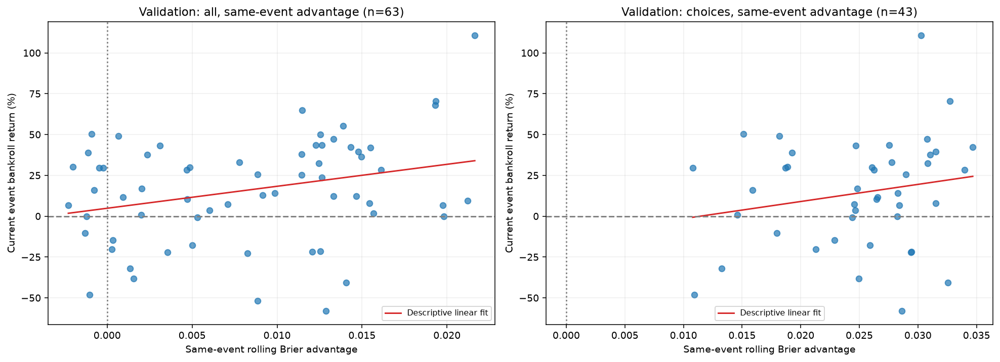

In [15]:
from scipy.stats import pearsonr, spearmanr

RETURN_WINDOW = 100
RETURN_BOOTSTRAPS = 2000
RETURN_BLOCK_EVENTS = 5
RETURN_SEED = 42
backtest_root = settings.data_dir / 'backtest_results' / 'model_comparisons' / 'inference_market_models'
# Pin this analysis to the opening inference model fitted on TRAIN ONLY.
RETURN_ODDS_TYPE = 'open'
return_paths = {'Validation': backtest_root / 'train_val_open_with_open_inference_no_decay_moneylines.csv'}
return_prediction_path = (settings.data_dir / 'model_comparisons' / 'lr_open_close'
                          / 'report_predictions' / 'train' / 'open' / 'inference' / 'val_with_open.csv')
return_reference = pd.read_csv(return_prediction_path)
if not return_reference.probability_model.eq('inference').all():
    raise ValueError('Expected inference probabilities')

def strategy_advantage_events(path):
    frame = pd.read_csv(path)
    keys = ['date','fighter_red','fighter_blue']
    matched = frame.merge(return_reference[keys+['proba_red']],on=keys,how='outer',
                          validate='one_to_one',indicator=True)
    if not matched['_merge'].eq('both').all():
        raise ValueError('Backtest and train-only validation predictions do not match')
    saved_red = matched.choice_proba.where(matched.pred_winner.eq(1),1-matched.choice_proba)
    np.testing.assert_allclose(saved_red,matched.proba_red,rtol=1e-10,atol=1e-12)

    frame['date'] = pd.to_datetime(frame.date).dt.normalize()
    frame = frame.sort_values('date', kind='stable').reset_index(drop=True)
    event_columns = ['bankroll_postevent', 'event_payout_money_line', 'parlay_net']
    if (frame.groupby('date')[event_columns].nunique(dropna=False)>1).any().any():
        raise ValueError('Expected identical event-level balances/P&L within each date')
    events = frame.groupby('date',sort=True)[event_columns].first()
    events['profit'] = events.event_payout_money_line + events.parlay_net
    events['starting_bankroll'] = events.bankroll_postevent - events.profit
    np.testing.assert_allclose(events.starting_bankroll.iloc[1:],events.bankroll_postevent.iloc[:-1],rtol=1e-7,atol=1e-6)
    events['return_pct'] = 100*events.profit/events.starting_bankroll.where(events.starting_bankroll>0)
    if 'choice_proba' in frame:
        model = frame.choice_proba.where(frame.pred_winner.eq(1),1-frame.choice_proba)
    else:
        model = frame.proba_red
    red,blue = f'dec_{RETURN_ODDS_TYPE}_red',f'dec_{RETURN_ODDS_TYPE}_blue'
    if red not in frame: red,blue='real_odds_red','real_odds_blue'
    prices = frame[[red,blue]].to_numpy(float)
    vegas = (1/frame[red])/(1/frame[red]+1/frame[blue])
    valid = (frame.winner.isin([0,1]) & model.between(0,1) & np.isfinite(prices).all(axis=1)
             & (prices>1).all(axis=1))
    frame['advantage'] = (vegas-frame.winner)**2 - (model-frame.winner)**2
    placed = frame.choice_fstar.gt(0) & frame.date.map(events.starting_bankroll).gt(0)
    for cohort,mask in [('all',valid),('choices',valid & placed)]:
        fights=frame.loc[mask,['date','advantage']].copy()
        fights['rolling']=fights.advantage.rolling(RETURN_WINDOW,min_periods=RETURN_WINDOW).mean()
        event_advantage=fights.groupby('date',sort=True)['rolling'].last()
        events[f'{cohort}_same']=event_advantage.reindex(events.index).ffill()
    return events

def block_correlation_interval(x,y,rng):
    n=len(x);length=min(RETURN_BLOCK_EVENTS,n)
    starts=rng.integers(0,n-length+1,size=(RETURN_BOOTSTRAPS,int(np.ceil(n/length))))
    indices=(starts[:,:,None]+np.arange(length)).reshape(RETURN_BOOTSTRAPS,-1)[:,:n]
    a=x[indices];b=y[indices]
    a=a-a.mean(axis=1,keepdims=True);b=b-b.mean(axis=1,keepdims=True)
    denominator=np.sqrt((a*a).sum(axis=1)*(b*b).sum(axis=1))
    correlations=np.divide((a*b).sum(axis=1),denominator,out=np.full(RETURN_BOOTSTRAPS,np.nan),where=denominator>0)
    finite=correlations[np.isfinite(correlations)]
    return np.quantile(finite,[.025,.975]) if len(finite) else [np.nan,np.nan]

return_event_data={};correlation_records=[]
rng=np.random.default_rng(RETURN_SEED)
for period,path in return_paths.items():
    events=strategy_advantage_events(path)
    return_event_data[period]=events
    for cohort in ('all','choices'):
        for timing in ('same',):
            sample=events[[f'{cohort}_{timing}','return_pct']].dropna()
            x=sample.iloc[:,0].to_numpy();y=sample.return_pct.to_numpy()
            pearson=spearman=lo=hi=np.nan
            if len(sample)>=4 and np.std(x)>0 and np.std(y)>0:
                pearson=float(pearsonr(x,y).statistic);spearman=float(spearmanr(x,y).statistic)
                lo,hi=block_correlation_interval(x,y,rng)
            correlation_records.append(dict(period=period,cohort=cohort,timing=timing,events=len(sample),
                Pearson=pearson,Spearman=spearman,CI_low=lo,CI_high=hi))
return_correlation_results=pd.DataFrame(correlation_records)
print('Source: opening inference model fitted on train only; validation observations. Probabilities verified against saved prediction export.')
print('Same-event analysis only. Advantage and returns both include current-event outcomes. Returns include singles and parlays.')
for period, event_data in return_event_data.items():
    for cohort in ('all','choices'):
        eligible_events = event_data[[f'{cohort}_same','return_pct']].dropna()
        print(f'{period} {cohort}: {len(eligible_events)} events; first complete window {eligible_events.index.min():%Y-%m-%d}')
print(return_correlation_results.to_string(index=False,float_format=lambda x:f'{x:.4f}'))

fig,axes=plt.subplots(1,2,figsize=(14,5),squeeze=False,constrained_layout=True)
for row,(period,events) in enumerate(return_event_data.items()):
    for col,cohort in enumerate(('all','choices')):
        ax=axes[row,col]
        sample=events[[f'{cohort}_same','return_pct']].dropna()
        ax.scatter(sample.iloc[:,0],sample.return_pct,alpha=.7)
        if len(sample)>1 and sample.iloc[:,0].std()>0:
            slope,intercept=np.polyfit(sample.iloc[:,0],sample.return_pct,1)
            grid=np.linspace(sample.iloc[:,0].min(),sample.iloc[:,0].max(),100)
            ax.plot(grid,intercept+slope*grid,color='tab:red',label='Descriptive linear fit')
            ax.legend(fontsize=8)
        ax.axhline(0,color='gray',linestyle='--');ax.axvline(0,color='gray',linestyle=':')
        ax.set(title=f'{period}: {cohort}, same-event advantage (n={len(sample)})',
               xlabel='Same-event rolling Brier advantage',ylabel='Current event bankroll return (%)')
        ax.grid(alpha=.2)
plt.show()


## Same-event returns versus fight-window Brier

Opening inference strategy fitted on training only, evaluated on validation returns.
Average individual fight Brier scores over the last 25, 50, 75, or 100 fights, then
sample the final rolling value at each event. Correlate that value with the same
event's bankroll return. Window 0 is an additional unsmoothed event-average baseline.
Expected Brier uses p(1-p) per fight. Training fights seed the initial windows.
These same-event actual-Brier associations share outcomes with returns and are descriptive.


Windows count FIGHTS, sampled at event end. Window 0 = unsmoothed event mean. Same-event returns.
Earlier training fights seed the windows; all correlation returns are validation-only.
             measure  window_fights  pairs  Pearson  Spearman  CI_low  CI_high
  actual_vegas_brier              0     72   0.3218    0.3429  0.1075   0.4525
  actual_vegas_brier             25     72   0.3705    0.3733  0.1398   0.5559
  actual_vegas_brier             50     72   0.2605    0.2982  0.1062   0.4281
  actual_vegas_brier             75     72   0.2208    0.2685  0.0640   0.3381
  actual_vegas_brier            100     72   0.1493    0.2083 -0.0172   0.3147
expected_vegas_brier              0     72   0.0628    0.0432 -0.1378   0.1991
expected_vegas_brier             25     72   0.1423    0.1580 -0.0688   0.3144
expected_vegas_brier             50     72   0.1771    0.2243  0.0343   0.3087
expected_vegas_brier             75     72   0.1587    0.1870 -0.1075   0.3291
expected_vegas_brier     

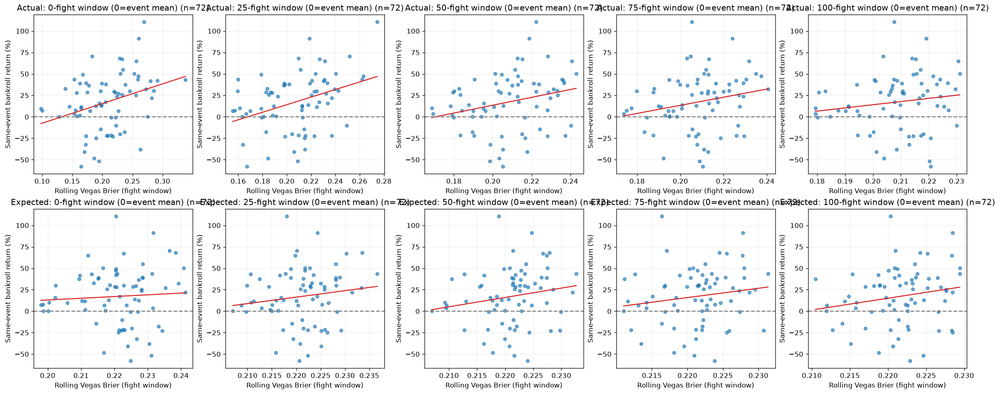

In [6]:
from scipy.stats import pearsonr, spearmanr

FIGHT_WINDOWS = [0, 25, 50, 75, 100]  # 0 = unsmoothed event mean
EVENT_BOOTSTRAPS = 2000
EVENT_BLOCK_LENGTH = 5
EVENT_CORRELATION_SEED = 42
source_root = settings.data_dir / 'backtest_results' / 'model_comparisons' / 'inference_market_models'
event_source = source_root / 'train_val_open_with_open_inference_no_decay_moneylines.csv'
reference_source = (settings.data_dir / 'model_comparisons' / 'lr_open_close' / 'report_predictions'
                    / 'train' / 'open' / 'inference' / 'val_with_open.csv')
fights = pd.read_csv(event_source)
reference = pd.read_csv(reference_source)
keys = ['date','fighter_red','fighter_blue']
verified = fights.merge(reference[keys+['proba_red','probability_model']],on=keys,
                        how='outer',validate='one_to_one',indicator=True)
if not verified['_merge'].eq('both').all() or not verified.probability_model.eq('inference').all():
    raise ValueError('Backtest does not match train-only opening inference validation export')
saved_probability = verified.choice_proba.where(verified.pred_winner.eq(1),1-verified.choice_proba)
np.testing.assert_allclose(saved_probability,verified.proba_red,rtol=1e-10,atol=1e-12)
fights['date'] = pd.to_datetime(fights.date).dt.normalize()
fights = fights.sort_values('date',kind='stable')
balance_columns = ['bankroll_postevent','event_payout_money_line','parlay_net']
if (fights.groupby('date')[balance_columns].nunique(dropna=False)>1).any().any():
    raise ValueError('Inconsistent repeated event balance fields')
event_brier_returns = fights.groupby('date',sort=True)[balance_columns].first()
event_brier_returns['net_profit'] = event_brier_returns.event_payout_money_line+event_brier_returns.parlay_net
event_brier_returns['starting_bankroll'] = event_brier_returns.bankroll_postevent-event_brier_returns.net_profit
np.testing.assert_allclose(event_brier_returns.starting_bankroll.iloc[1:],
                           event_brier_returns.bankroll_postevent.iloc[:-1],rtol=1e-7,atol=1e-6)
event_brier_returns['return_pct'] = 100*event_brier_returns.net_profit/event_brier_returns.starting_bankroll.where(event_brier_returns.starting_bankroll>0)
r = pd.to_numeric(fights.real_odds_red,errors='coerce')
b = pd.to_numeric(fights.real_odds_blue,errors='coerce')
p_vegas = (1/r)/(1/r+1/b)
valid = fights.winner.isin([0,1]) & np.isfinite(r) & np.isfinite(b) & r.gt(1) & b.gt(1)
scored = fights.loc[valid,['date','winner']].copy()
scored['actual_vegas_brier'] = (p_vegas.loc[valid]-scored.winner)**2
scored['expected_vegas_brier'] = p_vegas.loc[valid]*(1-p_vegas.loc[valid])
means = scored.groupby('date').agg(actual_vegas_brier=('actual_vegas_brier','mean'),
    expected_vegas_brier=('expected_vegas_brier','mean'),settled_fights=('winner','size'))
event_brier_returns = event_brier_returns.join(means)

def event_corr_ci(x,y,rng):
    n=len(x);block=min(EVENT_BLOCK_LENGTH,n)
    starts=rng.integers(0,n-block+1,size=(EVENT_BOOTSTRAPS,int(np.ceil(n/block))))
    ids=(starts[:,:,None]+np.arange(block)).reshape(EVENT_BOOTSTRAPS,-1)[:,:n]
    a=x[ids];b=y[ids];a-=a.mean(axis=1,keepdims=True);b-=b.mean(axis=1,keepdims=True)
    denominator=np.sqrt((a*a).sum(axis=1)*(b*b).sum(axis=1))
    cor=np.divide((a*b).sum(axis=1),denominator,out=np.full(EVENT_BOOTSTRAPS,np.nan),where=denominator>0)
    finite=cor[np.isfinite(cor)]
    return np.quantile(finite,[.025,.975]) if len(finite) else [np.nan,np.nan]

# Seed windows with earlier training events from the SAME train-only opening model.
# Correlation outcomes remain validation returns only.
training_reference = pd.read_csv(reference_source.with_name('train_with_open.csv'))
training_reference['date']=pd.to_datetime(training_reference.date).dt.normalize()
r0=training_reference.dec_open_red;b0=training_reference.dec_open_blue
p0=(1/r0)/(1/r0+1/b0)
ok=training_reference.winner.isin([0,1]) & np.isfinite(r0) & np.isfinite(b0) & r0.gt(1) & b0.gt(1)
warm=training_reference.loc[ok,['date','winner']].copy()
warm['actual_vegas_brier']=(p0.loc[ok]-warm.winner)**2
warm['expected_vegas_brier']=p0.loc[ok]*(1-p0.loc[ok])
warm=warm.sort_values('date',kind='stable')
if warm.date.max()>=event_brier_returns.index.min():raise ValueError('Warmup overlaps validation')
full_fight_scores=pd.concat([warm[['date','actual_vegas_brier','expected_vegas_brier']],
                             scored[['date','actual_vegas_brier','expected_vegas_brier']]],ignore_index=True)
full_fight_scores=full_fight_scores.sort_values('date',kind='stable').reset_index(drop=True)

def fight_window_at_event_end(measure,window,prior=False):
    if window==0:
        by_event=full_fight_scores.groupby('date',sort=True)[measure].mean()
    else:
        # Compute the window across fights FIRST; then take the final value at each event.
        rolling=full_fight_scores[measure].rolling(window,min_periods=window).mean()
        by_event=pd.DataFrame({'date':full_fight_scores.date,'value':rolling}).groupby('date',sort=True)['value'].last()
    if prior:by_event=by_event.shift(1)
    return by_event.reindex(event_brier_returns.index)
rng=np.random.default_rng(EVENT_CORRELATION_SEED)
records=[];event_window_pairs={}
for measure in ('actual_vegas_brier','expected_vegas_brier'):
    for window in FIGHT_WINDOWS:
        rolling=fight_window_at_event_end(measure,window)
        paired=pd.DataFrame({'brier':rolling,'return_pct':event_brier_returns.return_pct}).dropna()
        event_window_pairs[(measure,window)]=paired
        x=paired.brier.to_numpy();y=paired.return_pct.to_numpy()
        pearson=spearman=lo=hi=np.nan
        if len(paired)>=4 and np.std(x)>0 and np.std(y)>0:
            pearson=float(pearsonr(x,y).statistic);spearman=float(spearmanr(x,y).statistic)
            lo,hi=event_corr_ci(x,y,rng)
        records.append(dict(measure=measure,window_fights=window,pairs=len(paired),Pearson=pearson,
                            Spearman=spearman,CI_low=lo,CI_high=hi))
event_window_correlations=pd.DataFrame(records)
print('Windows count FIGHTS, sampled at event end. Window 0 = unsmoothed event mean. Same-event returns.')
print('Earlier training fights seed the windows; all correlation returns are validation-only.')
print(event_window_correlations.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
fig,axes=plt.subplots(2,len(FIGHT_WINDOWS),figsize=(20,8),constrained_layout=True)
for row,measure in enumerate(('actual_vegas_brier','expected_vegas_brier')):
    for col,window in enumerate(FIGHT_WINDOWS):
        ax=axes[row,col];sample=event_window_pairs[(measure,window)]
        ax.scatter(sample.brier,sample.return_pct,alpha=.65,s=22)
        if len(sample)>=4 and sample.brier.std()>0:
            slope,intercept=np.polyfit(sample.brier,sample.return_pct,1)
            grid=np.linspace(sample.brier.min(),sample.brier.max(),100)
            ax.plot(grid,intercept+slope*grid,color='tab:red')
        ax.axhline(0,color='gray',linestyle='--')
        ax.set(title=f'{"Actual" if row==0 else "Expected"}: {window}-fight window (0=event mean) (n={len(sample)})',
               xlabel='Rolling Vegas Brier (fight window)',ylabel='Same-event bankroll return (%)')
        ax.grid(alpha=.2)
plt.show()


## Prior-event returns comparison: fight windows

Use the same 25-, 50-, 75-, and 100-fight windows, but stop at the end of the
previous event and pair with the current event's return. Current-event outcomes
are excluded from both actual and expected Brier predictors. Window 0 is the
previous event's unsmoothed mean. All comparisons retain 72 validation return rows.


Windows count FIGHTS, ending at the PREVIOUS event. Window 0 = previous event mean. Current-event returns.
Earlier training fights seed the windows; all correlation returns are validation-only.
             measure  window_fights  pairs  Pearson  Spearman  CI_low  CI_high
  actual_vegas_brier              0     72   0.1912    0.1974  0.0033   0.4048
  actual_vegas_brier             25     72   0.0863    0.1060 -0.1153   0.2436
  actual_vegas_brier             50     72   0.1065    0.1551 -0.0589   0.2423
  actual_vegas_brier             75     72   0.1162    0.1835 -0.0263   0.2596
  actual_vegas_brier            100     72   0.0749    0.1593 -0.0722   0.2369
expected_vegas_brier              0     72   0.2096    0.2771 -0.0433   0.4762
expected_vegas_brier             25     72   0.1377    0.1972 -0.0447   0.2775
expected_vegas_brier             50     72   0.1413    0.1869 -0.0675   0.3232
expected_vegas_brier             75     72   0.1996    0.1769 -0.0462   0.3640
expected_vegas_b

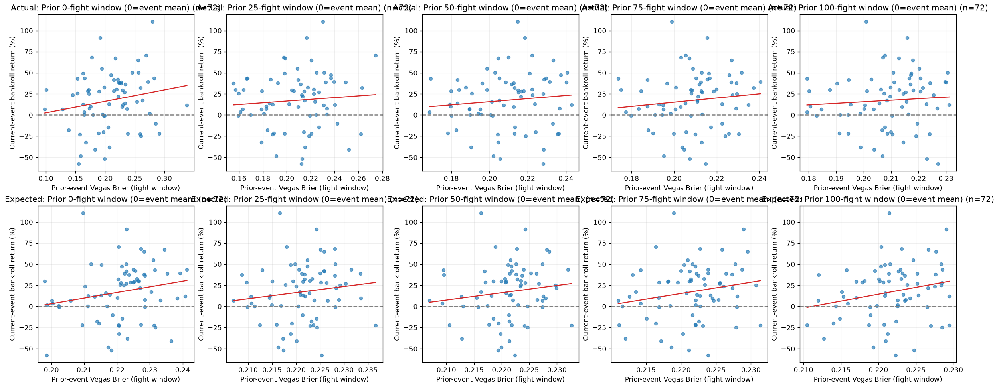

In [7]:
rng=np.random.default_rng(EVENT_CORRELATION_SEED)
records=[];prior_event_window_pairs={}
for measure in ('actual_vegas_brier','expected_vegas_brier'):
    for window in FIGHT_WINDOWS:
        rolling=fight_window_at_event_end(measure,window,prior=True)
        paired=pd.DataFrame({'brier':rolling,'return_pct':event_brier_returns.return_pct}).dropna()
        prior_event_window_pairs[(measure,window)]=paired
        x=paired.brier.to_numpy();y=paired.return_pct.to_numpy()
        pearson=spearman=lo=hi=np.nan
        if len(paired)>=4 and np.std(x)>0 and np.std(y)>0:
            pearson=float(pearsonr(x,y).statistic);spearman=float(spearmanr(x,y).statistic)
            lo,hi=event_corr_ci(x,y,rng)
        records.append(dict(measure=measure,window_fights=window,pairs=len(paired),Pearson=pearson,
                            Spearman=spearman,CI_low=lo,CI_high=hi))
prior_event_window_correlations=pd.DataFrame(records)
print('Windows count FIGHTS, ending at the PREVIOUS event. Window 0 = previous event mean. Current-event returns.')
print('Earlier training fights seed the windows; all correlation returns are validation-only.')
print(prior_event_window_correlations.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
fig,axes=plt.subplots(2,len(FIGHT_WINDOWS),figsize=(20,8),constrained_layout=True)
for row,measure in enumerate(('actual_vegas_brier','expected_vegas_brier')):
    for col,window in enumerate(FIGHT_WINDOWS):
        ax=axes[row,col];sample=prior_event_window_pairs[(measure,window)]
        ax.scatter(sample.brier,sample.return_pct,alpha=.65,s=22)
        if len(sample)>=4 and sample.brier.std()>0:
            slope,intercept=np.polyfit(sample.brier,sample.return_pct,1)
            grid=np.linspace(sample.brier.min(),sample.brier.max(),100)
            ax.plot(grid,intercept+slope*grid,color='tab:red')
        ax.axhline(0,color='gray',linestyle='--')
        ax.set(title=f'{"Actual" if row==0 else "Expected"}: Prior {window}-fight window (0=event mean) (n={len(sample)})',
               xlabel='Prior-event Vegas Brier (fight window)',ylabel='Current-event bankroll return (%)')
        ax.grid(alpha=.2)
plt.show()


## Excess Vegas Brier and model advantage versus event percent returns

Same train-only opening inference model, validation strategy returns, and
training-fight warmup as the preceding correlation analysis. Uses all eligible
settled fights, with equal fight weights within rolling windows.

- **Excess Vegas Brier** = actual Vegas Brier − expected Vegas Brier, p(1−p).
- **Model Brier advantage** = actual Vegas Brier − actual model Brier; positive
  values favor the model.

Compute differences per fight, then average the latest 25, 50, 75, or 100 fights
and sample at event end. “Event only” means the mean for that event, without a
rolling window. Separate figures show same-event and prior-event predictors.
Prior-event windows end at the previous event; neither includes current outcomes.
The y-axis is current event bankroll percent return, including singles and parlays.
All comparisons use the same 72 validation return observations.

Pearson/Spearman correlations and approximate 95% Pearson block-bootstrap
intervals are descriptive. Same-event scores share outcomes with returns; multiple
windows, historical strategy selection, and overlapping scores limit inference.
Run the preceding Vegas Brier correlation setup cell first.


timing               measure     window  pairs  Pearson  Spearman  CI_low  CI_high
  same    excess_vegas_brier Event only     72   0.3238    0.3258  0.1230   0.4597
  same    excess_vegas_brier  25 fights     72   0.3693    0.3485  0.1021   0.5808
  same    excess_vegas_brier  50 fights     72   0.2392    0.2895  0.0672   0.4266
  same    excess_vegas_brier  75 fights     72   0.1993    0.2380  0.0276   0.3262
  same    excess_vegas_brier 100 fights     72   0.1013    0.1723 -0.0749   0.3064
  same model_brier_advantage Event only     72   0.7286    0.6621  0.5246   0.8249
  same model_brier_advantage  25 fights     72   0.3223    0.2261  0.0331   0.4810
  same model_brier_advantage  50 fights     72   0.2236    0.2022  0.0293   0.3449
  same model_brier_advantage  75 fights     72   0.2440    0.2263  0.0500   0.3869
  same model_brier_advantage 100 fights     72   0.2618    0.2280  0.0364   0.4554
 prior    excess_vegas_brier Event only     72   0.1519    0.1683 -0.0688   0.3876
 pri

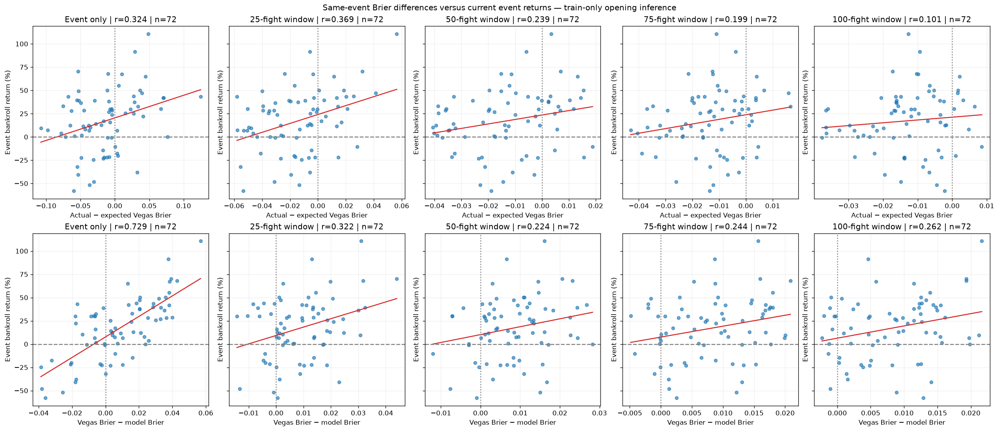

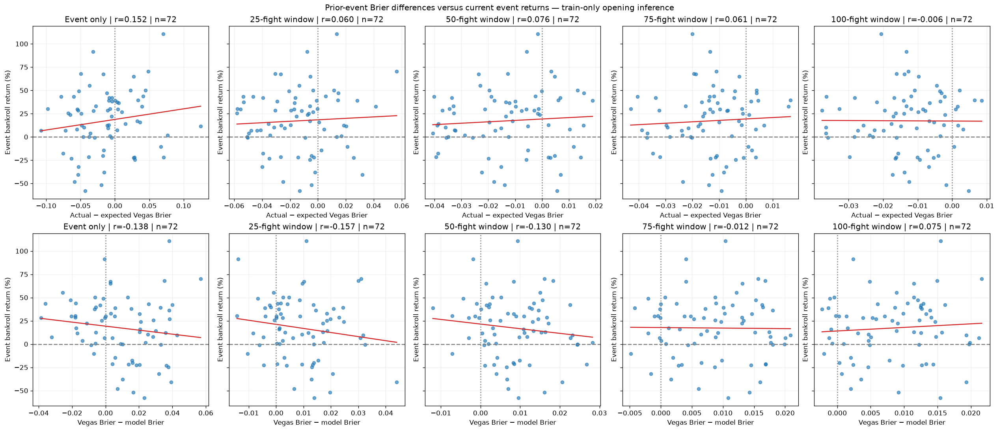

In [8]:
# Augment the exact scored rows used in the preceding analysis.
diagnostic_validation = scored.copy()
validation_model_red = fights.choice_proba.where(fights.pred_winner.eq(1),1-fights.choice_proba)
diagnostic_validation['model_brier'] = (validation_model_red.loc[diagnostic_validation.index]-diagnostic_validation.winner)**2
diagnostic_warmup = warm.copy()
diagnostic_warmup['model_brier'] = (training_reference.proba_red.loc[diagnostic_warmup.index]-diagnostic_warmup.winner)**2
diagnostic_fights = pd.concat([diagnostic_warmup,diagnostic_validation],ignore_index=True)
diagnostic_fights = diagnostic_fights.sort_values('date',kind='stable').reset_index(drop=True)
diagnostic_fights['excess_vegas_brier'] = diagnostic_fights.actual_vegas_brier-diagnostic_fights.expected_vegas_brier
diagnostic_fights['model_brier_advantage'] = diagnostic_fights.actual_vegas_brier-diagnostic_fights.model_brier
if not np.isfinite(diagnostic_fights[['excess_vegas_brier','model_brier_advantage']]).all().all():
    raise ValueError('Nonfinite Brier differences')

DIAGNOSTIC_LABELS = {'excess_vegas_brier':'Actual − expected Vegas Brier',
                     'model_brier_advantage':'Vegas Brier − model Brier'}
diagnostic_pairs={};diagnostic_records=[]
rng=np.random.default_rng(EVENT_CORRELATION_SEED)
for timing in ('same','prior'):
    for measure in DIAGNOSTIC_LABELS:
        for window in FIGHT_WINDOWS:
            if window==0:
                by_event=diagnostic_fights.groupby('date',sort=True)[measure].mean()
            else:
                rolling=diagnostic_fights[measure].rolling(window,min_periods=window).mean()
                by_event=pd.DataFrame({'date':diagnostic_fights.date,'value':rolling}).groupby('date',sort=True)['value'].last()
            if timing=='prior':by_event=by_event.shift(1)
            sample=pd.DataFrame({'brier_difference':by_event.reindex(event_brier_returns.index),
                                  'return_pct':event_brier_returns.return_pct}).dropna()
            diagnostic_pairs[(timing,measure,window)]=sample
            x=sample.brier_difference.to_numpy();y=sample.return_pct.to_numpy()
            r=rho=lo=hi=np.nan
            if len(sample)>=4 and np.std(x)>0 and np.std(y)>0:
                r=float(pearsonr(x,y).statistic);rho=float(spearmanr(x,y).statistic)
                lo,hi=event_corr_ci(x,y,rng)
            diagnostic_records.append(dict(timing=timing,measure=measure,
                window='Event only' if window==0 else f'{window} fights',pairs=len(sample),
                Pearson=r,Spearman=rho,CI_low=lo,CI_high=hi))
diagnostic_return_correlations=pd.DataFrame(diagnostic_records)
print(diagnostic_return_correlations.to_string(index=False,float_format=lambda x:f'{x:.4f}'))

for timing in ('same','prior'):
    fig,axes=plt.subplots(2,len(FIGHT_WINDOWS),figsize=(21,9),sharey=True,constrained_layout=True)
    for row,(measure,label) in enumerate(DIAGNOSTIC_LABELS.items()):
        for col,window in enumerate(FIGHT_WINDOWS):
            ax=axes[row,col];sample=diagnostic_pairs[(timing,measure,window)]
            ax.scatter(sample.brier_difference,sample.return_pct,alpha=.65,s=23)
            if len(sample)>=4 and sample.brier_difference.std()>0:
                slope,intercept=np.polyfit(sample.brier_difference,sample.return_pct,1)
                grid=np.linspace(sample.brier_difference.min(),sample.brier_difference.max(),100)
                ax.plot(grid,intercept+slope*grid,color='tab:red')
            record=diagnostic_return_correlations.loc[
                diagnostic_return_correlations.timing.eq(timing)&
                diagnostic_return_correlations.measure.eq(measure)&
                diagnostic_return_correlations.window.eq('Event only' if window==0 else f'{window} fights')].iloc[0]
            window_label='Event only' if window==0 else f'{window}-fight window'
            ax.set(title=f'{window_label} | r={record.Pearson:.3f} | n={len(sample)}',
                   xlabel=label,ylabel='Event bankroll return (%)')
            ax.axhline(0,color='gray',linestyle='--');ax.axvline(0,color='gray',linestyle=':')
            ax.grid(alpha=.2)
    fig.suptitle(('Same-event' if timing=='same' else 'Prior-event')+
                 ' Brier differences versus current event returns — train-only opening inference')
    plt.show()


## Rolling FFT: train-only opening model, followed through validation

The base series remains **Vegas Brier minus model Brier averaged over 100 fights**, sampled at event end. Each fit uses only the last **128 event observations** and removes that window's own linear trend. The Fourier series now retains **all Fourier frequencies**, including periods from 2 to 128 events. The earlier three-peak, 8–64-event restriction discarded substantial variation and has been removed from this analysis.

A full Fourier series reconstructs the historical samples to numerical precision. This is interpolation, not evidence of predictable cycles or denoising. The separate last-training-window and last-validation-window plots display entire fitted curves against the exact observations used for those fits. The rolling overview connects endpoints from different historical fits.

Signed velocity is the analytical derivative of the fitted Fourier series at the final observation, summed across its components, in Brier advantage per event. **An ordinary Fourier series assumes periodic wraparound: the last sample connects back to the first. Its endpoint derivative can therefore be affected by that artificial connection, and retaining high frequencies amplifies noise in the derivative.** A perfect reconstruction does not validate this velocity as a stable wave-direction measurement. The historical regression below describes this specific full-spectrum derivative; it is not a forecasting evaluation. `harmonics=None` retains the full spectrum; a smaller harmonic count would explicitly smooth the fit.

Training and validation diagnostic plots show **post-event** features. Return analyses shift features to the **next event**, so no outcome from the target event enters its predictors. Detrending is trailing-window only: this will differ from a plot detrended using the full series. Frequency units are events, not calendar days; the input smoothing window is still 100 fights.

The training probability predictions are in-sample for the training-fitted logistic model, so training spectral plots are descriptive. Saved strategy returns are for validation. Fit **one ordinary least-squares multivariable regression on all 72 aligned historical validation events**, with an intercept and two predictors: the previous window's detrended rolling Brier advantage endpoint and the previous window's fitted Fourier-series signed velocity. Both windows end at the previous completed event. The Fourier series is fitted to historical observations only; neither predictor is extrapolated. The regression uses observed returns, with no forecast split or expanding forecast evaluation.

The regression equation is `return[t] = intercept + beta_A * detrended_advantage[t-1] + beta_V * Fourier_velocity[t-1] + error[t]`. The reported R-squared and fitted values describe this historical sample. Partial-association plots show each predictor's relationship with returns after controlling for the other predictor. Coefficients per predictor standard deviation help compare the two scales. Inherited betting parameters may have been tuned on validation, so this is descriptive strategy analysis.

Spectral power shows which oscillation lengths are prominent in each trailing window; it does not establish statistical significance. The overlapping 100-fight averages induce dependence. Scatter correlations are descriptive, with no independent-observation significance claim.

Within-event fight ordering matches the earlier excess-Brier correlation section: training export order for warmup and saved strategy-row order for validation, with stable date sorting. This matters when the 100-fight window cuts through an event. An assertion compares all 72 prior-event raw advantage values and returns against that section when it has run.


Full-spectrum reconstruction max window RMSE: 2.457383748087561e-18
Full Fourier fits interpolate the observations. Endpoint velocity is sensitive to periodic wraparound and high-frequency noise.
Train-only opening inference. 72 validation return events; FFT initialized with training history.
100-fight rolling advantage; Full Fourier spectrum: periods 2-128 events; no three-peak restriction.
        feature  n  pearson  spearman
       velocity 72 0.039263  0.016014
detrended_value 72 0.082106  0.081967
Historical OLS: return[t] = intercept + beta_A * detrended_advantage[t-1] + beta_V * Fourier_velocity[t-1]
N=72; in-sample R-squared=0.0179; adjusted R-squared=-0.0106
                 coefficient  effect_per_predictor_SD
const              18.677772                      NaN
detrended_value   870.638725                 5.128171
velocity          640.993520                 4.233919
Effects are percentage points of event return. This is a descriptive historical fit.


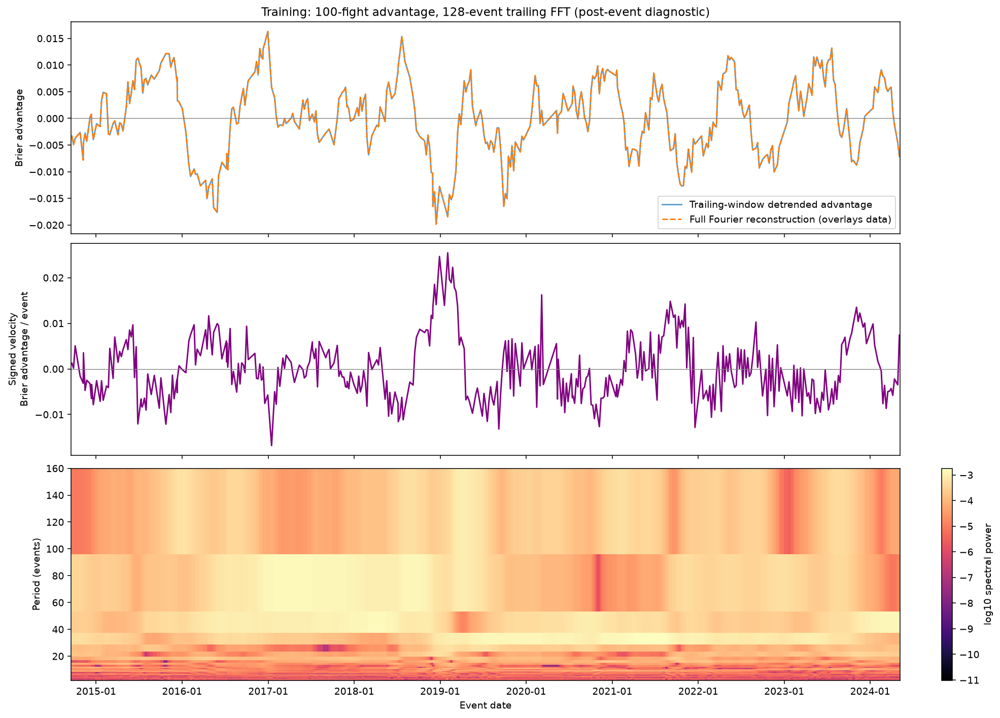

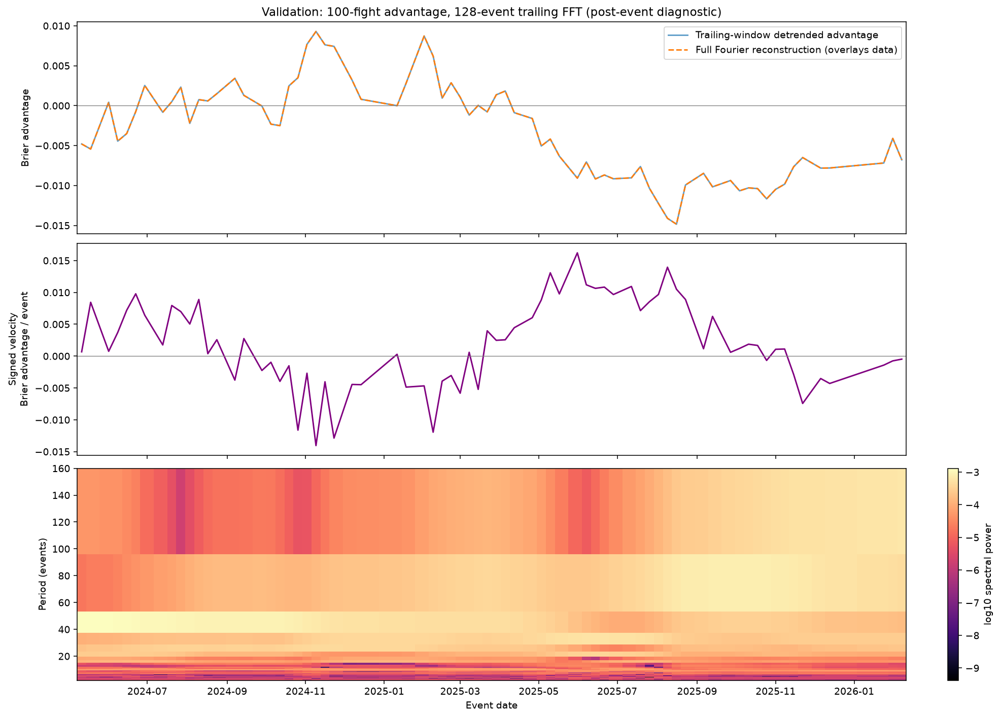

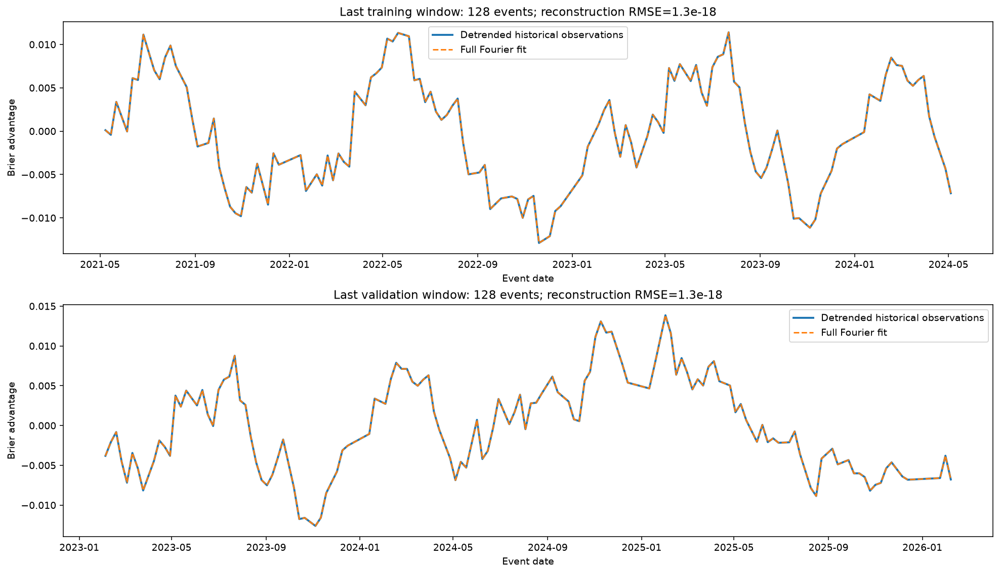

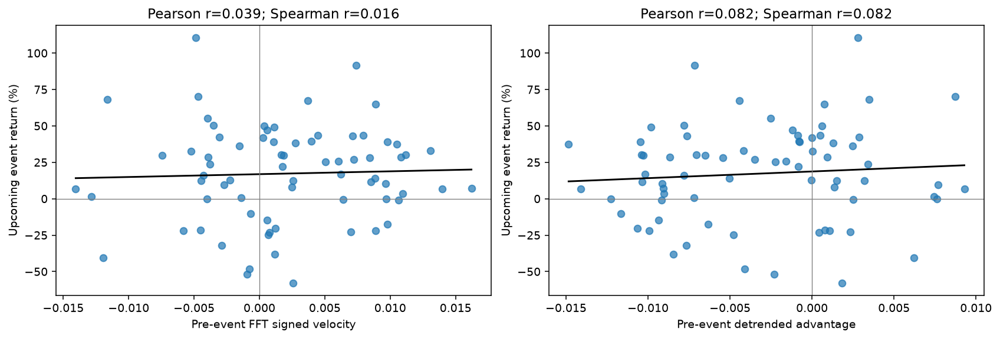

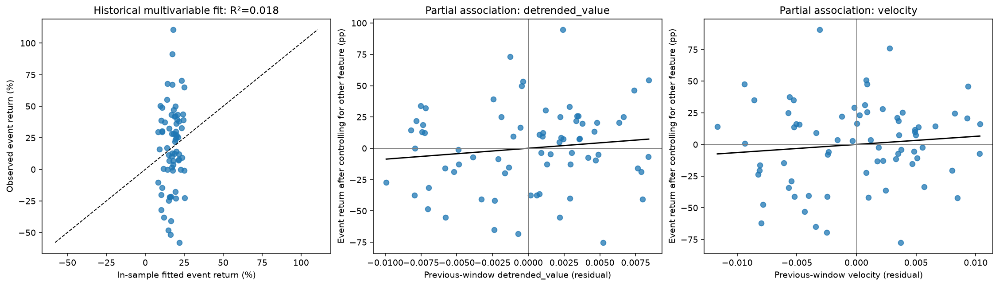

In [1]:
# Support running from either the notebook directory or repository root.
fft_module_dir = ROOT / 'Notebooks' / 'Bets'
if str(fft_module_dir) not in sys.path:
    sys.path.insert(0, str(fft_module_dir))
from rolling_fft import rolling_fourier_features, fit_fourier_window
from scipy.stats import pearsonr, spearmanr

fft_base = settings.data_dir / 'model_comparisons/lr_open_close/report_predictions/train/open/inference'
fft_train = pd.read_csv(fft_base / 'train_with_open.csv', parse_dates=['date'])
fft_val = pd.read_csv(fft_base / 'val_with_open.csv', parse_dates=['date'])
fft_cut = fft_train.date.max()
assert fft_cut < fft_val.date.min()
fft_fights = pd.concat([fft_train, fft_val], ignore_index=True)
# Preserve the exact within-event ordering used by the earlier correlation section.
# A fixed fight-count window can cut through an event, so ordering affects membership.
fft_saved_order = pd.read_csv(settings.data_dir / 'backtest_results/model_comparisons/inference_market_models/train_val_open_with_open_inference_no_decay_moneylines.csv', parse_dates=['date'])
fft_order_keys = ['date', 'fighter_red', 'fighter_blue']
fft_source_order = pd.concat([fft_train[fft_order_keys], fft_saved_order[fft_order_keys]], ignore_index=True)
fft_fights = fft_source_order.merge(fft_fights, on=fft_order_keys, how='left', validate='one_to_one', sort=False)
fft_fights = fft_fights.sort_values('date', kind='stable')
p = pd.to_numeric(fft_fights.proba_red, errors='coerce')
r = pd.to_numeric(fft_fights.dec_open_red, errors='coerce')
b = pd.to_numeric(fft_fights.dec_open_blue, errors='coerce')
valid = fft_fights.winner.isin([0,1]) & p.between(0,1) & np.isfinite(r) & np.isfinite(b) & r.gt(1) & b.gt(1)
q = (1/r)/(1/r+1/b)
fft_fights = fft_fights.loc[valid].copy()
fft_fights['advantage'] = ((q-fft_fights.winner)**2-(p-fft_fights.winner)**2).loc[valid]
fft_fights['rolling_advantage'] = fft_fights.advantage.rolling(100, min_periods=100).mean()
fft_event_series = fft_fights.groupby('date').rolling_advantage.last().dropna()
fft_features, fft_spectrum = rolling_fourier_features(fft_event_series, window=128, harmonics=None)

for label, mask in [('Training', fft_features.index <= fft_cut), ('Validation', fft_features.index > fft_cut)]:
    f = fft_features.loc[mask]
    s = fft_spectrum.loc[mask].sort_index(axis=1)
    fig, axes = plt.subplots(3,1,figsize=(14,10),sharex=True,constrained_layout=True)
    axes[0].plot(f.index, f.detrended_value, label='Trailing-window detrended advantage', alpha=.7)
    axes[0].plot(f.index, f.oscillation, label='Full Fourier reconstruction (overlays data)', linestyle='--')
    axes[0].axhline(0,color='gray',lw=.7); axes[0].legend()
    axes[0].set_ylabel('Brier advantage')
    axes[0].set_title(f'{label}: 100-fight advantage, 128-event trailing FFT (post-event diagnostic)')
    axes[1].plot(f.index, f.velocity, color='purple')
    axes[1].axhline(0,color='gray',lw=.7)
    axes[1].set_ylabel('Signed velocity\nBrier advantage / event')
    mesh = axes[2].pcolormesh(s.index, s.columns, np.log10(np.maximum(s.to_numpy().T,1e-12)), shading='auto', cmap='magma')
    fig.colorbar(mesh,ax=axes[2],label='log10 spectral power')
    axes[2].set_ylabel('Period (events)'); axes[2].set_xlabel('Event date')
    axes[2].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.show()

# Inspect complete fits within individual windows, not joined rolling endpoints.
fig, axes = plt.subplots(2,1,figsize=(14,8),constrained_layout=True)
for ax, end, label in zip(axes, [fft_event_series.loc[:fft_cut].index[-1], fft_event_series.index[-1]], ['Last training window','Last validation window']):
    history = fft_event_series.loc[:end].iloc[-128:]
    residual, fitted, velocity, power = fit_fourier_window(history.to_numpy())
    ax.plot(history.index,residual,label='Detrended historical observations',lw=2)
    ax.plot(history.index,fitted,'--',label='Full Fourier fit',lw=1.5)
    ax.set(title=f'{label}: 128 events; reconstruction RMSE={np.sqrt(np.mean((residual-fitted)**2)):.2g}',ylabel='Brier advantage',xlabel='Event date')
    ax.legend()
plt.show()
print('Full-spectrum reconstruction max window RMSE:', fft_features.fit_rmse.max())
print('Full Fourier fits interpolate the observations. Endpoint velocity is sensitive to periodic wraparound and high-frequency noise.')

fft_saved = pd.read_csv(settings.data_dir / 'backtest_results/model_comparisons/inference_market_models/train_val_open_with_open_inference_no_decay_moneylines.csv', parse_dates=['date'])
keys = ['date','fighter_red','fighter_blue']
check = fft_saved.merge(fft_val[keys+['proba_red']],on=keys,how='outer',validate='one_to_one',indicator=True)
assert check['_merge'].eq('both').all()
np.testing.assert_allclose(check.choice_proba.where(check.pred_winner.eq(1),1-check.choice_proba),check.proba_red,atol=1e-10)
cols = ['bankroll_postevent','event_payout_money_line','parlay_net']
assert fft_saved.groupby('date')[cols].nunique().le(1).all().all()
fft_returns = fft_saved.groupby('date')[cols].first().sort_index()
profit = fft_returns.event_payout_money_line + fft_returns.parlay_net
start = fft_returns.bankroll_postevent-profit
assert start.gt(0).all()
np.testing.assert_allclose(start.iloc[1:],fft_returns.bankroll_postevent.iloc[:-1],rtol=1e-8,atol=1e-8)
fft_returns['return_pct'] = 100*profit/start
# A feature dated t uses the outcomes of t; shift it to the NEXT event.
fft_available = fft_features.reindex(fft_event_series.index).copy()
fft_available['feature_date'] = fft_available.index
fft_prior = fft_available.shift(1)
fft_pairs = fft_returns[['return_pct']].join(fft_prior[['velocity','detrended_value','feature_date']]).dropna()
assert (fft_pairs.feature_date < fft_pairs.index).all()
# When the earlier section has run, require identical 100-fight prior-event observations.
if 'diagnostic_pairs' in globals():
    fft_reference_pairs = diagnostic_pairs[('prior', 'model_brier_advantage', 100)]
    pd.testing.assert_index_equal(fft_pairs.index, fft_reference_pairs.index)
    np.testing.assert_allclose(fft_prior.raw_value.reindex(fft_pairs.index), fft_reference_pairs.brier_difference, rtol=1e-10, atol=1e-12)
    np.testing.assert_allclose(fft_pairs.return_pct, fft_reference_pairs.return_pct, rtol=1e-10, atol=1e-12)

print(f'Train-only opening inference. {len(fft_pairs)} validation return events; FFT initialized with training history.')
print('100-fight rolling advantage; Full Fourier spectrum: periods 2-128 events; no three-peak restriction.')
fig, axes = plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
fft_correlations=[]
for ax, col, title in zip(axes,['velocity','detrended_value'],['Pre-event FFT signed velocity','Pre-event detrended advantage']):
    x,y = fft_pairs[col],fft_pairs.return_pct
    pr,sr = pearsonr(x,y).statistic,spearmanr(x,y).statistic
    fft_correlations.append(dict(feature=col,n=len(x),pearson=pr,spearman=sr))
    ax.scatter(x,y,alpha=.7)
    grid=np.linspace(x.min(),x.max(),100)
    ax.plot(grid,np.polyval(np.polyfit(x,y,1),grid),color='black',label='Descriptive linear fit')
    ax.axhline(0,color='gray',lw=.7); ax.axvline(0,color='gray',lw=.7)
    ax.set(xlabel=title,ylabel='Upcoming event return (%)',title=f'Pearson r={pr:.3f}; Spearman r={sr:.3f}')
plt.show()
print(pd.DataFrame(fft_correlations).to_string(index=False))

# One historical multivariable OLS fit on all aligned validation observations.
import statsmodels.api as sm
fft_columns = ['detrended_value', 'velocity']
fft_X = sm.add_constant(fft_pairs[fft_columns])
fft_regression = sm.OLS(fft_pairs.return_pct, fft_X).fit()
fft_pairs['fitted_return_pct'] = fft_regression.fittedvalues
fft_coefficient_table = pd.DataFrame({
    'coefficient': fft_regression.params,
    'effect_per_predictor_SD': fft_regression.params.reindex(fft_columns) * fft_pairs[fft_columns].std(ddof=0),
})
print('Historical OLS: return[t] = intercept + beta_A * detrended_advantage[t-1] + beta_V * Fourier_velocity[t-1]')
print(f'N={int(fft_regression.nobs)}; in-sample R-squared={fft_regression.rsquared:.4f}; adjusted R-squared={fft_regression.rsquared_adj:.4f}')
print(fft_coefficient_table.to_string())
print('Effects are percentage points of event return. This is a descriptive historical fit.')
fig, axes = plt.subplots(1,3,figsize=(16,4.5),constrained_layout=True)
axes[0].scatter(fft_pairs.fitted_return_pct,fft_pairs.return_pct,alpha=.75)
lo=min(fft_pairs.fitted_return_pct.min(),fft_pairs.return_pct.min())
hi=max(fft_pairs.fitted_return_pct.max(),fft_pairs.return_pct.max())
axes[0].plot([lo,hi],[lo,hi],'k--',lw=1)
axes[0].set(xlabel='In-sample fitted event return (%)',ylabel='Observed event return (%)',title=f'Historical multivariable fit: R²={fft_regression.rsquared:.3f}')
# Added-variable plots isolate each association after removing the other predictor.
for ax, feature, other in zip(axes[1:],fft_columns,fft_columns[::-1]):
    controls=sm.add_constant(fft_pairs[[other]])
    rx=sm.OLS(fft_pairs[feature],controls).fit().resid
    ry=sm.OLS(fft_pairs.return_pct,controls).fit().resid
    ax.scatter(rx,ry,alpha=.75)
    grid=np.linspace(rx.min(),rx.max(),100)
    ax.plot(grid,fft_regression.params[feature]*grid,color='black')
    ax.axhline(0,color='gray',lw=.6); ax.axvline(0,color='gray',lw=.6)
    ax.set(xlabel=f'Previous-window {feature} (residual)',ylabel='Event return after controlling for other feature (pp)',title=f'Partial association: {feature}')
plt.show()


### Detrended advantage and percent returns on the same timeline

Both are line plots across the 72 validation events. Blue is the previous completed window's detrended 100-fight rolling Brier advantage, aligned to the following event date; orange is that event's observed bankroll percent return. This uses the same observations as the regression above. Separate axes preserve each series' units; their zero levels are aligned. Raw returns remain visible in orange. Green shows the arithmetic trailing 5-event mean of event return percentages, including the plotted event (not compounded returns). The first four events have no mean because a complete window is required. Change `RETURN_MEAN_EVENTS` in the cell to adjust the window. This return average is descriptive and includes the current event outcome.


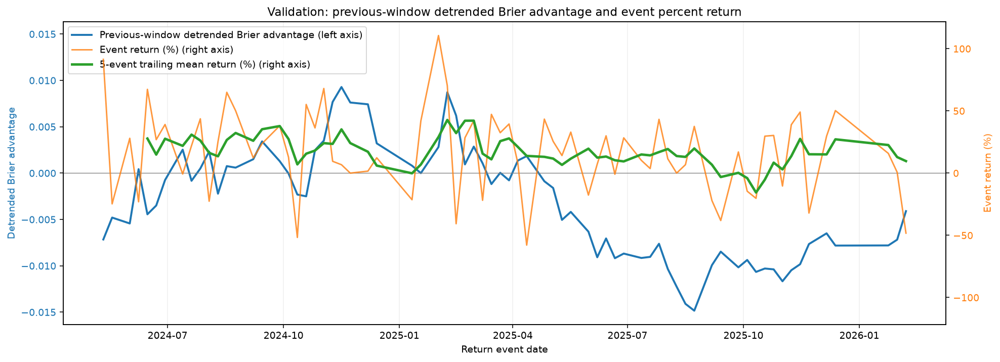

In [1]:
# Same alignment as the historical regression: prior-window advantage vs event return.
RETURN_MEAN_EVENTS = 5
rolling_return_pct = fft_pairs.return_pct.rolling(RETURN_MEAN_EVENTS, min_periods=RETURN_MEAN_EVENTS).mean()
fig, ax_advantage = plt.subplots(figsize=(14, 5), constrained_layout=True)
ax_returns = ax_advantage.twinx()
advantage_line, = ax_advantage.plot(
    fft_pairs.index, fft_pairs.detrended_value, color='tab:blue', linewidth=2,
    label='Previous-window detrended Brier advantage (left axis)')
return_line, = ax_returns.plot(
    fft_pairs.index, fft_pairs.return_pct, color='tab:orange', linewidth=1.5, alpha=.8,
    label='Event return (%) (right axis)')
mean_line, = ax_returns.plot(
    fft_pairs.index, rolling_return_pct, color='tab:green', linewidth=2.5,
    label=f'{RETURN_MEAN_EVENTS}-event trailing mean return (%) (right axis)')
ax_advantage.set_xlabel('Return event date')
ax_advantage.set_ylabel('Detrended Brier advantage', color='tab:blue')
ax_returns.set_ylabel('Event return (%)', color='tab:orange')
ax_advantage.tick_params(axis='y', labelcolor='tab:blue')
ax_returns.tick_params(axis='y', labelcolor='tab:orange')
# Align both zero levels for a readable comparison, retaining separate units.
for ax, values in [(ax_advantage, fft_pairs.detrended_value), (ax_returns, fft_pairs.return_pct)]:
    limit = max(float(values.abs().max()) * 1.1, 1e-9)
    ax.set_ylim(-limit, limit)
ax_advantage.axhline(0, color='gray', linewidth=.7)
ax_advantage.grid(axis='x', alpha=.2)
ax_advantage.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax_advantage.set_title('Validation: previous-window detrended Brier advantage and event percent return')
ax_advantage.legend(handles=[advantage_line, return_line, mean_line], loc='upper left')
plt.show()


### Detrended advantage and cumulative percent return

Blue retains the previous-window detrended Brier advantage aligned to the return event. Orange is cumulative compounded return since the start of validation: `100 * (product(1 + event_return_pct / 100) - 1)`. Green is the trailing 5-event arithmetic mean of that cumulative return series, including the current event. Change `CUMULATIVE_MEAN_EVENTS` to adjust the window. The first four mean values are unavailable. The two y-axes have independent scales.


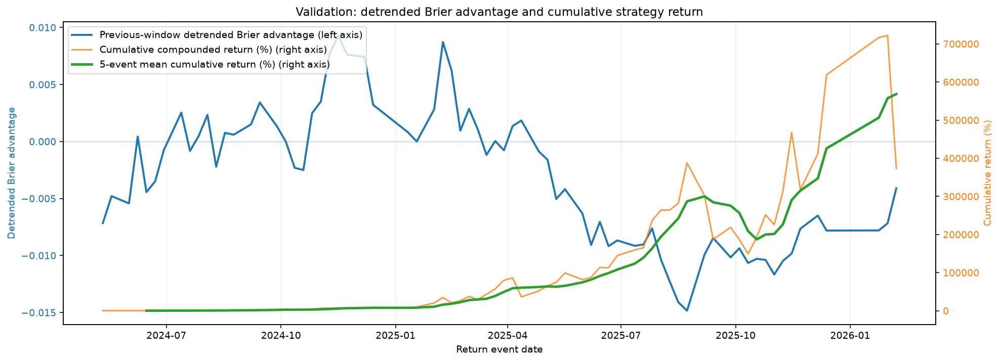

In [1]:
# Compound event returns from the start of validation, then smooth the cumulative series.
CUMULATIVE_MEAN_EVENTS = 5
cumulative_return_pct = 100 * ((1 + fft_returns.return_pct / 100).cumprod() - 1)
cumulative_mean_pct = cumulative_return_pct.rolling(
    CUMULATIVE_MEAN_EVENTS, min_periods=CUMULATIVE_MEAN_EVENTS).mean()
# Confirm compounded returns match the recorded bankroll path.
initial_bankroll = (fft_returns.bankroll_postevent - fft_returns.event_payout_money_line - fft_returns.parlay_net).iloc[0]
np.testing.assert_allclose(cumulative_return_pct,
    100 * (fft_returns.bankroll_postevent / initial_bankroll - 1), rtol=1e-8, atol=1e-8)
fig, ax_advantage = plt.subplots(figsize=(14, 5), constrained_layout=True)
ax_cumulative = ax_advantage.twinx()
advantage_line, = ax_advantage.plot(
    fft_pairs.index, fft_pairs.detrended_value, color='tab:blue', linewidth=2,
    label='Previous-window detrended Brier advantage (left axis)')
cumulative_line, = ax_cumulative.plot(
    cumulative_return_pct.index, cumulative_return_pct, color='tab:orange', linewidth=1.5, alpha=.8,
    label='Cumulative compounded return (%) (right axis)')
mean_line, = ax_cumulative.plot(
    cumulative_mean_pct.index, cumulative_mean_pct, color='tab:green', linewidth=2.5,
    label=f'{CUMULATIVE_MEAN_EVENTS}-event mean cumulative return (%) (right axis)')
ax_advantage.set_xlabel('Return event date')
ax_advantage.set_ylabel('Detrended Brier advantage', color='tab:blue')
ax_cumulative.set_ylabel('Cumulative return (%)', color='tab:orange')
ax_advantage.tick_params(axis='y', labelcolor='tab:blue')
ax_cumulative.tick_params(axis='y', labelcolor='tab:orange')
ax_advantage.axhline(0, color='tab:blue', linewidth=.7, alpha=.4)
ax_advantage.grid(axis='x', alpha=.2)
ax_advantage.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax_advantage.set_title('Validation: detrended Brier advantage and cumulative strategy return')
ax_advantage.legend(handles=[advantage_line, cumulative_line, mean_line], loc='upper left')
plt.show()


### Detrended versus non-detrended advantage: correlation with event percent returns

Both panels use the same validation events and the previous completed event window. Non-detrended advantage is the 100-fight rolling average of Vegas Brier minus model Brier. Detrended advantage is its endpoint residual after removing the linear trend from the preceding 128 event observations. The y-axis is observed individual-event return percentage, not cumulative or smoothed return. Pearson measures linear association; Spearman measures rank association. These are descriptive historical correlations; overlapping windows induce dependence.


                            advantage  events  Pearson_r  Spearman_rho
    Detrended rolling Brier advantage      72   0.082106      0.081967
Non-detrended rolling Brier advantage      72   0.075347      0.069747


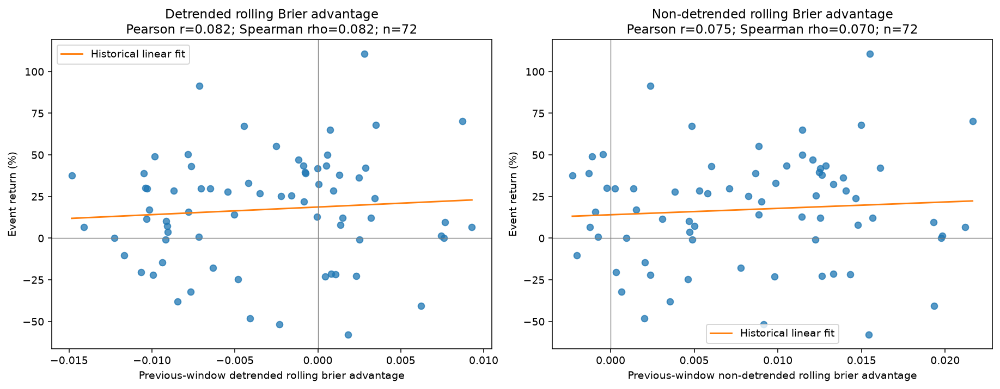

In [1]:
# Compare identical events and identical historical-window alignment.
from scipy.stats import pearsonr, spearmanr
advantage_return_pairs = fft_returns[['return_pct']].join(
    fft_prior[['raw_value', 'detrended_value', 'feature_date']]).dropna()
assert (advantage_return_pairs.feature_date < advantage_return_pairs.index).all()
np.testing.assert_allclose(advantage_return_pairs.raw_value,
    fft_event_series.shift(1).reindex(advantage_return_pairs.index))
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
advantage_return_stats = []
for ax, col, label in zip(axes, ['detrended_value', 'raw_value'],
                         ['Detrended rolling Brier advantage', 'Non-detrended rolling Brier advantage']):
    x, y = advantage_return_pairs[col], advantage_return_pairs.return_pct
    pearson = pearsonr(x, y).statistic
    spearman = spearmanr(x, y).statistic
    advantage_return_stats.append({'advantage': label, 'events': len(x),
                                   'Pearson_r': pearson, 'Spearman_rho': spearman})
    ax.scatter(x, y, alpha=.75, color='tab:blue')
    grid = np.linspace(x.min(), x.max(), 100)
    ax.plot(grid, np.polyval(np.polyfit(x, y, 1), grid), color='tab:orange', label='Historical linear fit')
    ax.axhline(0, color='gray', linewidth=.7)
    ax.axvline(0, color='gray', linewidth=.7)
    ax.set(xlabel=f'Previous-window {label.lower()}', ylabel='Event return (%)',
           title=f'{label}\nPearson r={pearson:.3f}; Spearman rho={spearman:.3f}; n={len(x)}')
    ax.legend()
plt.show()
advantage_return_correlations = pd.DataFrame(advantage_return_stats)
print(advantage_return_correlations.to_string(index=False))


### Training: event-only Brier advantage

Uses the opening inference model fitted on training and its training predictions. Each point is the equal-fight average of `(Vegas probability - outcome)^2 - (model probability - outcome)^2` within that event, using no-vig opening Vegas probabilities. No rolling window, detrending, or event shift. Positive values favor the model. These are in-sample training scores.


537 training events; 3994 eligible settled fights; 0 excluded rows.
Each point averages only the fights in that event. Positive values favor the model.


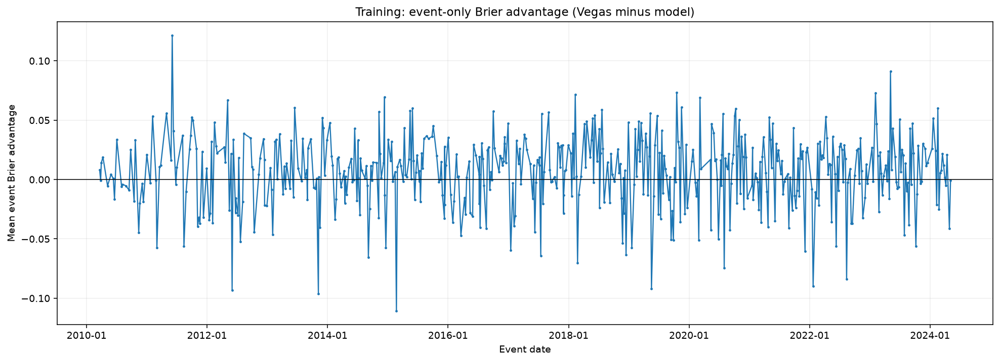

In [1]:
# Event-only training scores from the opening inference model fitted on training.
training_event_source = (settings.data_dir / 'model_comparisons/lr_open_close/report_predictions'
                         / 'train/open/inference/train_with_open.csv')
training_event_fights = pd.read_csv(training_event_source, parse_dates=['date'])
training_event_fights['date'] = training_event_fights.date.dt.normalize()
training_event_model = pd.to_numeric(training_event_fights.proba_red, errors='coerce')
training_event_red = pd.to_numeric(training_event_fights.dec_open_red, errors='coerce')
training_event_blue = pd.to_numeric(training_event_fights.dec_open_blue, errors='coerce')
training_event_valid = (training_event_fights.winner.isin([0, 1])
    & training_event_model.between(0, 1)
    & np.isfinite(training_event_red) & np.isfinite(training_event_blue)
    & training_event_red.gt(1) & training_event_blue.gt(1))
training_event_vegas = (1 / training_event_red) / (1 / training_event_red + 1 / training_event_blue)
training_event_scores = training_event_fights.loc[training_event_valid, ['date', 'winner']].copy()
training_event_scores['vegas_brier'] = (training_event_vegas.loc[training_event_valid] - training_event_scores.winner) ** 2
training_event_scores['model_brier'] = (training_event_model.loc[training_event_valid] - training_event_scores.winner) ** 2
training_event_scores['advantage'] = training_event_scores.vegas_brier - training_event_scores.model_brier
training_event_advantage = training_event_scores.groupby('date', sort=True).agg(
    brier_advantage=('advantage', 'mean'),
    vegas_brier=('vegas_brier', 'mean'), model_brier=('model_brier', 'mean'), fights=('winner', 'size'))
np.testing.assert_allclose(training_event_advantage.brier_advantage,
    training_event_advantage.vegas_brier - training_event_advantage.model_brier, atol=1e-12)
fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
ax.plot(training_event_advantage.index, training_event_advantage.brier_advantage,
        color='tab:blue', linewidth=1.2, marker='.', markersize=3)
ax.axhline(0, color='black', linewidth=.8)
ax.set(title='Training: event-only Brier advantage (Vegas minus model)',
       xlabel='Event date', ylabel='Mean event Brier advantage')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.grid(alpha=.2)
plt.show()
print(f'{len(training_event_advantage)} training events; {len(training_event_scores)} eligible settled fights; '
      f'{len(training_event_fights) - len(training_event_scores)} excluded rows.')
print('Each point averages only the fights in that event. Positive values favor the model.')


### Event-only Brier advantage: validation forecasts versus persistence

Forecast the next event's mean Vegas-minus-model Brier advantage, without rolling smoothing, detrending, or differencing. Opening inference probabilities come from the model fitted on training. Select AR order 0–20 by lowest chronological one-event-ahead RMSE within training: initialize with its first 60% (at least 100 events), expanding the history for each remaining training event. AR(0) is the expanding historical mean. Positive lag orders use a common 20-event estimation holdback.

Fix the selected order for validation. Before each validation event, refit coefficients on completed training and validation events only, then forecast; append the actual outcome afterward. Persistence predicts the previous completed event's advantage, including the final training event for the first validation forecast. All methods score identical validation events. RMSE and MAE are the primary accuracy metrics; sign accuracy describes correctly predicting which model has lower Brier. Positive MSE skill means improvement over persistence.

Training advantages use in-sample fighter probabilities, while validation fighter probabilities are out-of-sample. That can shift the average advantage between periods. Lag selection is training-only, but this previously explored validation period is not an untouched final test.


Training-only lag selection: 322 initial events, 215 chronological one-event-ahead scoring events.
 lag     RMSE      MAE  events
   0 0.030467 0.023659     215
   1 0.030445 0.023678     215
   2 0.030520 0.023670     215
   3 0.030553 0.023719     215
   4 0.030639 0.023797     215
   5 0.030463 0.023527     215
   6 0.030480 0.023510     215
   7 0.030542 0.023460     215
   8 0.030736 0.023606     215
   9 0.030627 0.023582     215
  10 0.030659 0.023600     215
  11 0.030684 0.023559     215
  12 0.030606 0.023470     215
  13 0.030143 0.023148     215
  14 0.030206 0.023188     215
  15 0.030259 0.023190     215
  16 0.030329 0.023264     215
  17 0.030483 0.023385     215
  18 0.030612 0.023477     215
  19 0.030618 0.023495     215
  20 0.030744 0.023611     215
Selected AR(13); order fixed during validation; coefficients refitted using only completed events.
                    model  events     RMSE      MAE  MSE_skill_vs_persistence  advantage_sign_accuracy_pct
             

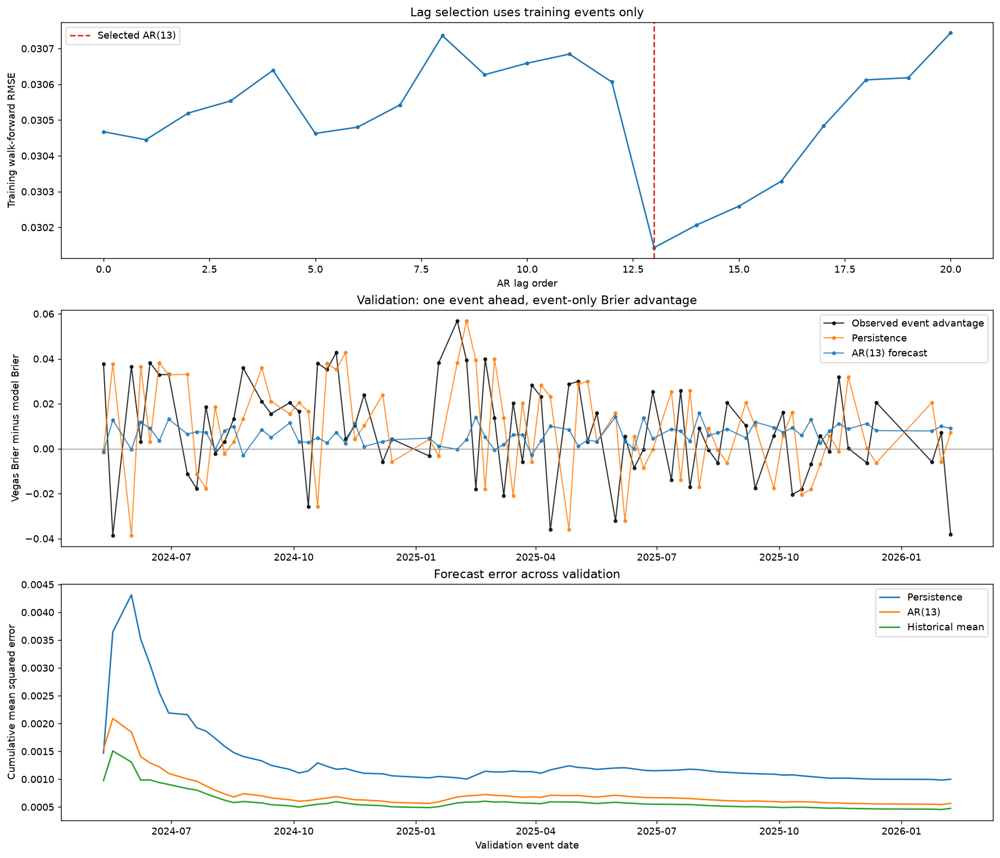

In [1]:
# Forecast unsmoothed event-only advantage, with AR order selected on training only.
AR_MAX_LAG = 20
AR_INITIAL_TRAIN_EVENTS = max(100, int(len(training_event_advantage) * .6))

def event_ar_forecast(history, lag, hold_back=AR_MAX_LAG):
    values = np.asarray(history, dtype=float)
    if lag == 0:
        return float(values.mean())
    # Same estimation target dates for all positive lag orders.
    targets = np.arange(hold_back, len(values))
    design = np.column_stack([np.ones(len(targets))] + [values[targets-j] for j in range(1, lag+1)])
    coefficients = np.linalg.lstsq(design, values[targets], rcond=None)[0]
    next_design = np.r_[1., values[-np.arange(1, lag+1)]]
    return float(next_design @ coefficients)

ar_train_values = training_event_advantage.brier_advantage.to_numpy()
ar_selection_records = []
for lag in range(AR_MAX_LAG+1):
    predictions = np.array([event_ar_forecast(ar_train_values[:i], lag)
        for i in range(AR_INITIAL_TRAIN_EVENTS, len(ar_train_values))])
    errors = predictions - ar_train_values[AR_INITIAL_TRAIN_EVENTS:]
    ar_selection_records.append({'lag': lag, 'RMSE': np.sqrt(np.mean(errors**2)),
                                 'MAE': np.mean(abs(errors)), 'events': len(errors)})
ar_selection = pd.DataFrame(ar_selection_records)
ar_selected_lag = int(ar_selection.sort_values(['RMSE','lag']).iloc[0].lag)

ar_val_fights = pd.read_csv(training_event_source.with_name('val_with_open.csv'), parse_dates=['date'])
ar_val_fights['date'] = ar_val_fights.date.dt.normalize()
ar_model = pd.to_numeric(ar_val_fights.proba_red, errors='coerce')
ar_red = pd.to_numeric(ar_val_fights.dec_open_red, errors='coerce')
ar_blue = pd.to_numeric(ar_val_fights.dec_open_blue, errors='coerce')
ar_valid = (ar_val_fights.winner.isin([0,1]) & ar_model.between(0,1)
    & np.isfinite(ar_red) & np.isfinite(ar_blue) & ar_red.gt(1) & ar_blue.gt(1))
ar_vegas = (1/ar_red)/(1/ar_red+1/ar_blue)
ar_val_scores = ar_val_fights.loc[ar_valid, ['date','winner']].copy()
ar_val_scores['advantage'] = ((ar_vegas-ar_val_fights.winner)**2 - (ar_model-ar_val_fights.winner)**2).loc[ar_valid]
ar_val_events = ar_val_scores.groupby('date').advantage.mean().sort_index()
assert training_event_advantage.index.max() < ar_val_events.index.min()
assert np.isfinite(ar_train_values).all() and np.isfinite(ar_val_events).all()

ar_history = list(ar_train_values)
ar_records = []
for date, actual in ar_val_events.items():
    # Forecast BEFORE appending this event's observed advantage.
    ar_records.append({'date': date, 'actual': actual,
        'AR': event_ar_forecast(ar_history, ar_selected_lag),
        'persistence': ar_history[-1], 'expanding_mean': np.mean(ar_history)})
    ar_history.append(actual)
ar_validation_forecasts = pd.DataFrame(ar_records).set_index('date')
np.testing.assert_allclose(ar_validation_forecasts.persistence,
    np.r_[ar_train_values[-1], ar_val_events.to_numpy()[:-1]])
np.testing.assert_allclose(ar_validation_forecasts.AR.iloc[0],
    event_ar_forecast(ar_train_values, ar_selected_lag))
ar_persistence_mse = np.mean((ar_validation_forecasts.persistence-ar_validation_forecasts.actual)**2)
ar_accuracy = pd.DataFrame([{
    'model': label, 'events': len(ar_validation_forecasts),
    'RMSE': np.sqrt(np.mean((ar_validation_forecasts[col]-ar_validation_forecasts.actual)**2)),
    'MAE': np.mean(abs(ar_validation_forecasts[col]-ar_validation_forecasts.actual)),
    'MSE_skill_vs_persistence': 1-np.mean((ar_validation_forecasts[col]-ar_validation_forecasts.actual)**2)/ar_persistence_mse,
    'advantage_sign_accuracy_pct': 100*np.mean(np.sign(ar_validation_forecasts[col]) == np.sign(ar_validation_forecasts.actual))
    } for col,label in [('persistence','Persistence'),('expanding_mean','Expanding historical mean'),('AR',f'AR({ar_selected_lag})')]])
print(f'Training-only lag selection: {AR_INITIAL_TRAIN_EVENTS} initial events, '
      f'{len(ar_train_values)-AR_INITIAL_TRAIN_EVENTS} chronological one-event-ahead scoring events.')
print(ar_selection.to_string(index=False, float_format=lambda x:f'{x:.6f}'))
print(f'Selected AR({ar_selected_lag}); order fixed during validation; coefficients refitted using only completed events.')
print(ar_accuracy.to_string(index=False, float_format=lambda x:f'{x:.6f}'))
print('RMSE and MAE are in Brier-advantage units; lower is better. Sign accuracy measures whether advantage is positive or negative.')
fig, axes = plt.subplots(3,1,figsize=(14,12),constrained_layout=True)
axes[0].plot(ar_selection.lag, ar_selection.RMSE, marker='.')
axes[0].axvline(ar_selected_lag, color='tab:red', linestyle='--', label=f'Selected AR({ar_selected_lag})')
axes[0].set(xlabel='AR lag order', ylabel='Training walk-forward RMSE', title='Lag selection uses training events only')
axes[0].legend()
for col,label,color in [('actual','Observed event advantage','black'),('persistence','Persistence','tab:orange'),('AR',f'AR({ar_selected_lag}) forecast','tab:blue')]:
    axes[1].plot(ar_validation_forecasts.index, ar_validation_forecasts[col],label=label,color=color,alpha=.8,marker='.',linewidth=1.2)
axes[1].axhline(0,color='gray',lw=.7)
axes[1].set(title='Validation: one event ahead, event-only Brier advantage',ylabel='Vegas Brier minus model Brier')
axes[1].legend()
for col,label in [('persistence','Persistence'),('AR',f'AR({ar_selected_lag})'),('expanding_mean','Historical mean')]:
    error=(ar_validation_forecasts[col]-ar_validation_forecasts.actual)**2
    axes[2].plot(error.index,error.expanding().mean(),label=label)
axes[2].set(xlabel='Validation event date',ylabel='Cumulative mean squared error',title='Forecast error across validation')
axes[2].legend()
plt.show()


### Prior-event normalized ACF of detrended rolling advantage versus returns

Uses the train-only opening inference probabilities and validation strategy event returns, with the same fight ordering as the earlier correlation analysis. The underlying advantage is still a **100-fight rolling mean sampled at event end**. Before each return event, take its preceding 128 event observations, linearly detrend that window, and compute normalized ACF at lags 1–20 **events**. ACF(k) = sum(residual[t] * residual[t-k]) / sum(residual[t]^2); ACF(0)=1 and is excluded because it is constant. This uses the same zero-lag normalization as the earlier ACF analysis, but on trailing event-sampled windows, not the full fight-indexed series. No current-event outcomes enter the feature.

Correlate each lag-specific ACF value with the subsequent event's unsmoothed bankroll return percentage, including singles and parlays. ACF describes similarity to earlier values, not the signed direction of the wave: negating a window leaves its ACF unchanged. The table, heatmap, correlation-by-lag plot, and selected scatter plots expose the full comparison. Intervals use 2,000 paired moving-block bootstrap resamples of 5 events; they are approximate pointwise intervals, not adjusted for searching 20 lags. The strongest observed lag is exploratory.


 lag_events  events  Pearson_r  Spearman_rho  Pearson_CI_low  Pearson_CI_high
          1      72    -0.0411       -0.0715         -0.2042           0.1661
          2      72     0.0654        0.0527         -0.0551           0.2135
          3      72     0.0311        0.0469         -0.0862           0.2114
          4      72     0.0098        0.0324         -0.1010           0.2028
          5      72    -0.0782       -0.0173         -0.1799           0.1436
          6      72    -0.1286       -0.0507         -0.2487           0.1101
          7      72    -0.1741       -0.0901         -0.3125           0.0512
          8      72    -0.1840       -0.0966         -0.3323           0.0400
          9      72    -0.1790       -0.0894         -0.3284           0.0381
         10      72    -0.1578       -0.0411         -0.3094           0.0609
         11      72    -0.1474       -0.0364         -0.2985           0.0712
         12      72    -0.1521       -0.0564         -0.2991    

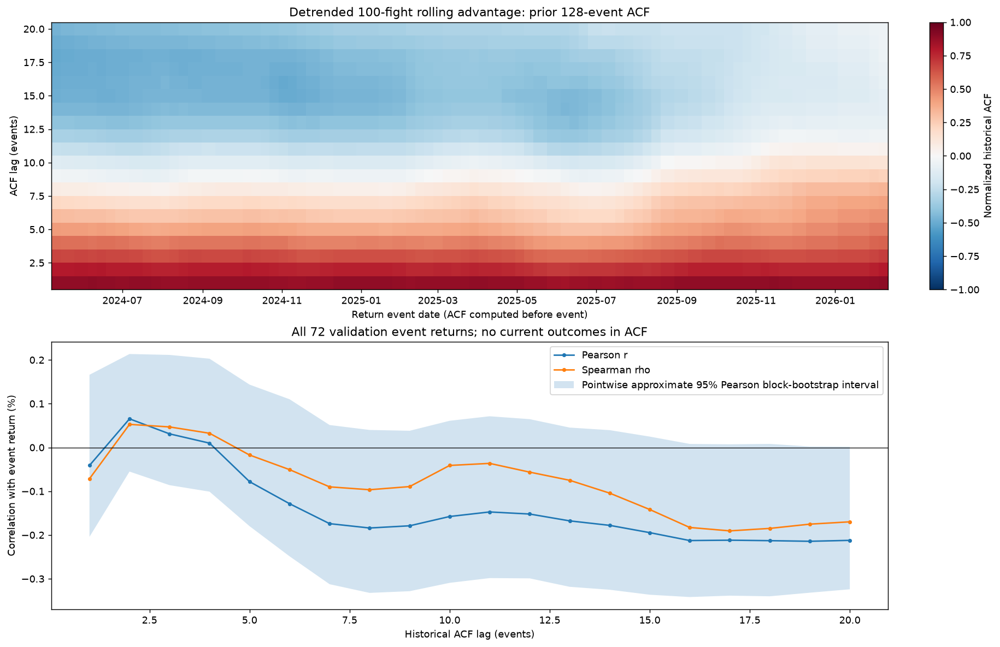

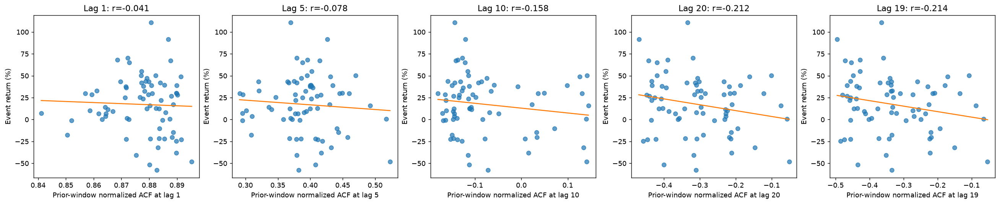

In [1]:
# Historical normalized ACF features; every window ends before its return event.
from scipy.signal import detrend
from scipy.stats import pearsonr, spearmanr
ACF_HISTORY_EVENTS = 128
ACF_MAX_LAG = 20
ACF_BOOTSTRAPS = 2000
ACF_BLOCK_EVENTS = 5
acf_feature_rows = []
for event_date in fft_returns.index:
    history = fft_event_series.loc[fft_event_series.index < event_date].iloc[-ACF_HISTORY_EVENTS:]
    if len(history) < ACF_HISTORY_EVENTS:
        continue
    residual = detrend(history.to_numpy(), type='linear')
    residual -= residual.mean()
    denominator = np.dot(residual, residual)
    if denominator <= 0:
        continue
    row = {'date': event_date, 'feature_date': history.index[-1]}
    for lag in range(1, ACF_MAX_LAG+1):
        row[f'acf_{lag}'] = np.dot(residual[:-lag], residual[lag:]) / denominator
    acf_feature_rows.append(row)
acf_return_pairs = pd.DataFrame(acf_feature_rows).set_index('date').join(fft_returns[['return_pct']]).dropna()
assert (acf_return_pairs.feature_date < acf_return_pairs.index).all()
# Common moving-block bootstrap samples retain local dependence in paired data.
acf_rng = np.random.default_rng(42)
acf_n = len(acf_return_pairs)
acf_block = min(ACF_BLOCK_EVENTS, acf_n)
acf_starts = acf_rng.integers(0, acf_n-acf_block+1,
    size=(ACF_BOOTSTRAPS, int(np.ceil(acf_n/acf_block))))
acf_boot_ids = (acf_starts[:,:,None] + np.arange(acf_block)).reshape(ACF_BOOTSTRAPS,-1)[:,:acf_n]
acf_records = []
for lag in range(1, ACF_MAX_LAG+1):
    x = acf_return_pairs[f'acf_{lag}'].to_numpy()
    y = acf_return_pairs.return_pct.to_numpy()
    bx, by = x[acf_boot_ids], y[acf_boot_ids]
    bx = bx-bx.mean(axis=1,keepdims=True); by = by-by.mean(axis=1,keepdims=True)
    denom = np.sqrt((bx*bx).sum(axis=1)*(by*by).sum(axis=1))
    boot = np.divide((bx*by).sum(axis=1),denom,out=np.full(ACF_BOOTSTRAPS,np.nan),where=denom>0)
    low, high = np.nanquantile(boot,[.025,.975])
    acf_records.append({'lag_events':lag,'events':acf_n,
        'Pearson_r':pearsonr(x,y).statistic,'Spearman_rho':spearmanr(x,y).statistic,
        'Pearson_CI_low':low,'Pearson_CI_high':high})
acf_return_correlations = pd.DataFrame(acf_records)
print(acf_return_correlations.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
acf_best_lag = int(acf_return_correlations.loc[acf_return_correlations.Pearson_r.abs().idxmax(),'lag_events'])
print(f'Largest absolute Pearson correlation among the 20 inspected lags: lag {acf_best_lag}. Exploratory selection, not independent validation.')
fig, axes = plt.subplots(2,1,figsize=(14,9),constrained_layout=True)
acf_matrix = acf_return_pairs[[f'acf_{lag}' for lag in range(1,ACF_MAX_LAG+1)]]
mesh = axes[0].pcolormesh(acf_matrix.index,np.arange(1,ACF_MAX_LAG+1),acf_matrix.to_numpy().T,
    shading='auto',cmap='RdBu_r',vmin=-1,vmax=1)
fig.colorbar(mesh,ax=axes[0],label='Normalized historical ACF')
axes[0].set(xlabel='Return event date (ACF computed before event)',ylabel='ACF lag (events)',title='Detrended 100-fight rolling advantage: prior 128-event ACF')
axes[1].plot(acf_return_correlations.lag_events,acf_return_correlations.Pearson_r,marker='.',label='Pearson r')
axes[1].plot(acf_return_correlations.lag_events,acf_return_correlations.Spearman_rho,marker='.',label='Spearman rho')
axes[1].fill_between(acf_return_correlations.lag_events,acf_return_correlations.Pearson_CI_low,
    acf_return_correlations.Pearson_CI_high,alpha=.2,label='Pointwise approximate 95% Pearson block-bootstrap interval')
axes[1].axhline(0,color='black',lw=.7)
axes[1].set(xlabel='Historical ACF lag (events)',ylabel='Correlation with event return (%)',title=f'All {acf_n} validation event returns; no current outcomes in ACF')
axes[1].legend();plt.show()
acf_scatter_lags = list(dict.fromkeys([1,5,10,20,acf_best_lag]))
fig, axes = plt.subplots(1,len(acf_scatter_lags),figsize=(4*len(acf_scatter_lags),4),constrained_layout=True)
for ax, lag in zip(np.atleast_1d(axes),acf_scatter_lags):
    x,y = acf_return_pairs[f'acf_{lag}'],acf_return_pairs.return_pct
    ax.scatter(x,y,alpha=.7)
    grid=np.linspace(x.min(),x.max(),100)
    ax.plot(grid,np.polyval(np.polyfit(x,y,1),grid),color='tab:orange')
    r=acf_return_correlations.set_index('lag_events').loc[lag,'Pearson_r']
    ax.set(xlabel=f'Prior-window normalized ACF at lag {lag}',ylabel='Event return (%)',title=f'Lag {lag}: r={r:.3f}')
plt.show()


### Previous event and rolling Brier advantage versus current event advantage

Here Brier means **Brier advantage (Vegas minus model)**, consistent with the preceding event-only forecast analysis. The target is the current event's equal-fight mean advantage. Predictors are the previous single event's mean and 15-, 25-, 50-, 75-, 100-, 125-, 150-, and 175-**fight** averages ending at the previous event. These are window lengths, not shifts of 15–175 events. No detrending. All nine comparisons use the same 72 validation events, with training fights seeding early windows and the train-only opening inference probabilities. Approximate 95% Pearson intervals use 2,000 paired moving-block bootstrap samples of 5 events; intervals are pointwise and descriptive.


            predictor  events  Pearson_r  Spearman_rho  Pearson_CI_low  Pearson_CI_high
Previous single event      72    -0.0951       -0.1065         -0.2854           0.1581
      Prior 15 fights      72    -0.0617       -0.0750         -0.2884           0.1855
      Prior 25 fights      72    -0.0543       -0.0442         -0.2040           0.1168
      Prior 50 fights      72    -0.0503       -0.0360         -0.2438           0.1292
      Prior 75 fights      72     0.0638        0.0788         -0.1332           0.2411
     Prior 100 fights      72     0.2017        0.2179          0.0057           0.3647
     Prior 125 fights      72     0.1772        0.1708         -0.0271           0.3175
     Prior 150 fights      72     0.1305        0.1317         -0.1514           0.3028
     Prior 175 fights      72     0.1616        0.1425         -0.0771           0.3312
All predictors end before the target event. Rolling windows count fights; target averages only the current event.


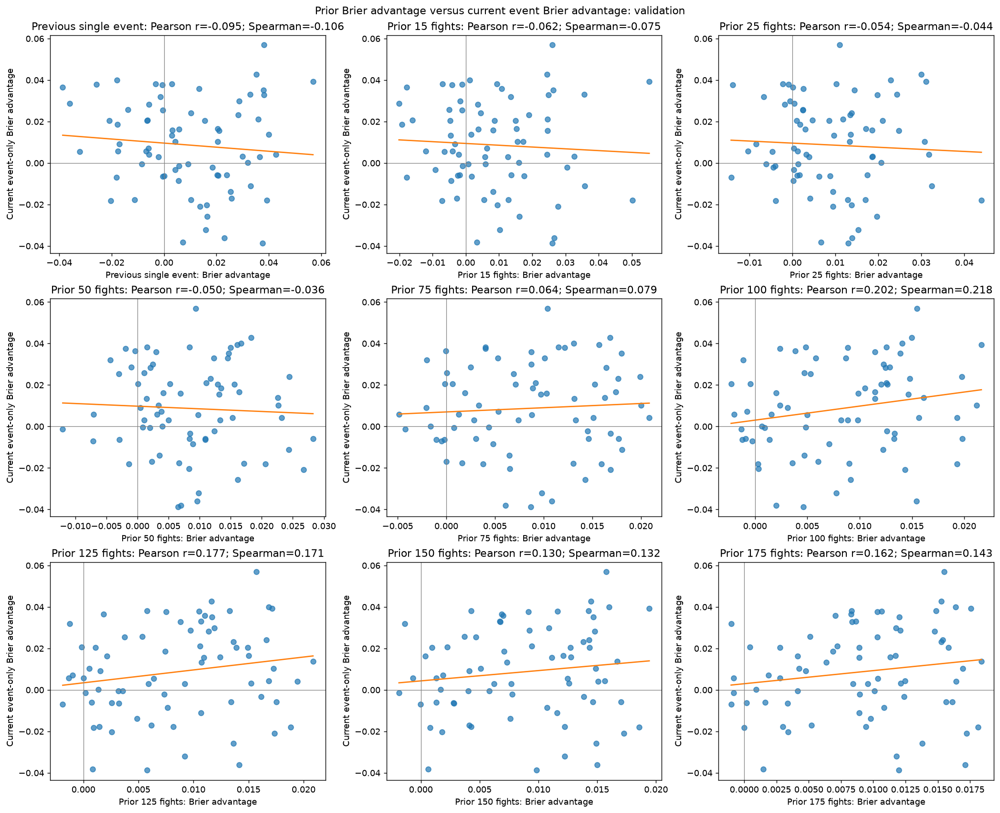

In [1]:
# Prior-event advantage versus current event-only advantage.
# Window lengths count fights, preserving the notebook's rolling-window convention.
PRIOR_ADVANTAGE_FIGHT_WINDOWS = [15, 25, 50, 75, 100, 125, 150, 175]
prior_advantage_event_target = fft_fights.groupby('date').advantage.mean().sort_index()
prior_advantage_features = pd.DataFrame(index=prior_advantage_event_target.index)
prior_advantage_features['Previous single event'] = prior_advantage_event_target.shift(1)
for window in PRIOR_ADVANTAGE_FIGHT_WINDOWS:
    rolling = fft_fights.advantage.rolling(window, min_periods=window).mean()
    endpoints = pd.DataFrame({'date':fft_fights.date, 'value':rolling}).groupby('date').value.last()
    prior_advantage_features[f'Prior {window} fights'] = endpoints.shift(1)
prior_advantage_features['feature_date'] = pd.Series(
    prior_advantage_event_target.index, index=prior_advantage_event_target.index).shift(1)
prior_advantage_pairs = prior_advantage_features.join(prior_advantage_event_target.rename('current_event_advantage'))
prior_advantage_pairs = prior_advantage_pairs.reindex(fft_returns.index).dropna()
assert (prior_advantage_pairs.feature_date < prior_advantage_pairs.index).all()
np.testing.assert_allclose(prior_advantage_pairs['Prior 100 fights'],
    fft_prior.raw_value.reindex(prior_advantage_pairs.index),atol=1e-12)
prior_advantage_labels = ['Previous single event'] + [f'Prior {w} fights' for w in PRIOR_ADVANTAGE_FIGHT_WINDOWS]
rng = np.random.default_rng(42)
n_pairs = len(prior_advantage_pairs)
block = min(5, n_pairs)
starts = rng.integers(0,n_pairs-block+1,size=(2000,int(np.ceil(n_pairs/block))))
bootstrap_ids = (starts[:,:,None]+np.arange(block)).reshape(2000,-1)[:,:n_pairs]
prior_advantage_records=[]
fig, axes = plt.subplots(3,3,figsize=(16,13),constrained_layout=True)
for ax,label in zip(axes.flat,prior_advantage_labels):
    x=prior_advantage_pairs[label].to_numpy()
    y=prior_advantage_pairs.current_event_advantage.to_numpy()
    r=pearsonr(x,y).statistic; rho=spearmanr(x,y).statistic
    a,b=x[bootstrap_ids],y[bootstrap_ids]
    a=a-a.mean(axis=1,keepdims=True); b=b-b.mean(axis=1,keepdims=True)
    denom=np.sqrt((a*a).sum(axis=1)*(b*b).sum(axis=1))
    draws=np.divide((a*b).sum(axis=1),denom,out=np.full(2000,np.nan),where=denom>0)
    lo,hi=np.nanquantile(draws,[.025,.975])
    prior_advantage_records.append({'predictor':label,'events':n_pairs,'Pearson_r':r,
        'Spearman_rho':rho,'Pearson_CI_low':lo,'Pearson_CI_high':hi})
    ax.scatter(x,y,alpha=.7)
    grid=np.linspace(x.min(),x.max(),100)
    ax.plot(grid,np.polyval(np.polyfit(x,y,1),grid),color='tab:orange')
    ax.axhline(0,color='gray',lw=.7); ax.axvline(0,color='gray',lw=.7)
    ax.set(xlabel=f'{label}: Brier advantage',ylabel='Current event-only Brier advantage',
           title=f'{label}: Pearson r={r:.3f}; Spearman={rho:.3f}')
fig.suptitle('Prior Brier advantage versus current event Brier advantage: validation')
plt.show()
prior_advantage_correlations=pd.DataFrame(prior_advantage_records)
print(prior_advantage_correlations.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
print('All predictors end before the target event. Rolling windows count fights; target averages only the current event.')


### Prior exponentially weighted Brier advantage versus current event advantage

Same 72 validation events, train-only opening inference model, training-fight warmup, and within-event fight ordering as the simple-average comparison. Compute EWMA on per-fight Vegas-minus-model Brier advantage using spans **15, 25, 50, 75, 100, 125, 150, and 175 fights**, then sample at event end and shift to the next event. The target remains current event-only mean advantage, not returns. Previous-single-event advantage remains the baseline.

Use `alpha = 2/(span+1)` and `EWMA[t] = alpha*advantage[t] + (1-alpha)*EWMA[t-1]`, initialized at the first eligible training fight (`adjust=False`). A span is a decay setting, not a hard cutoff: older fights retain diminishing weight. Require at least span observations before reporting a value. Intervals use the same 2,000 paired 5-event moving-block bootstrap samples; they are approximate pointwise intervals, without adjustment for inspecting multiple spans.


            predictor  events  Pearson_r  Spearman_rho  Pearson_CI_low  Pearson_CI_high
Previous single event      72    -0.0951       -0.1065         -0.2854           0.1581
  EWMA span 15 fights      72    -0.1337       -0.1225         -0.3097           0.1193
  EWMA span 25 fights      72    -0.1026       -0.1152         -0.2825           0.1295
  EWMA span 50 fights      72    -0.0422       -0.0340         -0.2374           0.1544
  EWMA span 75 fights      72     0.0073        0.0281         -0.1982           0.1917
 EWMA span 100 fights      72     0.0429        0.0560         -0.1738           0.2183
 EWMA span 125 fights      72     0.0667        0.0791         -0.1573           0.2385
 EWMA span 150 fights      72     0.0821        0.0970         -0.1470           0.2508
 EWMA span 175 fights      72     0.0918        0.1118         -0.1402           0.2586
All predictors end before the target event. EWMA spans count fights; target averages only the current event.


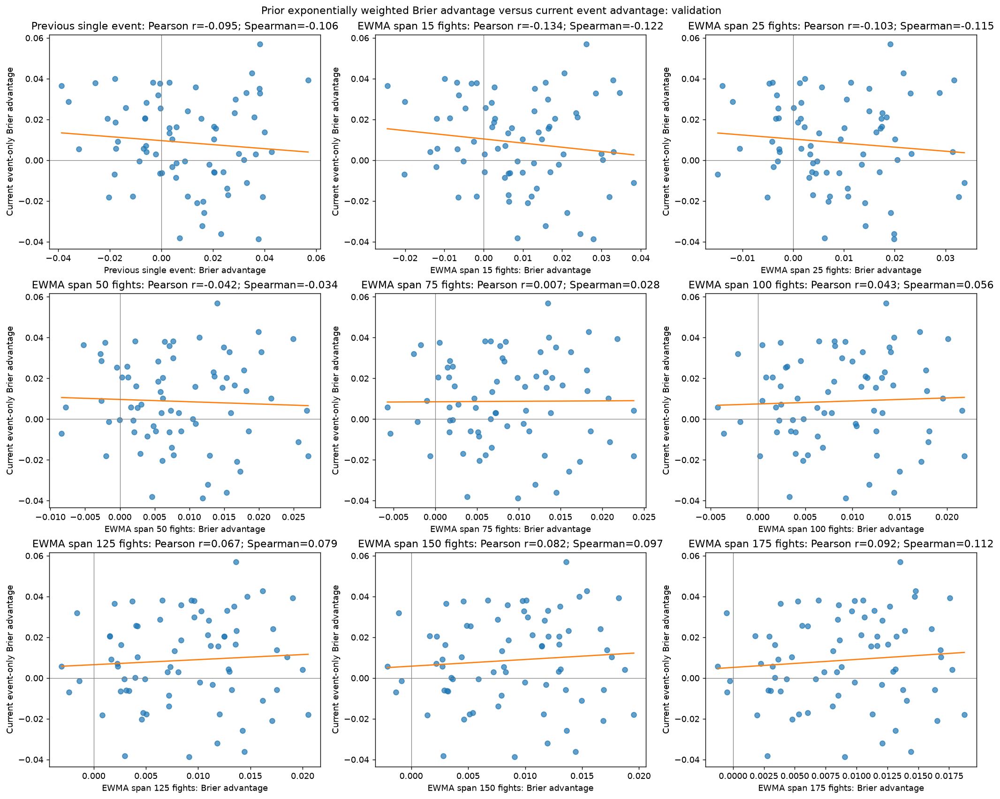

In [1]:
# Prior-event advantage versus current event-only advantage.
# Spans count fights; alpha = 2 / (span + 1), adjust=False; initialized from training history.
EWM_ADVANTAGE_FIGHT_SPANS = [15, 25, 50, 75, 100, 125, 150, 175]
ewm_advantage_event_target = fft_fights.groupby('date').advantage.mean().sort_index()
ewm_advantage_features = pd.DataFrame(index=ewm_advantage_event_target.index)
ewm_advantage_features['Previous single event'] = ewm_advantage_event_target.shift(1)
for window in EWM_ADVANTAGE_FIGHT_SPANS:
    rolling = fft_fights.advantage.ewm(span=window, adjust=False, min_periods=window).mean()
    endpoints = pd.DataFrame({'date':fft_fights.date, 'value':rolling}).groupby('date').value.last()
    ewm_advantage_features[f'EWMA span {window} fights'] = endpoints.shift(1)
ewm_advantage_features['feature_date'] = pd.Series(
    ewm_advantage_event_target.index, index=ewm_advantage_event_target.index).shift(1)
ewm_advantage_pairs = ewm_advantage_features.join(ewm_advantage_event_target.rename('current_event_advantage'))
ewm_advantage_pairs = ewm_advantage_pairs.reindex(fft_returns.index).dropna()
assert (ewm_advantage_pairs.feature_date < ewm_advantage_pairs.index).all()
assert len(ewm_advantage_pairs) == len(fft_returns)
# Check the recursion independently for span 100, including prior-event alignment.
values = fft_fights.advantage.to_numpy()
manual = np.empty(len(values)); manual[0] = values[0]
alpha = 2 / 101
for j in range(1, len(values)):
    manual[j] = alpha * values[j] + (1-alpha) * manual[j-1]
manual_prior = pd.DataFrame({'date': fft_fights.date, 'value': manual}).groupby('date').value.last().shift(1)
np.testing.assert_allclose(ewm_advantage_pairs['EWMA span 100 fights'],
    manual_prior.reindex(ewm_advantage_pairs.index), atol=1e-12)
ewm_advantage_labels = ['Previous single event'] + [f'EWMA span {w} fights' for w in EWM_ADVANTAGE_FIGHT_SPANS]
rng = np.random.default_rng(42)
n_pairs = len(ewm_advantage_pairs)
block = min(5, n_pairs)
starts = rng.integers(0,n_pairs-block+1,size=(2000,int(np.ceil(n_pairs/block))))
bootstrap_ids = (starts[:,:,None]+np.arange(block)).reshape(2000,-1)[:,:n_pairs]
ewm_advantage_records=[]
fig, axes = plt.subplots(3,3,figsize=(16,13),constrained_layout=True)
for ax,label in zip(axes.flat,ewm_advantage_labels):
    x=ewm_advantage_pairs[label].to_numpy()
    y=ewm_advantage_pairs.current_event_advantage.to_numpy()
    r=pearsonr(x,y).statistic; rho=spearmanr(x,y).statistic
    a,b=x[bootstrap_ids],y[bootstrap_ids]
    a=a-a.mean(axis=1,keepdims=True); b=b-b.mean(axis=1,keepdims=True)
    denom=np.sqrt((a*a).sum(axis=1)*(b*b).sum(axis=1))
    draws=np.divide((a*b).sum(axis=1),denom,out=np.full(2000,np.nan),where=denom>0)
    lo,hi=np.nanquantile(draws,[.025,.975])
    ewm_advantage_records.append({'predictor':label,'events':n_pairs,'Pearson_r':r,
        'Spearman_rho':rho,'Pearson_CI_low':lo,'Pearson_CI_high':hi})
    ax.scatter(x,y,alpha=.7)
    grid=np.linspace(x.min(),x.max(),100)
    ax.plot(grid,np.polyval(np.polyfit(x,y,1),grid),color='tab:orange')
    ax.axhline(0,color='gray',lw=.7); ax.axvline(0,color='gray',lw=.7)
    ax.set(xlabel=f'{label}: Brier advantage',ylabel='Current event-only Brier advantage',
           title=f'{label}: Pearson r={r:.3f}; Spearman={rho:.3f}')
fig.suptitle('Prior exponentially weighted Brier advantage versus current event advantage: validation')
plt.show()
ewm_advantage_correlations=pd.DataFrame(ewm_advantage_records)
print(ewm_advantage_correlations.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
print('All predictors end before the target event. EWMA spans count fights; target averages only the current event.')


### Detrended Vegas Brier alone: prior simple averages versus current event

Uses actual no-vig opening **Vegas Brier alone**, not model advantage or percent returns. For each event, fit a linear trend to the previous 128 event-mean Vegas Brier scores (equal event weights) and evaluate that trend at the current event index. Subtract this historical trend estimate from each current fight's Vegas Brier score. Freeze those residuals as computed at that date; never revise them using later observations. Thus detrending is causal rather than a full-sample fit, and residual values can be negative.

The target is the current event's mean residual. Predictors are the previous single event's mean residual and simple averages of the latest 15, 25, 50, 75, 100, 125, 150, 175, 200, 225, and 250 **fight residuals**, ending at the previous event. Each residual in an average uses the trend available at its own event. Training history initializes both detrending and windows; all twelve comparisons use the same 72 validation events and original fight ordering. The first 128 historical events have no residual because the trend window is incomplete.

Intervals are approximate pointwise 95% Pearson intervals from 2,000 paired moving-block bootstrap samples of 5 events. They are not adjusted for multiple comparisons. Detrending and overlapping histories can themselves alter serial dependence; these describe this particular residual construction, not proof of an intrinsic market cycle.

The final line plot shows only current-event detrended Vegas Brier and the prior 175-fight mean of detrended Vegas Brier. The prior mean ends at the previous event; both lines use the same y-axis.


            predictor  events  Pearson_r  Spearman_rho  Pearson_CI_low  Pearson_CI_high
Previous single event      72     0.0214        0.0612         -0.1477           0.1924
      Prior 15 fights      72    -0.0360       -0.0155         -0.2329           0.1465
      Prior 25 fights      72    -0.0819       -0.0733         -0.2948           0.1008
      Prior 50 fights      72    -0.0190       -0.0058         -0.2536           0.1695
      Prior 75 fights      72     0.0363        0.0656         -0.1842           0.2478
     Prior 100 fights      72    -0.1356       -0.1144         -0.3431           0.0478
     Prior 125 fights      72    -0.1679       -0.1586         -0.3652           0.0273
     Prior 150 fights      72    -0.1789       -0.1378         -0.3137          -0.0284
     Prior 175 fights      72    -0.2163       -0.1726         -0.4068          -0.0231
     Prior 200 fights      72    -0.0899       -0.1050         -0.2691           0.1046
     Prior 225 fights      72   

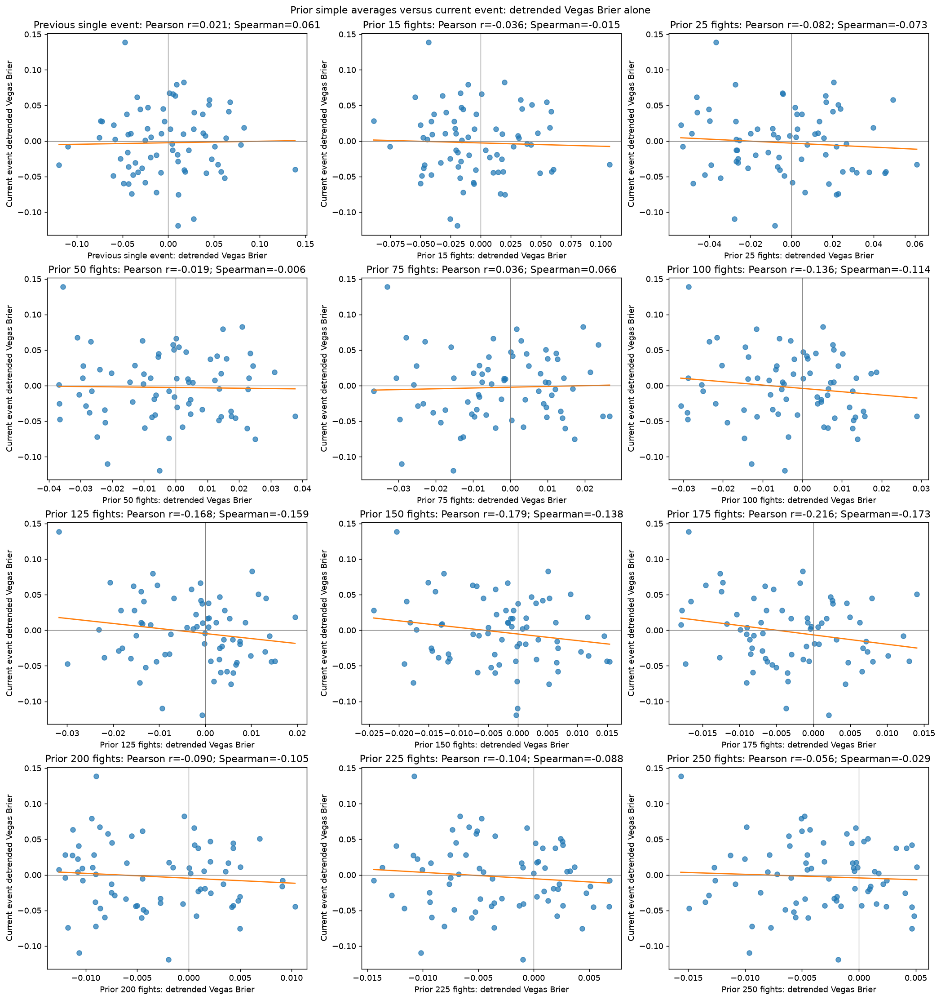

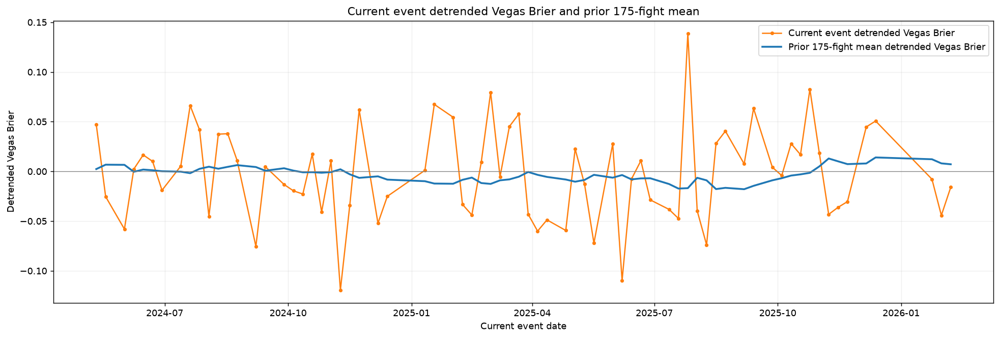

In [1]:
# Causal linear detrending of Vegas Brier before averaging across fights.
VEGAS_TREND_EVENTS = 128
DETRENDED_VEGAS_WINDOWS = [15,25,50,75,100,125,150,175,200,225,250]
dv_fights = fft_fights.copy()
dv_red = pd.to_numeric(dv_fights.dec_open_red)
dv_blue = pd.to_numeric(dv_fights.dec_open_blue)
dv_probability = (1/dv_red)/(1/dv_red+1/dv_blue)
dv_fights['vegas_brier'] = (dv_probability-dv_fights.winner)**2
dv_events = dv_fights.groupby('date',sort=True).vegas_brier.mean()
dv_trend = pd.Series(np.nan,index=dv_events.index,dtype=float)
dv_trend_source_date = pd.Series(pd.NaT,index=dv_events.index,dtype='datetime64[ns]')
dv_t = np.arange(VEGAS_TREND_EVENTS,dtype=float)
dv_design = np.column_stack([np.ones(VEGAS_TREND_EVENTS),dv_t])
for i in range(VEGAS_TREND_EVENTS,len(dv_events)):
    # Equal-event linear trend from past events only. Freeze each event's residual.
    coefficients = np.linalg.lstsq(dv_design,dv_events.iloc[i-VEGAS_TREND_EVENTS:i].to_numpy(),rcond=None)[0]
    dv_trend.iloc[i] = coefficients @ np.array([1.,VEGAS_TREND_EVENTS])
    dv_trend_source_date.iloc[i] = dv_events.index[i-1]
dv_fights['detrended_vegas'] = dv_fights.vegas_brier-dv_fights.date.map(dv_trend)
dv_target = dv_fights.groupby('date').detrended_vegas.mean()
np.testing.assert_allclose(dv_target.dropna(),(dv_events-dv_trend).dropna(),atol=1e-12)
dv_features = pd.DataFrame(index=dv_events.index)
dv_features['Previous single event'] = dv_target.shift(1)
for window in DETRENDED_VEGAS_WINDOWS:
    rolling = dv_fights.detrended_vegas.rolling(window,min_periods=window).mean()
    endpoint = pd.DataFrame({'date':dv_fights.date,'value':rolling}).groupby('date').value.last()
    dv_features[f'Prior {window} fights'] = endpoint.shift(1)
dv_features['feature_date'] = pd.Series(dv_events.index,index=dv_events.index).shift(1)
dv_pairs = dv_features.join(dv_target.rename('current_event_detrended_vegas')).reindex(fft_returns.index).dropna()
assert len(dv_pairs)==len(fft_returns)
assert (dv_pairs.feature_date < dv_pairs.index).all()
assert (dv_trend_source_date.reindex(dv_pairs.index) < dv_pairs.index).all()
# Future observations cannot enter a prior target's trend calculation.
check_i = dv_events.index.get_loc(dv_pairs.index[0])
check_coef = np.linalg.lstsq(dv_design,dv_events.iloc[check_i-VEGAS_TREND_EVENTS:check_i],rcond=None)[0]
np.testing.assert_allclose(dv_trend.loc[dv_pairs.index[0]],check_coef @ [1.,VEGAS_TREND_EVENTS])
dv_labels=['Previous single event']+[f'Prior {w} fights' for w in DETRENDED_VEGAS_WINDOWS]
rng=np.random.default_rng(42); count=len(dv_pairs); block=min(5,count)
starts=rng.integers(0,count-block+1,size=(2000,int(np.ceil(count/block))))
ids=(starts[:,:,None]+np.arange(block)).reshape(2000,-1)[:,:count]
dv_records=[]
fig,axes=plt.subplots(4,3,figsize=(16,17),constrained_layout=True)
for ax,label in zip(axes.flat,dv_labels):
    x=dv_pairs[label].to_numpy();y=dv_pairs.current_event_detrended_vegas.to_numpy()
    r=pearsonr(x,y).statistic;rho=spearmanr(x,y).statistic
    bx,by=x[ids],y[ids];bx=bx-bx.mean(axis=1,keepdims=True);by=by-by.mean(axis=1,keepdims=True)
    denom=np.sqrt((bx*bx).sum(axis=1)*(by*by).sum(axis=1))
    draws=np.divide((bx*by).sum(axis=1),denom,out=np.full(2000,np.nan),where=denom>0)
    lo,hi=np.nanquantile(draws,[.025,.975])
    dv_records.append({'predictor':label,'events':count,'Pearson_r':r,'Spearman_rho':rho,
        'Pearson_CI_low':lo,'Pearson_CI_high':hi})
    ax.scatter(x,y,alpha=.7)
    grid=np.linspace(x.min(),x.max(),100)
    ax.plot(grid,np.polyval(np.polyfit(x,y,1),grid),color='tab:orange')
    ax.axhline(0,color='gray',lw=.7);ax.axvline(0,color='gray',lw=.7)
    ax.set(xlabel=f'{label}: detrended Vegas Brier',ylabel='Current event detrended Vegas Brier',
        title=f'{label}: Pearson r={r:.3f}; Spearman={rho:.3f}')
fig.suptitle('Prior simple averages versus current event: detrended Vegas Brier alone')
plt.show()
detrended_vegas_correlations=pd.DataFrame(dv_records)
print(detrended_vegas_correlations.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
print('Trend: previous 128 event means only; each event residual frozen at its date. Windows count fights.')

# Current event detrended Vegas Brier and the prior 175-fight mean only.
fig, ax = plt.subplots(figsize=(15,5),constrained_layout=True)
ax.plot(dv_pairs.index,dv_pairs.current_event_detrended_vegas,
    color='tab:orange',linewidth=1.4,marker='.',label='Current event detrended Vegas Brier')
ax.plot(dv_pairs.index,dv_pairs['Prior 175 fights'],
    color='tab:blue',linewidth=2,label='Prior 175-fight mean detrended Vegas Brier')
ax.axhline(0,color='gray',linewidth=.7)
ax.set(title='Current event detrended Vegas Brier and prior 175-fight mean',
    xlabel='Current event date',ylabel='Detrended Vegas Brier')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.legend();ax.grid(alpha=.2)
plt.show()
